# Dysarthria V10 — complete, shareable research notebook

**Primary model:** waveform → frozen WavLM Base → temporal mean + SD → learned last-four-layer mixture → speaker attention → binary head. Five physical-speaker-safe TORGO seeds (42–46) preserve the V8 input and training recipe. M3 is the prespecified official UASpeech external channel.

This file contains the complete V10 implementation, saved results, paper tables, and embedded figure previews. No V10 `.py` file is required. The saved outputs are from the completed run; **Run All** recomputes them and requires the local TORGO, official UASpeech, frozen V8 reference, and model weights. Shared copies can be read without those data. Exported model checkpoints, vector PDFs, and source CSVs remain in `v10/outputs/` and `v10/publication/` for detailed reproduction.

The external result is a **locked zero-shot cross-corpus evaluation on official UASpeech**. Earlier versions studied UASpeech, so it is not a historically untouched prospective validation. V9 supplies diagnostics only; its fixed one-second/K=20 preprocessing is excluded from the primary pipeline.

## Embedded implementation

Each code cell below defines one in-memory module so the original research functions and their imports remain intact. The full source is visible in this notebook.

In [ ]:
from pathlib import Path
import sys
import types
from IPython.core.magic import register_cell_magic

# Set PROJECT_ROOT explicitly if the notebook is opened outside this project.
PROJECT_ROOT = None
location = Path(PROJECT_ROOT).expanduser().resolve() if PROJECT_ROOT else Path.cwd().resolve()
ROOT = location.parent if location.name == "v10" and (location.parent / "v8").is_dir() else location
if not (ROOT / "v8").is_dir() and (ROOT.parent / "v8").is_dir():
    ROOT = ROOT.parent
package = types.ModuleType("v10")
package.__path__ = [str(ROOT / "v10")]
package.__package__ = "v10"
sys.modules["v10"] = package

@register_cell_magic
def v10_module(line, cell):
    name = line.strip()
    if not name.startswith("v10."):
        raise ValueError("Expected a v10 module name")
    module = types.ModuleType(name)
    module.__file__ = str(ROOT / (name.replace(".", "/") + ".py"))
    module.__package__ = "v10"
    module.__notebook_source__ = cell
    sys.modules[name] = module
    setattr(package, name.rsplit(".", 1)[-1], module)
    exec(compile(cell, module.__file__, "exec"), module.__dict__)

print("Project root:", ROOT)
print("V10 implementation is loaded from notebook cells")

### Frozen V8 model and input pipeline

Embedded module: `v10.v8_backbone`

In [ ]:
%%v10_module v10.v8_backbone
"""Frozen V8 model and preprocessing source for V10 reference reproduction.

Derived verbatim from the SHA256-verified frozen V8 notebook. Do not edit the
reference algorithms here; V10 analyses live in research.py.
"""


# ==== Frozen V8 notebook cell 2; source copied without algorithm changes ====
from __future__ import annotations

import copy
import hashlib
import json
import os
import random
import re
import tempfile
from dataclasses import asdict, dataclass, field
from pathlib import Path
from typing import Any

import librosa
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import torchaudio
from scipy.special import expit
from sklearn.metrics import (accuracy_score, average_precision_score,
                             balanced_accuracy_score, brier_score_loss,
                             confusion_matrix, f1_score, roc_auc_score)
from sklearn.model_selection import StratifiedGroupKFold
from torch import nn
from torch.nn import functional as F


# V10 path isolation is the sole adaptation to the copied V8 algorithm.
ROOT = Path(__file__).resolve().parents[1]
V8_DIR = ROOT / "v10"
OUT = V8_DIR / "outputs"
CACHE_ROOT = OUT / "cache" / "dysarthria_detection_v10"
PIPELINE_SIGNATURE = "v8_frozen_ssl_speaker_bag_1"
DATASET_HANDLE = "pranaykoppula/torgo-audio"
OFFICIAL_TORGO_ROSTER = {
    "F01", "F03", "F04", "M01", "M02", "M03", "M04", "M05",
    "FC01", "FC02", "FC03", "MC01", "MC02", "MC03", "MC04",
}
SESSION_PATTERN = re.compile(r"((?:FC|MC|F|M)\d{2})(?:S\d{2})?")
FOLDER_PATTERN = re.compile(r"wav_(headMic|arrayMic)_((?:FC|MC|F|M)\d{2}(?:S\d{2})?)")
ACOUSTIC_NAMES = (
    tuple(f"mfcc{i}_{stat}" for stat in ("mean", "std") for i in range(13))
    + tuple(f"{name}_{stat}" for name in ("rms", "zcr", "centroid", "bandwidth", "rolloff", "flatness")
            for stat in ("mean", "std"))
    + ("duration_seconds",)
)


def _env_bool(name: str, default: bool = False) -> bool:
    value = os.environ.get(name)
    return default if value is None else value.strip().lower() in {"1", "true", "yes", "on"}


@dataclass(frozen=True)
class Config:
    encoder_name: str = field(default_factory=lambda: os.environ.get("DYSARTHRIA_V8_ENCODER", "WAVLM_BASE"))
    use_fusion: bool = field(default_factory=lambda: _env_bool("DYSARTHRIA_V8_FUSION"))
    dataset_path: str | None = field(default_factory=lambda: os.environ.get("TORGO_DATASET_PATH") or None)
    seeds: tuple[int, ...] = (42, 43, 44, 45, 46)
    outer_folds: int = 5
    inner_folds: int = 3
    sample_rate: int = 16_000
    max_seconds: float = 12.0
    encoder_batch_size: int = 4
    selected_layers: int = 4
    max_utterances_per_bag: int = 64
    bags_per_epoch: int = 4
    max_epochs: int = 40
    patience: int = 10
    learning_rate: float = 3e-4
    weight_decay: float = 1e-3

    def validate(self) -> None:
        if self.encoder_name not in {"WAVLM_BASE", "HUBERT_BASE"}:
            raise ValueError("encoder_name must be WAVLM_BASE or HUBERT_BASE")
        if self.sample_rate != 16_000:
            raise ValueError("The pretrained bundles require 16 kHz audio")
        if self.outer_folds < 2 or self.inner_folds < 2 or not self.seeds:
            raise ValueError("At least two folds and one seed are required")
        for name in ("encoder_batch_size", "selected_layers", "max_utterances_per_bag",
                     "bags_per_epoch", "max_epochs", "patience"):
            if getattr(self, name) < 1:
                raise ValueError(f"{name} must be positive")
        if self.max_seconds <= 0 or self.learning_rate <= 0:
            raise ValueError("max_seconds and learning_rate must be positive")


def _canonical_hash(value: Any) -> str:
    payload = json.dumps(value, sort_keys=True, separators=(",", ":"), default=str)
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()


def _file_sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def _atomic_json(path: Path, data: Any) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile("w", dir=path.parent, suffix=".tmp", delete=False, encoding="utf-8") as handle:
        json.dump(data, handle, indent=2, sort_keys=True, default=str)
        temp = Path(handle.name)
    os.replace(temp, path)


def _atomic_npz(path: Path, **arrays: np.ndarray) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(dir=path.parent, suffix=".npz", delete=False) as handle:
        temp = Path(handle.name)
    try:
        np.savez_compressed(temp, **arrays)
        os.replace(temp, path)
    finally:
        temp.unlink(missing_ok=True)


def _atomic_torch(path: Path, state: Any) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(dir=path.parent, suffix=".pt", delete=False) as handle:
        temp = Path(handle.name)
    try:
        torch.save(state, temp)
        os.replace(temp, path)
    finally:
        temp.unlink(missing_ok=True)


def _atomic_csv(path: Path, frame: pd.DataFrame) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile("w", dir=path.parent, suffix=".csv", delete=False,
                                     encoding="utf-8") as handle:
        frame.to_csv(handle, index=False)
        temp = Path(handle.name)
    os.replace(temp, path)


# ==== Frozen V8 notebook cell 5; source copied without algorithm changes ====
def resolve_dataset_root(config: Config) -> Path:
    """Use an explicit raw path or an existing KaggleHub copy before downloading."""
    if config.dataset_path:
        root = Path(config.dataset_path).expanduser().resolve()
    else:
        cache_base = Path(os.environ.get("KAGGLEHUB_CACHE", Path.home() / ".cache" / "kagglehub"))
        versions = cache_base / "datasets" / "pranaykoppula" / "torgo-audio" / "versions"
        local = [path for path in versions.iterdir() if path.is_dir()] if versions.is_dir() else []
        if local:
            root = sorted(local, key=lambda path: (int(path.name) if path.name.isdigit() else -1, path.name))[-1].resolve()
        else:
            import kagglehub
            root = Path(kagglehub.dataset_download(DATASET_HANDLE)).resolve()
    if not root.is_dir():
        raise FileNotFoundError(f"TORGO root does not exist: {root}")
    return root

def inventory_dataset(root: Path, *, expected_full: bool = True) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Independently parse and check raw WAVs; never read an older manifest."""
    rows: list[dict[str, Any]] = []
    issues: list[dict[str, str]] = []
    paths = sorted(root.rglob("*.wav"))
    if not paths:
        raise FileNotFoundError(f"No WAV files found under {root}")
    for path in paths:
        rel = path.relative_to(root).as_posix()
        group = path.parent.parent.name
        match = FOLDER_PATTERN.fullmatch(path.parent.name)
        if group not in {"F_Dys", "F_Con", "M_Dys", "M_Con"} or not match:
            issues.append({"file_path": str(path), "reason": "unexpected_group_or_session_folder"})
            continue
        mic, session = match.groups()
        sm = SESSION_PATTERN.fullmatch(session)
        physical = sm.group(1) if sm else None
        label = 0 if group.endswith("Con") else 1
        gender = "female" if group.startswith("F") else "male"
        if (physical not in OFFICIAL_TORGO_ROSTER
                or ("C" in physical) != (label == 0)
                or physical.startswith("F") != (gender == "female")
                or not path.name.startswith(path.parent.name + "_")):
            issues.append({"file_path": str(path), "reason": "speaker_label_path_disagreement"})
            continue
        try:
            info = sf.info(path)
            if info.frames <= 0 or info.samplerate <= 0:
                raise ValueError("empty or invalid WAV")
            # sf.info may accept a header whose sample data cannot be decoded.
            with sf.SoundFile(path) as wav:
                wav.read(frames=min(1024, info.frames), dtype="float32")
        except Exception as exc:
            issues.append({"file_path": str(path), "reason": f"audio_decode_failed: {exc}"})
            continue
        stat = path.stat()
        source_id = _canonical_hash((rel, stat.st_size, stat.st_mtime_ns))
        rows.append(dict(file_path=str(path), relative_path=rel, source_id=source_id,
                         speaker_id=session, physical_speaker_id=physical,
                         label=label, gender=gender, mic_type="head" if mic == "headMic" else "array",
                         source_size=stat.st_size, source_mtime_ns=stat.st_mtime_ns,
                         source_sample_rate=int(info.samplerate), source_frames=int(info.frames),
                         source_seconds=float(info.duration)))
    meta = pd.DataFrame(rows).sort_values("relative_path").reset_index(drop=True)
    issue_df = pd.DataFrame(issues, columns=["file_path", "reason"])
    if meta.empty:
        raise RuntimeError("No usable TORGO audio after independent verification")
    observed = set(meta.physical_speaker_id)
    if expected_full and observed != OFFICIAL_TORGO_ROSTER:
        raise AssertionError(f"TORGO roster mismatch: missing={sorted(OFFICIAL_TORGO_ROSTER-observed)}, extra={sorted(observed-OFFICIAL_TORGO_ROSTER)}")
    if meta.groupby("physical_speaker_id").label.nunique().max() != 1:
        raise AssertionError("A physical speaker has conflicting diagnosis labels")
    return meta, issue_df


def source_signature(meta: pd.DataFrame) -> str:
    return _canonical_hash(meta[["relative_path", "source_id", "label", "physical_speaker_id"]].to_dict("records"))


# ==== Frozen V8 notebook cell 11; source copied without algorithm changes ====
def choose_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def _capture_rng_state(device: torch.device) -> dict[str, Any]:
    state: dict[str, Any] = {"cpu": torch.get_rng_state()}
    if device.type == "cuda":
        state["cuda"] = torch.cuda.get_rng_state_all()
    elif device.type == "mps":
        state["mps"] = torch.mps.get_rng_state()
    return state


def _restore_rng_state(state: dict[str, Any], device: torch.device) -> None:
    torch.set_rng_state(state["cpu"].cpu())
    if device.type == "cuda" and "cuda" in state:
        torch.cuda.set_rng_state_all([item.cpu() for item in state["cuda"]])
    elif device.type == "mps" and "mps" in state:
        torch.mps.set_rng_state(state["mps"].cpu())


def load_pretrained(config: Config, pretrained_dir: Path, device: torch.device):
    """Get weights in the v8 namespace and fingerprint the exact checkpoint."""
    bundle = getattr(torchaudio.pipelines, config.encoder_name)
    if int(bundle.sample_rate) != config.sample_rate:
        raise AssertionError("Pretrained model and waveform sample rates disagree")
    pretrained_dir.mkdir(parents=True, exist_ok=True)
    before = set(pretrained_dir.iterdir())
    model = bundle.get_model(dl_kwargs={"model_dir": str(pretrained_dir)})
    after = set(pretrained_dir.iterdir())
    weight_files = sorted(p for p in after if p.is_file() and p.suffix in {".pth", ".pt"})
    if len(weight_files) != 1:
        raise RuntimeError(f"Expected one v8-local pretrained weight file, found {weight_files}; new files={after-before}")
    weight_sha = _file_sha256(weight_files[0])
    model.eval().to(device)
    for param in model.parameters():
        param.requires_grad_(False)
    return model, weight_sha, weight_files[0]


def preprocess_waveform(path: Path, mic_type: str, config: Config) -> np.ndarray:
    audio, sr = sf.read(path, dtype="float32", always_2d=True)
    mono = audio.mean(axis=1)
    if sr != config.sample_rate:
        mono = librosa.resample(mono, orig_sr=sr, target_sr=config.sample_rate)
    mono, _ = librosa.effects.trim(mono, top_db=35 if mic_type == "head" else 25)
    if len(mono) == 0:
        mono = np.zeros(config.sample_rate // 10, dtype=np.float32)
    peak = float(np.max(np.abs(mono)))
    if peak > 0:
        mono = mono / peak
    if mic_type == "array":
        mono = np.where(np.abs(mono) < .01, 0.0, mono)
    max_samples = int(config.max_seconds * config.sample_rate)
    if len(mono) > max_samples:
        start = (len(mono) - max_samples) // 2
        mono = mono[start:start + max_samples]
    if len(mono) < 1024:
        mono = np.pad(mono, (0, 1024 - len(mono)))
    mono = np.asarray(mono, dtype=np.float32)
    if not np.isfinite(mono).all():
        raise ValueError("Non-finite waveform after preprocessing")
    return mono


def acoustic_features(audio: np.ndarray, sr: int) -> np.ndarray:
    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=13)
    groups = [mfcc]
    for fn in (librosa.feature.rms, librosa.feature.zero_crossing_rate,
               librosa.feature.spectral_centroid, librosa.feature.spectral_bandwidth,
               librosa.feature.spectral_rolloff, librosa.feature.spectral_flatness):
        kwargs = {"y": audio}
        if fn in (librosa.feature.spectral_centroid, librosa.feature.spectral_bandwidth,
                  librosa.feature.spectral_rolloff):
            kwargs["sr"] = sr
        groups.append(fn(**kwargs))
    values = np.concatenate([np.concatenate([x.mean(axis=1), x.std(axis=1)]) for x in groups]
                            + [np.asarray([len(audio) / sr])]).astype(np.float32)
    if len(values) != len(ACOUSTIC_NAMES) or not np.isfinite(values).all():
        raise ValueError("Invalid engineered acoustic feature vector")
    return values


def masked_layer_statistics(layers: list[torch.Tensor], lengths: torch.Tensor,
                            selected_layers: int) -> np.ndarray:
    """Mean and SD of valid encoder frames for the last selected layers."""
    chosen = layers[-selected_layers:]
    if len(chosen) != selected_layers:
        raise ValueError("Encoder returned fewer layers than requested")
    output = []
    for layer in chosen:
        frame_count = layer.shape[1]
        mask = torch.arange(frame_count, device=layer.device)[None, :] < lengths[:, None]
        denom = mask.sum(dim=1).clamp_min(1).to(layer.dtype)[:, None]
        masked = layer * mask[..., None]
        mean = masked.sum(dim=1) / denom
        variance = (((layer - mean[:, None, :]) * mask[..., None]) ** 2).sum(dim=1) / denom
        output.append(torch.cat((mean, variance.clamp_min(0).sqrt()), dim=-1))
    stacked = torch.stack(output, dim=1).float().cpu().numpy()
    if not np.isfinite(stacked).all():
        raise ValueError("Non-finite pretrained speech embedding")
    return stacked


def _encode_batch(model: nn.Module, waveforms: list[np.ndarray], config: Config,
                  device: torch.device) -> np.ndarray:
    # Torchaudio 2.11's WavLM attention asserts that attention_mask is None.
    # Its Wav2Vec2Model builds that mask whenever lengths are supplied. Encode
    # each waveform unpadded so neither padded samples nor padded frames enter
    # the transformer or utterance statistics. HuBERT supports masked batches.
    if config.encoder_name == "WAVLM_BASE" and isinstance(model, torchaudio.models.Wav2Vec2Model):
        result = []
        with torch.inference_mode():
            for audio in waveforms:
                layers, _ = model.extract_features(torch.from_numpy(audio)[None, :].to(device))
                frame_lengths = torch.tensor([layers[-1].shape[1]], device=device)
                result.append(masked_layer_statistics(layers, frame_lengths, config.selected_layers)[0])
        return np.stack(result)
    lengths = torch.tensor([len(x) for x in waveforms], dtype=torch.long, device=device)
    padded = torch.zeros((len(waveforms), int(lengths.max())), dtype=torch.float32, device=device)
    for i, audio in enumerate(waveforms):
        padded[i, :len(audio)] = torch.from_numpy(audio).to(device)
    with torch.inference_mode():
        layers, frame_lengths = model.extract_features(padded, lengths=lengths)
        if frame_lengths is None:
            raise RuntimeError("Encoder did not return valid output lengths")
        return masked_layer_statistics(layers, frame_lengths, config.selected_layers)


def _feature_spec(config: Config, weight_sha: str) -> dict[str, Any]:
    return dict(pipeline_signature=PIPELINE_SIGNATURE, encoder=config.encoder_name,
                pretrained_weight_sha256=weight_sha, sample_rate=config.sample_rate,
                selected_layers=config.selected_layers, max_seconds=config.max_seconds,
                waveform_preprocessing="mono_resample_trim_normalize_array_gate_center_crop_v1",
                acoustic_recipe="mfcc13_rms_zcr_centroid_bandwidth_rolloff_flatness_duration_v1",
                torchaudio_version=torchaudio.__version__, librosa_version=librosa.__version__)


def _shard_path(shard_dir: Path, source_id: str, feature_hash: str) -> Path:
    key = _canonical_hash((source_id, feature_hash))
    return shard_dir / key[:2] / f"{key}.npz"


def extract_dataset_features(meta: pd.DataFrame, model: nn.Module, config: Config,
                             run_dir: Path, feature_spec: dict[str, Any],
                             device: torch.device) -> tuple[pd.DataFrame, np.ndarray, np.ndarray, pd.DataFrame]:
    """Resume per-WAV shards, then atomically publish a complete aggregate."""
    feature_hash = _canonical_hash(feature_spec)
    source_hash = source_signature(meta)
    aggregate = run_dir / "features"
    manifest_path = aggregate / "manifest.json"
    embedding_path = aggregate / "speech_embeddings.npy"
    acoustic_path = aggregate / "acoustic_features.npy"
    usable_path = aggregate / "usable_metadata.csv"
    if manifest_path.is_file():
        manifest = json.loads(manifest_path.read_text())
        if (manifest.get("complete") is True and manifest.get("source_signature") == source_hash
                and manifest.get("feature_signature") == feature_hash
                and all(p.is_file() for p in (embedding_path, acoustic_path, usable_path))):
            usable = pd.read_csv(usable_path)
            embedding = np.load(embedding_path, mmap_mode="r")
            acoustic = np.load(acoustic_path, mmap_mode="r")
            if len(usable) == len(embedding) == len(acoustic) == manifest["n_usable"]:
                return usable, embedding, acoustic, pd.DataFrame(manifest.get("extraction_errors", []))
    aggregate.mkdir(parents=True, exist_ok=True)
    shard_dir = run_dir / "embedding_shards"
    pending: list[tuple[int, pd.Series, Path]] = []
    errors: list[dict[str, str]] = []
    for i, row in meta.iterrows():
        shard = _shard_path(shard_dir, row.source_id, feature_hash)
        if shard.is_file():
            try:
                with np.load(shard) as saved:
                    if (str(saved["source_id"].item()) == row.source_id
                            and saved["embedding"].shape[0] == config.selected_layers
                            and saved["acoustic"].shape == (len(ACOUSTIC_NAMES),)
                            and np.isfinite(saved["embedding"]).all()
                            and np.isfinite(saved["acoustic"]).all()):
                        continue
            except Exception:
                pass
        pending.append((i, row, shard))
    print(f"V8 feature extraction: {len(meta)-len(pending)} cached shards, {len(pending)} new WAVs", flush=True)
    for offset in range(0, len(pending), config.encoder_batch_size):
        batch = pending[offset:offset + config.encoder_batch_size]
        ready: list[tuple[pd.Series, Path, np.ndarray, np.ndarray]] = []
        for _, row, shard in batch:
            try:
                audio = preprocess_waveform(Path(row.file_path), row.mic_type, config)
                acoustic = acoustic_features(audio, config.sample_rate)
                ready.append((row, shard, audio, acoustic))
            except Exception as exc:
                errors.append(dict(file_path=row.file_path, reason=f"preprocess_failed: {exc}"))
        if ready:
            try:
                embeddings = _encode_batch(model, [item[2] for item in ready], config, device)
            except RuntimeError as exc:
                if "out of memory" not in str(exc).lower() or len(ready) == 1:
                    raise
                if device.type == "cuda":
                    torch.cuda.empty_cache()
                embeddings = np.stack([_encode_batch(model, [item[2]], config, device)[0]
                                       for item in ready])
            for (row, shard, _, acoustic), embedding in zip(ready, embeddings):
                _atomic_npz(shard, embedding=embedding.astype(np.float32),
                            acoustic=acoustic, source_id=np.asarray(row.source_id))
        if (offset // config.encoder_batch_size + 1) % 100 == 0 or offset + len(batch) >= len(pending):
            print(f"V8 encoded {min(offset+len(batch), len(pending))}/{len(pending)} pending WAVs", flush=True)
    kept: list[int] = []
    for i, row in meta.iterrows():
        if _shard_path(shard_dir, row.source_id, feature_hash).is_file():
            kept.append(i)
        elif not any(e["file_path"] == row.file_path for e in errors):
            errors.append(dict(file_path=row.file_path, reason="embedding_shard_missing"))
    if not kept:
        raise RuntimeError("No V8 feature shards were produced")
    usable = meta.iloc[kept].reset_index(drop=True)
    first_shard = _shard_path(shard_dir, usable.iloc[0].source_id, feature_hash)
    with np.load(first_shard) as first:
        embed_shape = first["embedding"].shape
    embedding_temp = aggregate / "speech_embeddings.partial.npy"
    acoustic_temp = aggregate / "acoustic_features.partial.npy"
    embeddings = np.lib.format.open_memmap(embedding_temp, mode="w+", dtype="float32",
                                            shape=(len(usable),) + embed_shape)
    acoustics = np.lib.format.open_memmap(acoustic_temp, mode="w+", dtype="float32",
                                           shape=(len(usable), len(ACOUSTIC_NAMES)))
    for i, row in usable.iterrows():
        with np.load(_shard_path(shard_dir, row.source_id, feature_hash)) as shard:
            embeddings[i] = shard["embedding"]
            acoustics[i] = shard["acoustic"]
    embeddings.flush(); acoustics.flush()
    del embeddings, acoustics
    os.replace(embedding_temp, embedding_path)
    os.replace(acoustic_temp, acoustic_path)
    usable.to_csv(usable_path, index=False)
    _atomic_json(manifest_path, dict(complete=True, pipeline_signature=PIPELINE_SIGNATURE,
                                     source_signature=source_hash, feature_signature=feature_hash,
                                     feature_spec=feature_spec, n_usable=len(usable),
                                     embedding_shape=(len(usable),) + embed_shape,
                                     acoustic_names=ACOUSTIC_NAMES,
                                     extraction_errors=errors))
    return usable, np.load(embedding_path, mmap_mode="r"), np.load(acoustic_path, mmap_mode="r"), pd.DataFrame(errors)


# ==== Frozen V8 notebook cell 13; source copied without algorithm changes ====
def speaker_table(meta: pd.DataFrame) -> pd.DataFrame:
    table = (meta.groupby("physical_speaker_id", sort=True)
             .agg(label=("label", "first"), n_utterances=("label", "size"))
             .reset_index())
    if meta.groupby("physical_speaker_id").label.nunique().max() != 1:
        raise AssertionError("Conflicting labels within a physical speaker")
    return table


def grouped_speaker_splits(meta: pd.DataFrame, seed: int, folds: int):
    table = speaker_table(meta)
    if table.label.value_counts().min() < folds:
        raise ValueError(f"Need at least {folds} physical speakers per class")
    splitter = StratifiedGroupKFold(n_splits=folds, shuffle=True, random_state=seed)
    seen: set[str] = set()
    for fold, (train, test) in enumerate(splitter.split(table, table.label, table.physical_speaker_id)):
        train_ids = set(table.iloc[train].physical_speaker_id)
        test_ids = set(table.iloc[test].physical_speaker_id)
        if train_ids & test_ids or seen & test_ids:
            raise AssertionError("Physical speaker appears in more than one partition")
        seen |= test_ids
        yield fold, train_ids, test_ids
    if seen != set(table.physical_speaker_id):
        raise AssertionError("Some physical speakers were omitted from grouped folds")


def fit_acoustic_scaler(meta: pd.DataFrame, acoustic: np.ndarray,
                        train_speakers: set[str]) -> tuple[np.ndarray, np.ndarray]:
    """Fit on training speakers with one total unit of weight per speaker."""
    if not train_speakers:
        raise ValueError("No speakers provided for scaler fit")
    if not train_speakers.issubset(set(meta.physical_speaker_id)):
        raise ValueError("Unknown speaker in training scaler fit")
    means, second_moments = [], []
    for speaker in sorted(train_speakers):
        values = np.asarray(acoustic[np.flatnonzero(meta.physical_speaker_id.eq(speaker))], dtype=np.float64)
        means.append(values.mean(axis=0))
        second_moments.append(np.square(values).mean(axis=0))
    mean = np.mean(means, axis=0)
    variance = np.maximum(np.mean(second_moments, axis=0) - mean ** 2, 1e-8)
    return mean.astype(np.float32), np.sqrt(variance).astype(np.float32)


class SpeakerAttentionClassifier(nn.Module):
    """Trainable layer mix and utterance attention conditioned on bag context."""

    def __init__(self, layers: int, embedding_dim: int, acoustic_dim: int, use_fusion: bool):
        super().__init__()
        self.use_fusion = use_fusion
        self.layer_logits = nn.Parameter(torch.zeros(layers))
        self.speech_proj = nn.Sequential(nn.Linear(embedding_dim, 128), nn.LayerNorm(128),
                                         nn.GELU(), nn.Dropout(.2))
        self.attention = nn.Sequential(nn.Linear(128 * 3, 64), nn.Tanh(), nn.Linear(64, 1))
        if use_fusion:
            self.acoustic_proj = nn.Sequential(nn.Linear(acoustic_dim * 2, 64),
                                                nn.LayerNorm(64), nn.GELU())
        self.classifier = nn.Sequential(nn.Linear(256 + (64 if use_fusion else 0), 64),
                                        nn.GELU(), nn.Dropout(.2), nn.Linear(64, 1))

    def forward(self, speech: torch.Tensor, acoustic: torch.Tensor | None = None,
                valid_mask: torch.Tensor | None = None,
                return_attention: bool = False):
        if speech.ndim != 3 or speech.shape[0] == 0:
            raise ValueError("Expected one nonempty speaker bag [utterance, layer, feature]")
        if valid_mask is None:
            valid_mask = torch.ones(speech.shape[0], dtype=torch.bool, device=speech.device)
        if valid_mask.sum() == 0:
            raise ValueError("Speaker bag has no valid utterances")
        mix = torch.softmax(self.layer_logits, dim=0)
        utterance = self.speech_proj((speech * mix[None, :, None]).sum(dim=1))
        mask_f = valid_mask.to(utterance.dtype)[:, None]
        context = (utterance * mask_f).sum(dim=0) / mask_f.sum()
        expanded = context[None, :].expand_as(utterance)
        score = self.attention(torch.cat((utterance, expanded, utterance * expanded), dim=-1)).squeeze(-1)
        score = score.masked_fill(~valid_mask, torch.finfo(score.dtype).min)
        weight = torch.softmax(score, dim=0)
        pooled = torch.cat(((utterance * weight[:, None]).sum(dim=0), context), dim=0)
        if self.use_fusion:
            if acoustic is None or acoustic.shape[0] != speech.shape[0]:
                raise ValueError("Fusion requires aligned utterance acoustic features")
            acoustic_mean = (acoustic * mask_f).sum(dim=0) / mask_f.sum()
            acoustic_weighted = (acoustic * weight[:, None]).sum(dim=0)
            pooled = torch.cat((pooled, self.acoustic_proj(torch.cat((acoustic_weighted, acoustic_mean)))), dim=0)
        logit = self.classifier(pooled).squeeze(-1)
        return (logit, weight) if return_attention else logit


class BagStore:
    def __init__(self, meta: pd.DataFrame, speech: np.ndarray, acoustic: np.ndarray,
                 scaler: tuple[np.ndarray, np.ndarray], device: torch.device):
        self.meta = meta
        self.speech = speech
        self.acoustic = acoustic
        self.mean, self.scale = scaler
        self.device = device
        self.indices = {str(sp): np.flatnonzero(meta.physical_speaker_id.eq(sp))
                        for sp in meta.physical_speaker_id.unique()}
        self.labels = {str(sp): int(meta.iloc[ix[0]].label) for sp, ix in self.indices.items()}

    def bag(self, speaker: str, *, maximum: int | None = None,
            rng: np.random.Generator | None = None,
            explicit_indices: np.ndarray | None = None) -> tuple[torch.Tensor, torch.Tensor]:
        ix = self.indices[speaker]
        if explicit_indices is not None:
            if not np.isin(explicit_indices, ix).all():
                raise AssertionError("Bag includes another speaker's utterance")
            ix = explicit_indices
        elif maximum is not None and len(ix) > maximum:
            if rng is None:
                raise ValueError("Random generator required for training bag sampling")
            ix = np.sort(rng.choice(ix, size=maximum, replace=False))
        speech = torch.from_numpy(np.array(self.speech[ix], dtype=np.float32, copy=True)).to(self.device)
        acoustic = np.array(self.acoustic[ix], dtype=np.float32, copy=True)
        acoustic = (acoustic - self.mean) / self.scale
        acoustic = torch.from_numpy(acoustic).to(self.device)
        return speech, acoustic


def _new_head(config: Config, speech: np.ndarray, acoustic: np.ndarray,
              use_fusion: bool, device: torch.device) -> SpeakerAttentionClassifier:
    return SpeakerAttentionClassifier(speech.shape[1], speech.shape[2], acoustic.shape[1],
                                      use_fusion).to(device)


def predict_speakers(model: SpeakerAttentionClassifier, store: BagStore,
                     speakers: set[str], bag_size: int = 64) -> pd.DataFrame:
    """Score every utterance once in deterministic train-sized speaker bags."""
    if bag_size < 1:
        raise ValueError("bag_size must be positive")
    model.eval()
    rows = []
    with torch.no_grad():
        for speaker in sorted(speakers):
            indices = store.indices[speaker]
            seed = int.from_bytes(hashlib.sha256(speaker.encode("utf-8")).digest()[:8], "big")
            order = np.random.default_rng(seed).permutation(indices)
            weighted_logit = 0.0
            n_bags = 0
            for start in range(0, len(order), bag_size):
                part = order[start:start + bag_size]
                speech, acoustic = store.bag(speaker, explicit_indices=part)
                weighted_logit += float(model(speech, acoustic).item()) * len(part)
                n_bags += 1
            p = float(expit(weighted_logit / len(indices)))
            rows.append(dict(physical_speaker_id=speaker, label=store.labels[speaker],
                             probability=p, n_utterances=len(indices), n_eval_bags=n_bags))
    return pd.DataFrame(rows)


def _head_training_signature(config: Config, run_signature: str, use_fusion: bool,
                             train_speakers: set[str], val_speakers: set[str] | None,
                             epochs: int | None, seed: int) -> str:
    return _canonical_hash(dict(run_signature=run_signature, use_fusion=use_fusion,
                                train_speakers=sorted(train_speakers),
                                val_speakers=sorted(val_speakers or []), epochs=epochs,
                                seed=seed, max_epochs=config.max_epochs,
                                max_utterances_per_bag=config.max_utterances_per_bag,
                                bags_per_epoch=config.bags_per_epoch,
                                learning_rate=config.learning_rate,
                                weight_decay=config.weight_decay, patience=config.patience))


# ==== Frozen V8 notebook cell 16; source copied without algorithm changes ====
def train_head(config: Config, meta: pd.DataFrame, speech: np.ndarray,
               acoustic: np.ndarray, train_speakers: set[str],
               val_speakers: set[str] | None, *, use_fusion: bool,
               seed: int, run_signature: str, checkpoint_dir: Path,
               device: torch.device, epochs: int | None = None) -> tuple[SpeakerAttentionClassifier, int, BagStore]:
    """Train only on physical train speakers; resume at the next epoch."""
    if val_speakers and train_speakers & val_speakers:
        raise AssertionError("Train/validation physical speaker overlap")
    signature = _head_training_signature(config, run_signature, use_fusion, train_speakers,
                                         val_speakers, epochs, seed)
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    scaler_path = checkpoint_dir / "acoustic_scaler.npz"
    complete_path = checkpoint_dir / "complete.json"
    best_path = checkpoint_dir / "best.pt"
    latest_path = checkpoint_dir / "latest.pt"
    history_path = checkpoint_dir / "training_history.csv"
    history_columns = ("epoch", "train_logloss", "validation_logloss",
                       "validation_accuracy_0_5", "best_epoch",
                       "best_validation_logloss", "is_best", "history_status")

    def write_history(rows: list[dict[str, Any]]) -> None:
        _atomic_csv(history_path, pd.DataFrame(rows, columns=history_columns))

    def unavailable_history(last_epoch: int) -> list[dict[str, Any]]:
        # An older checkpoint cannot yield losses retrospectively.
        return [dict(epoch=i, train_logloss=None, validation_logloss=None,
                     validation_accuracy_0_5=None, best_epoch=None,
                     best_validation_logloss=None, is_best=None,
                     history_status="unavailable_prior_checkpoint")
                for i in range(1, last_epoch + 1)]

    scaler = fit_acoustic_scaler(meta, acoustic, train_speakers)
    store = BagStore(meta, speech, acoustic, scaler, device)
    if complete_path.is_file() and best_path.is_file() and scaler_path.is_file():
        complete = json.loads(complete_path.read_text())
        if complete.get("signature") == signature:
            if "history" in complete:
                # The completed checkpoint is authoritative if CSV was interrupted.
                write_history(complete["history"])
            elif latest_path.is_file():
                # A fold completed by the older runner has no historical losses.
                saved = torch.load(latest_path, map_location=device, weights_only=False)
                if saved.get("signature") == signature:
                    write_history(saved.get("history", unavailable_history(saved["epoch"])))
            set_seed(seed)
            model = _new_head(config, speech, acoustic, use_fusion, device)
            model.load_state_dict(torch.load(best_path, map_location=device, weights_only=True))
            return model, int(complete["best_epoch"]), store
    set_seed(seed)
    model = _new_head(config, speech, acoustic, use_fusion, device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=config.learning_rate,
                                  weight_decay=config.weight_decay)
    best_loss = float("inf")
    best_epoch = 0
    best_state = None
    bad_epochs = 0
    start_epoch = 1
    history: list[dict[str, Any]] = []
    if latest_path.is_file():
        saved = torch.load(latest_path, map_location=device, weights_only=False)
        if saved.get("signature") == signature:
            model.load_state_dict(saved["model"])
            optimizer.load_state_dict(saved["optimizer"])
            best_loss = saved["best_loss"]
            best_epoch = saved["best_epoch"]
            best_state = saved["best_state"]
            bad_epochs = saved["bad_epochs"]
            start_epoch = saved["epoch"] + 1
            if "history" in saved:
                history = saved["history"]
                if len(history) != saved["epoch"] or int(history[-1]["epoch"]) != saved["epoch"]:
                    raise RuntimeError(f"Checkpoint history is inconsistent: {latest_path}")
            else:
                # Earlier V8 checkpoints did not record losses. Show gaps, never
                # invent measurements, and continue from the saved model state.
                history = unavailable_history(saved["epoch"])
            write_history(history)
            _restore_rng_state(saved["rng_state"], device)
    limit = epochs if epochs is not None else config.max_epochs
    if start_epoch > limit and best_state is None:
        raise RuntimeError(f"Invalid checkpoint without best state: {latest_path}")
    train_ids = sorted(train_speakers)
    for epoch in range(start_epoch, limit + 1):
        model.train()
        epoch_train_losses: list[float] = []
        for repetition in range(config.bags_per_epoch):
            rng = np.random.default_rng(seed * 100_000_000 + epoch * 1_000 + repetition)
            optimizer.zero_grad(set_to_none=True)
            losses: dict[int, list[torch.Tensor]] = {0: [], 1: []}
            for speaker in train_ids:
                bag_speech, bag_acoustic = store.bag(
                    speaker, maximum=config.max_utterances_per_bag, rng=rng)
                label = store.labels[speaker]
                logit = model(bag_speech, bag_acoustic)
                target = torch.tensor(float(label), device=device)
                losses[label].append(F.binary_cross_entropy_with_logits(logit, target))
            if not losses[0] or not losses[1]:
                raise RuntimeError("Both diagnoses are required in each training partition")
            loss = .5 * torch.stack(losses[0]).mean() + .5 * torch.stack(losses[1]).mean()
            epoch_train_losses.append(float(loss.detach().item()))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
        if val_speakers:
            val = predict_speakers(model, store, val_speakers, config.max_utterances_per_bag)
            p = np.clip(val.probability.to_numpy(), 1e-6, 1 - 1e-6)
            y = val.label.to_numpy()
            val_loss = float(np.mean(-(y * np.log(p) + (1-y) * np.log1p(-p))))
            val_accuracy = float(np.mean((p >= .5) == y))
        else:
            val_loss = float(epoch * -1)  # all requested final-fit epochs are kept
            val_accuracy = None
        is_best = val_loss < best_loss - 1e-6
        if is_best:
            best_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1
        history.append(dict(epoch=epoch,
                            train_logloss=float(np.mean(epoch_train_losses)),
                            validation_logloss=val_loss if val_speakers else None,
                            validation_accuracy_0_5=val_accuracy,
                            best_epoch=best_epoch,
                            best_validation_logloss=best_loss if val_speakers else None,
                            is_best=is_best, history_status="logged"))
        # Save history inside the checkpoint first. If CSV writing is interrupted,
        # a resumed run repairs it from the authoritative checkpoint.
        _atomic_torch(latest_path, dict(signature=signature, epoch=epoch,
                                       model=model.state_dict(), optimizer=optimizer.state_dict(),
                                       best_state=best_state, best_loss=best_loss,
                                       best_epoch=best_epoch, bad_epochs=bad_epochs,
                                       rng_state=_capture_rng_state(device),
                                       history=history))
        write_history(history)
        if val_speakers and bad_epochs >= config.patience:
            break
    if best_state is None:
        raise RuntimeError("Head training did not produce a checkpoint")
    model.load_state_dict(best_state)
    _atomic_torch(best_path, best_state)
    _atomic_npz(scaler_path, mean=scaler[0], scale=scaler[1])
    _atomic_json(complete_path, dict(signature=signature, best_epoch=best_epoch,
                                     best_validation_logloss=best_loss if val_speakers else None,
                                     history=history, history_file=history_path.name,
                                     train_speakers=sorted(train_speakers),
                                     validation_speakers=sorted(val_speakers or []),
                                     use_fusion=use_fusion, frozen_encoder=True))
    return model, best_epoch, store


def select_threshold(validation: pd.DataFrame, min_sensitivity: float = .9) -> float:
    """Choose a speaker-level operating point using inner OOF predictions only."""
    if validation.physical_speaker_id.duplicated().any():
        raise AssertionError("Inner OOF must contain each speaker exactly once")
    y = validation.label.to_numpy(dtype=int)
    p = validation.probability.to_numpy(dtype=float)
    if set(y) != {0, 1}:
        raise ValueError("Both diagnoses required for threshold selection")
    candidates = np.r_[np.nextafter(p.min(), -np.inf), np.unique(p)]
    eligible = []
    for threshold in candidates:
        pred = p >= threshold
        sensitivity = pred[y == 1].mean()
        specificity = (~pred[y == 0]).mean()
        if sensitivity + 1e-12 >= min_sensitivity:
            eligible.append((specificity, threshold))
    return float(max(eligible)[1])


def speaker_metrics(predictions: pd.DataFrame) -> dict[str, float]:
    y = predictions.label.to_numpy(dtype=int)
    p = predictions.probability.to_numpy(dtype=float)
    pred = (p >= predictions.threshold.to_numpy(dtype=float)).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    bins = np.minimum((p * 10).astype(int), 9)
    ece = sum((bins == b).mean() * abs(y[bins == b].mean() - p[bins == b].mean())
              for b in range(10) if (bins == b).any())
    return dict(n_speakers=len(y), Accuracy=float(accuracy_score(y, pred)),
                Balanced_Accuracy=float(balanced_accuracy_score(y, pred)) if both else float("nan"),
                Sensitivity=float(tp / (tp + fn)) if tp + fn else float("nan"),
                Specificity=float(tn / (tn + fp)) if tn + fp else float("nan"),
                F1_dysarthric=float(f1_score(y, pred, zero_division=0)),
                ROC_AUC=float(roc_auc_score(y, p)) if both else float("nan"),
                PR_AUC=float(average_precision_score(y, p)) if both else float("nan"),
                Brier=float(brier_score_loss(y, p)), ECE=float(ece))


def _run_outer_fold(config: Config, meta: pd.DataFrame, speech: np.ndarray,
                    acoustic: np.ndarray, *, seed: int, outer: int,
                    train_speakers: set[str], test_speakers: set[str],
                    use_fusion: bool, run_dir: Path, run_signature: str,
                    device: torch.device) -> pd.DataFrame:
    arm = "fusion" if use_fusion else "speech_only"
    fold_dir = run_dir / "folds" / arm / f"seed{seed}_outer{outer}"
    fold_dir.mkdir(parents=True, exist_ok=True)
    fold_signature = _canonical_hash(dict(run_signature=run_signature, arm=arm,
                                          seed=seed, outer_fold=outer,
                                          train_speakers=sorted(train_speakers),
                                          test_speakers=sorted(test_speakers)))
    prediction_path = fold_dir / "outer_speaker_predictions.csv"
    audit_path = fold_dir / "fold_audit.json"
    if audit_path.is_file() and prediction_path.is_file():
        audit = json.loads(audit_path.read_text())
        if audit.get("fold_signature") == fold_signature and audit.get("complete") is True:
            cached = pd.read_csv(prediction_path)
            if set(cached.physical_speaker_id) == test_speakers:
                return cached
    train_meta = meta[meta.physical_speaker_id.isin(train_speakers)].copy()
    inner_splits = list(grouped_speaker_splits(train_meta, seed + 731, config.inner_folds))
    inner_predictions = []
    inner_manifest = []
    selected_epochs = []
    for inner, inner_train, inner_val in inner_splits:
        if inner_train & inner_val or inner_train & test_speakers or inner_val & test_speakers:
            raise AssertionError("Nested split physical speaker leakage")
        model, best_epoch, store = train_head(
            config, meta, speech, acoustic, inner_train, inner_val,
            use_fusion=use_fusion, seed=seed * 1000 + outer * 10 + inner,
            run_signature=run_signature,
            checkpoint_dir=fold_dir / f"inner{inner}", device=device)
        validation = predict_speakers(model, store, inner_val, config.max_utterances_per_bag)
        validation["inner_fold"] = inner
        inner_predictions.append(validation)
        selected_epochs.append(best_epoch)
        inner_manifest.append(dict(inner_fold=inner,
                                   train_physical_speakers=sorted(inner_train),
                                   validation_physical_speakers=sorted(inner_val),
                                   best_epoch=best_epoch))
        print(f"V8 {arm} seed {seed} outer {outer} inner {inner}: best epoch {best_epoch}", flush=True)
    validation = pd.concat(inner_predictions, ignore_index=True)
    if set(validation.physical_speaker_id) != train_speakers or validation.physical_speaker_id.duplicated().any():
        raise AssertionError("Inner OOF does not cover each outer-train speaker exactly once")
    threshold = select_threshold(validation)
    final_epochs = max(1, int(np.median(selected_epochs).round()))
    final_model, _, final_store = train_head(
        config, meta, speech, acoustic, train_speakers, None,
        use_fusion=use_fusion, seed=seed * 1000 + outer * 10 + 9,
        run_signature=run_signature, checkpoint_dir=fold_dir / "final",
        device=device, epochs=final_epochs)
    test = predict_speakers(final_model, final_store, test_speakers, config.max_utterances_per_bag)
    test["seed"] = seed
    test["outer_fold"] = outer
    test["model_arm"] = arm
    test["threshold"] = threshold
    test["predicted_label"] = (test.probability >= threshold).astype(int)
    test["final_epochs"] = final_epochs
    _atomic_csv(fold_dir / "inner_oof_speaker_predictions.csv", validation)
    _atomic_csv(prediction_path, test)
    _atomic_json(audit_path, dict(complete=True, fold_signature=fold_signature,
                                  pipeline_signature=PIPELINE_SIGNATURE,
                                  seed=seed, outer_fold=outer, model_arm=arm,
                                  train_physical_speakers=sorted(train_speakers),
                                  test_physical_speakers=sorted(test_speakers),
                                  inner_folds=inner_manifest,
                                  threshold_source="inner_oof_train_speakers_only",
                                  min_inner_sensitivity=.9,
                                  selected_threshold=threshold,
                                  final_epochs=final_epochs,
                                  frozen_pretrained_encoder=True))
    print(f"V8 {arm} seed {seed} outer {outer}: held-out speakers {sorted(test_speakers)}", flush=True)
    return test


def _seed_metric_table(predictions: pd.DataFrame) -> pd.DataFrame:
    records = []
    for (arm, seed), group in predictions.groupby(["model_arm", "seed"], sort=True):
        if group.physical_speaker_id.duplicated().any():
            raise AssertionError("Each physical speaker must be held out once per seed")
        records.append(dict(model_arm=arm, seed=int(seed), **speaker_metrics(group)))
    return pd.DataFrame(records)


def _metric_summary(metric_table: pd.DataFrame) -> dict[str, Any]:
    metric_names = ["Accuracy", "Balanced_Accuracy", "Sensitivity", "Specificity",
                    "F1_dysarthric", "ROC_AUC", "PR_AUC", "Brier", "ECE"]
    result = {}
    for arm, group in metric_table.groupby("model_arm", sort=True):
        result[arm] = dict(n_seeds=len(group))
        for name in metric_names:
            values = group[name].dropna().to_numpy(dtype=float)
            result[arm][name] = dict(mean=float(values.mean()) if len(values) else None,
                                      sd=float(values.std(ddof=1)) if len(values) > 1 else None,
                                      estimable_seeds=len(values))
    return result


def speaker_cluster_bootstrap_ci(predictions: pd.DataFrame, *,
                                 resamples: int = 1000, seed: int = 2026) -> pd.DataFrame:
    """Resample physical speakers, using the same draw across all seeds."""
    if resamples < 1:
        raise ValueError("resamples must be positive")
    rng = np.random.default_rng(seed)
    records = []
    metric_names = ("ROC_AUC", "PR_AUC", "Balanced_Accuracy", "Sensitivity",
                    "Specificity", "Brier")
    for arm, arm_frame in predictions.groupby("model_arm", sort=True):
        identity = arm_frame[["physical_speaker_id", "label"]].drop_duplicates()
        if identity.physical_speaker_id.duplicated().any() or set(identity.label) != {0, 1}:
            raise AssertionError("Inconsistent physical speaker labels for bootstrap")
        by_seed = {int(s): frame.set_index("physical_speaker_id", drop=False)
                   for s, frame in arm_frame.groupby("seed")}
        expected_ids = set(identity.physical_speaker_id)
        if any(set(frame.index) != expected_ids for frame in by_seed.values()):
            raise AssertionError("All seeds must contain the same physical speakers")
        classes = {label: identity.loc[identity.label.eq(label), "physical_speaker_id"].to_numpy()
                   for label in (0, 1)}
        distributions = {name: [] for name in metric_names}
        for _ in range(resamples):
            drawn = np.concatenate([rng.choice(ids, size=len(ids), replace=True)
                                    for ids in classes.values()])
            per_seed = [speaker_metrics(frame.loc[drawn].reset_index(drop=True))
                        for frame in by_seed.values()]
            for name in metric_names:
                distributions[name].append(float(np.mean([item[name] for item in per_seed])))
        for name, values in distributions.items():
            low, high = np.percentile(values, [2.5, 97.5])
            records.append(dict(model_arm=arm, metric=name, lower_95=float(low),
                                upper_95=float(high), n_resamples=resamples,
                                resampling_unit="physical_speaker",
                                stratified_by_diagnosis=True,
                                same_speaker_draw_across_seeds=True))
    return pd.DataFrame(records)


# ==== Frozen V8 notebook cell 17; source copied without algorithm changes ====
def run_all(config: Config | None = None) -> dict[str, Any]:
    """Fresh/resumable V8 Run All; never imports a previous version's cache."""
    config = config or Config()
    config.validate()
    OUT.mkdir(parents=True, exist_ok=True)
    root = resolve_dataset_root(config)
    meta, inventory_issues = inventory_dataset(root)
    device = choose_device()
    print(f"V8: {len(meta)} raw WAVs passed inventory; {len(inventory_issues)} excluded; device={device}", flush=True)
    model, weight_sha, weight_path = load_pretrained(
        config, CACHE_ROOT / "pretrained" / config.encoder_name, device)
    feature_spec = _feature_spec(config, weight_sha)
    run_signature = _canonical_hash(dict(pipeline_signature=PIPELINE_SIGNATURE,
                                         config=asdict(config), source_signature=source_signature(meta),
                                         feature_spec=feature_spec))
    run_dir = CACHE_ROOT / f"run_{run_signature[:16]}"
    run_dir.mkdir(parents=True, exist_ok=True)
    _atomic_csv(run_dir / "raw_inventory.csv", meta)
    _atomic_json(run_dir / "run_manifest.json", dict(
        pipeline_signature=PIPELINE_SIGNATURE, run_signature=run_signature,
        config=asdict(config), dataset_root=str(root),
        raw_source_signature=source_signature(meta), feature_spec=feature_spec,
        pretrained_weight_path=str(weight_path), pretrained_weight_sha256=weight_sha,
        pretrained_encoder_frozen=True, external_dataset_used=False,
        previous_version_cache_used=False))
    meta, speech, acoustic, extraction_issues = extract_dataset_features(
        meta, model, config, run_dir, feature_spec, device)
    # The encoder is finished after feature extraction; the head uses only v8 arrays.
    del model
    issues = pd.concat((inventory_issues, extraction_issues), ignore_index=True)
    _atomic_csv(run_dir / "excluded_audio.csv", issues)
    if set(meta.physical_speaker_id) != OFFICIAL_TORGO_ROSTER:
        raise AssertionError("Usable V8 audio no longer covers the complete TORGO roster")
    arms = [False, True] if config.use_fusion else [False]
    fold_predictions = []
    for use_fusion in arms:
        for seed in config.seeds:
            outer_splits = list(grouped_speaker_splits(meta, seed, config.outer_folds))
            for outer, train_speakers, test_speakers in outer_splits:
                fold_predictions.append(_run_outer_fold(
                    config, meta, speech, acoustic, seed=seed, outer=outer,
                    train_speakers=train_speakers, test_speakers=test_speakers,
                    use_fusion=use_fusion, run_dir=run_dir,
                    run_signature=run_signature, device=device))
    predictions = pd.concat(fold_predictions, ignore_index=True)
    speaker_set = set(meta.physical_speaker_id)
    for (_, _), group in predictions.groupby(["model_arm", "seed"]):
        if set(group.physical_speaker_id) != speaker_set or len(group) != len(speaker_set):
            raise AssertionError("Pooled OOF is missing or duplicating physical speakers")
    metrics = _seed_metric_table(predictions)
    cluster_ci = speaker_cluster_bootstrap_ci(predictions)
    summary = dict(pipeline_signature=PIPELINE_SIGNATURE, run_signature=run_signature,
                   output_dir=str(run_dir), encoder_name=config.encoder_name,
                   frozen_pretrained_encoder=True, trainable_layer_mix=True,
                   model_arms=["speech_only", "fusion"] if config.use_fusion else ["speech_only"],
                   n_usable_utterances=len(meta), n_excluded_audio=len(issues),
                   n_physical_speakers=len(speaker_set), n_seeds=len(config.seeds),
                   evaluation_unit="physical_speaker",
                   threshold_source="nested_inner_speaker_oof",
                   external_dataset_used=False, previous_version_cache_used=False,
                   per_arm=_metric_summary(metrics),
                   speaker_cluster_95_ci=cluster_ci.to_dict("records"))
    _atomic_csv(run_dir / "v8_speaker_oof_predictions.csv", predictions)
    _atomic_csv(run_dir / "v8_per_seed_speaker_metrics.csv", metrics)
    _atomic_csv(run_dir / "v8_speaker_cluster_ci.csv", cluster_ci)
    _atomic_json(run_dir / "v8_summary.json", summary)
    _atomic_json(OUT / "v8_latest_run.json", dict(run_signature=run_signature,
                                                   output_dir=str(run_dir),
                                                   summary_file=str(run_dir / "v8_summary.json")))
    print(json.dumps(summary, indent=2), flush=True)
    return summary


# ==== Frozen V8 notebook cell 30; source copied without algorithm changes ====
# UASpeech is an external, locked evaluation corpus. No UASpeech label enters fitting.
UASPEECH_PRIMARY_CHANNEL = "M3"
UASPEECH_CHANNELS = tuple(f"M{i}" for i in range(2, 9))
UASPEECH_ROSTER = {
    0: {"CF02", "CF03", "CF04", "CF05", "CM01", "CM04", "CM05", "CM06",
        "CM08", "CM09", "CM10", "CM12", "CM13"},
    1: {"F02", "F03", "F04", "F05", "M01", "M04", "M05", "M07",
        "M08", "M09", "M10", "M11", "M12", "M14", "M16"},
}
_UASPEECH_NAME = re.compile(
    r"(?P<speaker>(?:CF|CM|F|M)\d{2})_(?P<block>B[123])_(?P<word>.+)_(?P<channel>M[2-8])\.wav$"
)


def resolve_uaspeech_root() -> Path:
    root = Path(os.environ.get("UASPEECH_DATASET_PATH") or ROOT / "UASpeech").expanduser().resolve()
    for release in ("UASpeech_normalized_C", "UASpeech_normalized_FM"):
        if not (root / release / "audio" / "normalized").is_dir():
            raise FileNotFoundError(f"Missing normalized UASpeech release: {root / release}")
    return root


def inventory_uaspeech(root: Path, channel: str = UASPEECH_PRIMARY_CHANNEL,
                        *, expected_full: bool = True) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Inventory raw normalized UASpeech without reading V6/V7 metadata or features."""
    if channel not in UASPEECH_CHANNELS:
        raise ValueError(f"UASpeech channel must be one of {UASPEECH_CHANNELS}")
    rows: list[dict[str, Any]] = []
    issues: list[dict[str, str]] = []
    for release, label in (("UASpeech_normalized_C", 0), ("UASpeech_normalized_FM", 1)):
        audio_root = root / release / "audio" / "normalized"
        if not audio_root.is_dir():
            raise FileNotFoundError(audio_root)
        paths = sorted(audio_root.glob(f"*/*_{channel}.wav"))
        if not paths:
            raise FileNotFoundError(f"No {channel} WAVs in {audio_root}")
        for path in paths:
            match = _UASPEECH_NAME.fullmatch(path.name)
            speaker = match.group("speaker") if match else None
            if (match is None or match.group("channel") != channel
                    or path.parent.name != speaker or speaker not in UASPEECH_ROSTER[label]):
                issues.append(dict(file_path=str(path), reason="speaker_label_path_disagreement"))
                continue
            try:
                info = sf.info(path)
                if info.frames <= 0 or info.samplerate <= 0:
                    raise ValueError("empty or invalid WAV")
                with sf.SoundFile(path) as wav:
                    wav.read(frames=min(1024, info.frames), dtype="float32")
            except Exception as exc:
                issues.append(dict(file_path=str(path), reason=f"audio_decode_failed: {exc}"))
                continue
            stat = path.stat()
            rel = path.relative_to(root).as_posix()
            rows.append(dict(
                file_path=str(path), relative_path=rel,
                source_id=_canonical_hash((rel, stat.st_size, stat.st_mtime_ns)),
                physical_speaker_id=speaker, label=label,
                gender="female" if speaker.startswith(("F", "CF")) else "male",
                mic_type="external", microphone=channel,
                block=match.group("block"), word_code=match.group("word"),
                release_variant=release, source_size=stat.st_size,
                source_mtime_ns=stat.st_mtime_ns,
                source_sample_rate=int(info.samplerate), source_frames=int(info.frames),
                source_seconds=float(info.duration)))
    if not rows:
        raise RuntimeError(f"No usable UASpeech {channel} audio")
    meta = pd.DataFrame(rows).sort_values("relative_path").reset_index(drop=True)
    issue_df = pd.DataFrame(issues, columns=["file_path", "reason"])
    if meta.relative_path.duplicated().any():
        raise AssertionError("Duplicate UASpeech source path")
    if meta.groupby("physical_speaker_id").label.nunique().max() != 1:
        raise AssertionError("Conflicting UASpeech labels for a physical speaker")
    if expected_full:
        for label, expected in UASPEECH_ROSTER.items():
            observed = set(meta.loc[meta.label.eq(label), "physical_speaker_id"])
            if observed != expected:
                raise AssertionError(
                    f"UASpeech {channel} speaker roster mismatch at label {label}: "
                    f"missing={sorted(expected-observed)}, extra={sorted(observed-expected)}")
        # The prespecified V7 M3 protocol contains 21,126 decodable WAVs.
        if channel == UASPEECH_PRIMARY_CHANNEL and len(meta) != 21_126:
            raise AssertionError(f"UASpeech M3 expected 21,126 valid WAVs, found {len(meta)}")
    return meta, issue_df


def _verified_torgo_run_for_deployment(config: Config, run_dir: Path):
    """Load only the completed V8 TORGO feature set before any external access."""
    run_manifest = json.loads((run_dir / "run_manifest.json").read_text())
    feature_manifest = json.loads((run_dir / "features" / "manifest.json").read_text())
    if run_manifest.get("pipeline_signature") != PIPELINE_SIGNATURE:
        raise RuntimeError("V8 TORGO pipeline signature mismatch")
    if _canonical_hash(run_manifest.get("config")) != _canonical_hash(asdict(config)):
        raise RuntimeError("V8 TORGO configuration differs from the requested deployment configuration")
    if not feature_manifest.get("complete") or feature_manifest.get("extraction_errors"):
        raise RuntimeError("A complete, error-free V8 TORGO feature set is required")
    if feature_manifest.get("source_signature") != run_manifest.get("raw_source_signature"):
        raise RuntimeError("TORGO raw inventory and usable feature signatures differ")
    if feature_manifest.get("feature_spec") != run_manifest.get("feature_spec"):
        raise RuntimeError("TORGO feature recipe differs from the run manifest")
    meta = pd.read_csv(run_dir / "features" / "usable_metadata.csv")
    speech = np.load(run_dir / "features" / "speech_embeddings.npy", mmap_mode="r")
    acoustic = np.load(run_dir / "features" / "acoustic_features.npy", mmap_mode="r")
    if (len(meta) != len(speech) or len(meta) != len(acoustic)
            or source_signature(meta) != run_manifest["raw_source_signature"]
            or set(meta.physical_speaker_id) != OFFICIAL_TORGO_ROSTER):
        raise RuntimeError("V8 TORGO feature rows or speaker roster are inconsistent")
    torgo_root = Path(run_manifest["dataset_root"]).resolve()
    if not all(Path(path).resolve().is_relative_to(torgo_root) for path in meta.file_path):
        raise RuntimeError("Deployment training metadata contains non-TORGO audio")
    return run_manifest, meta, speech, acoustic


def _verify_torgo_deployment_lock(lock: dict[str, Any], config: Config,
                                  run_dir: Path, run_manifest: dict[str, Any]) -> None:
    expected_arms = {"speech_only", "fusion"} if config.use_fusion else {"speech_only"}
    expected = {(arm, int(seed)) for arm in expected_arms for seed in config.seeds}
    records = lock.get("models", [])
    observed = {(record.get("model_arm"), int(record.get("seed", -1))) for record in records}
    if (lock.get("source_corpus") != "TORGO only"
            or lock.get("pipeline_signature") != PIPELINE_SIGNATURE
            or lock.get("run_signature") != run_manifest["run_signature"]
            or lock.get("torgo_source_signature") != run_manifest["raw_source_signature"]
            or lock.get("pretrained_weight_sha256") != run_manifest["pretrained_weight_sha256"]
            or observed != expected or len(records) != len(expected)):
        raise RuntimeError("TORGO deployment lock provenance or model set does not match")
    for record in records:
        for path_key, hash_key in (("checkpoint", "checkpoint_sha256"),
                                   ("acoustic_scaler", "acoustic_scaler_sha256")):
            path = (run_dir / record[path_key]).resolve()
            if not path.is_relative_to(run_dir.resolve()) or not path.is_file():
                raise RuntimeError(f"Locked deployment artifact is missing: {path}")
            if _file_sha256(path) != record[hash_key]:
                raise RuntimeError(f"Locked deployment artifact changed: {path}")


def lock_v8_torgo_deployment(config: Config, run_dir: Path) -> dict[str, Any]:
    """Fit and freeze all-TORGO heads, thresholds and scalers before UASpeech is read."""
    run_dir = Path(run_dir).resolve()
    run_manifest, meta, speech, acoustic = _verified_torgo_run_for_deployment(config, run_dir)
    lock_path = run_dir / "deployment" / "v8_torgo_model_lock.json"
    if lock_path.is_file():
        lock = json.loads(lock_path.read_text())
        _verify_torgo_deployment_lock(lock, config, run_dir, run_manifest)
        return lock
    device = choose_device()
    speakers = set(meta.physical_speaker_id)
    records = []
    for use_fusion in ([False, True] if config.use_fusion else [False]):
        arm = "fusion" if use_fusion else "speech_only"
        for seed in config.seeds:
            seed_dir = run_dir / "deployment" / arm / f"seed{seed}"
            inner_rows = []
            best_epochs = []
            for inner, train_speakers, val_speakers in grouped_speaker_splits(
                    meta, seed + 731, config.outer_folds):
                model, best_epoch, store = train_head(
                    config, meta, speech, acoustic, train_speakers, val_speakers,
                    use_fusion=use_fusion, seed=seed * 1000 + 500 + inner,
                    run_signature=run_manifest["run_signature"],
                    checkpoint_dir=seed_dir / f"inner{inner}", device=device)
                held_out = predict_speakers(model, store, val_speakers,
                                            config.max_utterances_per_bag)
                held_out["inner_fold"] = inner
                inner_rows.append(held_out)
                best_epochs.append(best_epoch)
                del model, store
            inner_oof = pd.concat(inner_rows, ignore_index=True)
            if (set(inner_oof.physical_speaker_id) != speakers
                    or inner_oof.physical_speaker_id.duplicated().any()):
                raise AssertionError("Deployment inner OOF must cover each TORGO speaker once")
            threshold = select_threshold(inner_oof)
            final_epochs = max(1, int(np.median(best_epochs).round()))
            model, _, store = train_head(
                config, meta, speech, acoustic, speakers, None,
                use_fusion=use_fusion, seed=seed * 1000 + 999,
                run_signature=run_manifest["run_signature"],
                checkpoint_dir=seed_dir / "final", device=device, epochs=final_epochs)
            del model, store
            _atomic_csv(seed_dir / "torgo_inner_oof_speakers.csv", inner_oof)
            checkpoint = seed_dir / "final" / "best.pt"
            scaler = seed_dir / "final" / "acoustic_scaler.npz"
            records.append(dict(
                model_arm=arm, seed=int(seed), threshold=float(threshold),
                threshold_source="TORGO grouped inner speaker OOF only",
                inner_folds=int(config.outer_folds),
                final_epochs=int(final_epochs),
                checkpoint=str(checkpoint.relative_to(run_dir)),
                checkpoint_sha256=_file_sha256(checkpoint),
                acoustic_scaler=str(scaler.relative_to(run_dir)),
                acoustic_scaler_sha256=_file_sha256(scaler),
                torgo_inner_oof=str((seed_dir / "torgo_inner_oof_speakers.csv").relative_to(run_dir))))
            print(f"Locked V8 TORGO {arm} seed {seed}: threshold={threshold:.4f}, "
                  f"final epochs={final_epochs}", flush=True)
    lock = dict(source_corpus="TORGO only", pipeline_signature=PIPELINE_SIGNATURE,
                run_signature=run_manifest["run_signature"],
                torgo_source_signature=run_manifest["raw_source_signature"],
                pretrained_weight_sha256=run_manifest["pretrained_weight_sha256"],
                external_dataset_used_for_training=False,
                external_dataset_used_for_threshold_selection=False,
                primary_external_channel=UASPEECH_PRIMARY_CHANNEL,
                model_selection="all configured arms and seeds are evaluated; no external selection",
                models=records)
    _atomic_json(lock_path, lock)
    return lock


def predict_uaspeech_from_lock(config: Config, run_dir: Path, lock: dict[str, Any],
                                meta: pd.DataFrame, speech: np.ndarray,
                                acoustic: np.ndarray, device: torch.device) -> pd.DataFrame:
    """Apply every locked TORGO model; external labels enter output rows only."""
    rows = []
    for record in lock["models"]:
        model = _new_head(config, speech, acoustic, record["model_arm"] == "fusion", device)
        checkpoint = run_dir / record["checkpoint"]
        if _file_sha256(checkpoint) != record["checkpoint_sha256"]:
            raise RuntimeError(f"Locked checkpoint changed before external inference: {checkpoint}")
        model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
        scaler_path = run_dir / record["acoustic_scaler"]
        if _file_sha256(scaler_path) != record["acoustic_scaler_sha256"]:
            raise RuntimeError(f"Locked acoustic scaler changed: {scaler_path}")
        with np.load(scaler_path) as saved:
            scaler = (saved["mean"].copy(), saved["scale"].copy())
        store = BagStore(meta, speech, acoustic, scaler, device)
        prediction = predict_speakers(model, store, set(meta.physical_speaker_id),
                                      config.max_utterances_per_bag)
        prediction["seed"] = record["seed"]
        prediction["model_arm"] = record["model_arm"]
        prediction["threshold"] = record["threshold"]
        prediction["predicted_label"] = (
            prediction.probability >= record["threshold"]).astype(int)
        prediction["checkpoint_sha256"] = record["checkpoint_sha256"]
        rows.append(prediction)
        del model, store
    return pd.concat(rows, ignore_index=True)


def run_v8_uaspeech_external(config: Config, run_dir: Path,
                              channels: tuple[str, ...] = (UASPEECH_PRIMARY_CHANNEL,)) -> dict[str, Any]:
    """Locked zero-shot external validation; M3 is the prespecified primary channel."""
    config.validate()
    run_dir = Path(run_dir).resolve()
    channels = tuple(dict.fromkeys(channel.strip().upper() for channel in channels))
    if not channels or any(channel not in UASPEECH_CHANNELS for channel in channels):
        raise ValueError(f"Choose one or more UASpeech channels from {UASPEECH_CHANNELS}")
    if UASPEECH_PRIMARY_CHANNEL not in channels:
        raise ValueError("The primary M3 channel must be included")
    # The lock is written and verified before even resolving the UASpeech root.
    lock = lock_v8_torgo_deployment(config, run_dir)
    root = resolve_uaspeech_root()
    run_manifest = json.loads((run_dir / "run_manifest.json").read_text())
    device = choose_device()
    encoder, weight_sha, _ = load_pretrained(
        config, CACHE_ROOT / "pretrained" / config.encoder_name, device)
    if weight_sha != lock["pretrained_weight_sha256"]:
        raise RuntimeError("External encoder weights differ from frozen TORGO encoder")
    feature_spec = dict(run_manifest["feature_spec"],
                        external_preprocessing="normalized_UASpeech_mic_unknown_trim25_no_gate_v1")
    external_dir = run_dir / "external_uaspeech"
    external_dir.mkdir(parents=True, exist_ok=True)
    all_predictions, all_metrics, all_ci = [], [], []
    inventory_signatures, channel_counts = {}, {}
    for channel in channels:
        channel_dir = external_dir / channel
        meta, inventory_issues = inventory_uaspeech(root, channel)
        inventory_signatures[channel] = source_signature(meta)
        _atomic_csv(channel_dir / "raw_inventory.csv", meta)
        usable, speech, acoustic, feature_issues = extract_dataset_features(
            meta, encoder, config, channel_dir, feature_spec, device)
        issues = pd.concat((inventory_issues, feature_issues), ignore_index=True)
        _atomic_csv(channel_dir / "excluded_audio.csv", issues)
        if set(usable.physical_speaker_id) != set.union(*UASPEECH_ROSTER.values()):
            raise RuntimeError(f"UASpeech {channel} feature extraction lost a physical speaker")
        if channel == UASPEECH_PRIMARY_CHANNEL and len(usable) != 21_126:
            raise RuntimeError("UASpeech M3 feature extraction lost valid recordings")
        prediction = predict_uaspeech_from_lock(
            config, run_dir, lock, usable, speech, acoustic, device)
        expected = set(usable.physical_speaker_id)
        for (_, _), frame in prediction.groupby(["model_arm", "seed"]):
            if len(frame) != len(expected) or set(frame.physical_speaker_id) != expected:
                raise AssertionError("External predictions omit or duplicate UASpeech speakers")
        prediction["channel"] = channel
        metrics = _seed_metric_table(prediction)
        metrics["channel"] = channel
        cluster_ci = speaker_cluster_bootstrap_ci(prediction)
        cluster_ci["channel"] = channel
        _atomic_csv(channel_dir / "v8_uaspeech_speaker_predictions.csv", prediction)
        _atomic_csv(channel_dir / "v8_uaspeech_per_seed_metrics.csv", metrics)
        _atomic_csv(channel_dir / "v8_uaspeech_speaker_cluster_ci.csv", cluster_ci)
        all_predictions.append(prediction)
        all_metrics.append(metrics)
        all_ci.append(cluster_ci)
        channel_counts[channel] = dict(n_valid_inventory=len(meta),
                                       n_usable=len(usable), n_excluded=len(issues),
                                       n_physical_speakers=len(expected))
        print(f"V8 UASpeech {channel}: {len(usable)} WAVs, "
              f"{len(expected)} speakers, {len(issues)} excluded", flush=True)
    del encoder
    predictions = pd.concat(all_predictions, ignore_index=True)
    metrics = pd.concat(all_metrics, ignore_index=True)
    ci = pd.concat(all_ci, ignore_index=True)
    _atomic_csv(external_dir / "v8_uaspeech_speaker_predictions.csv", predictions)
    _atomic_csv(external_dir / "v8_uaspeech_per_seed_metrics.csv", metrics)
    _atomic_csv(external_dir / "v8_uaspeech_speaker_cluster_ci.csv", ci)
    summary = dict(complete=True, evaluation="zero_shot_external",
                   primary_channel=UASPEECH_PRIMARY_CHANNEL, channels=list(channels),
                   source_corpus_for_training="TORGO only",
                   external_dataset="UASpeech normalized C and FM",
                   external_dataset_used_for_training=False,
                   external_dataset_used_for_fine_tuning=False,
                   external_dataset_used_for_threshold_selection=False,
                   external_dataset_used_for_calibration=False,
                   external_dataset_used_for_model_selection=False,
                   evaluation_unit="physical_speaker", n_seeds=len(config.seeds),
                   model_arms=sorted({record["model_arm"] for record in lock["models"]}),
                   channel_counts=channel_counts,
                   per_channel={channel: _metric_summary(metrics[metrics.channel.eq(channel)])
                                for channel in channels})
    _atomic_json(external_dir / "v8_uaspeech_summary.json", summary)
    _atomic_json(external_dir / "v8_uaspeech_zero_shot_audit.json", dict(
        torgo_model_lock_sha256=_file_sha256(run_dir / "deployment" / "v8_torgo_model_lock.json"),
        torgo_run_signature=run_manifest["run_signature"],
        torgo_source_signature=run_manifest["raw_source_signature"],
        pretrained_weight_sha256=weight_sha,
        uaspeech_root=str(root), uaspeech_inventory_signatures=inventory_signatures,
        channels=list(channels), primary_channel=UASPEECH_PRIMARY_CHANNEL,
        source_releases=["UASpeech_normalized_C", "UASpeech_normalized_FM"],
        external_dataset_used_for_training=False,
        external_dataset_used_for_fine_tuning=False,
        external_dataset_used_for_threshold_selection=False,
        external_dataset_used_for_calibration=False,
        external_dataset_used_for_model_selection=False,
        frozen_checkpoint_sha256={f"{r['model_arm']}_seed{r['seed']}": r["checkpoint_sha256"]
                                  for r in lock["models"]}))
    _atomic_json(OUT / "v8_latest_external_run.json", dict(
        output_dir=str(external_dir),
        summary_file=str(external_dir / "v8_uaspeech_summary.json"),
        torgo_run_signature=run_manifest["run_signature"]))
    return summary


### V10-Reference and physical-speaker folds

Embedded module: `v10.run_reference`

In [ ]:
%%v10_module v10.run_reference
"""Re-train the frozen V8 recipe in the isolated V10 namespace.

The algorithm is copied from the hash-verified frozen V8 notebook into
v8_backbone.py.  The frozen V8 feature arrays are read only; every head,
prediction, and audit produced here is new and written under v10/outputs.
"""
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd

from v10 import v8_backbone as b

ROOT = Path(__file__).resolve().parents[1]
FROZEN = ROOT / "v8/v8_publication_completion/frozen_reference/run"
OUT = ROOT / "v10/outputs/reference_training"
SEEDS = (42, 43, 44, 45, 46)


def main() -> None:
    config = b.Config()
    assert config.seeds == SEEDS and config.encoder_name == "WAVLM_BASE"
    manifest = json.loads((FROZEN / "run_manifest.json").read_text())
    assert manifest["feature_spec"]["pretrained_weight_sha256"] == json.loads(
        (FROZEN / "deployment/v8_torgo_model_lock.json").read_text()
    )["pretrained_weight_sha256"]
    meta = pd.read_csv(FROZEN / "features/usable_metadata.csv")
    speech = np.load(FROZEN / "features/speech_embeddings.npy", mmap_mode="r")
    acoustic = np.load(FROZEN / "features/acoustic_features.npy", mmap_mode="r")
    assert len(meta) == len(speech) == len(acoustic)
    assert set(meta.physical_speaker_id) == b.OFFICIAL_TORGO_ROSTER
    OUT.mkdir(parents=True, exist_ok=True)
    device = b.choose_device()
    predictions = []
    for seed in SEEDS:
        for outer, train, test in b.grouped_speaker_splits(meta, seed, config.outer_folds):
            frozen_audit = json.loads((FROZEN / f"folds/speech_only/seed{seed}_outer{outer}/fold_audit.json").read_text())
            assert train == set(frozen_audit["train_physical_speakers"])
            assert test == set(frozen_audit["test_physical_speakers"])
            for _, inner_train, val in b.grouped_speaker_splits(
                meta[meta.physical_speaker_id.isin(train)], seed + 731, config.inner_folds
            ):
                train_speakers, val_speakers, test_speakers = inner_train, val, test
                assert train_speakers.isdisjoint(val_speakers)
                assert train_speakers.isdisjoint(test_speakers)
                assert val_speakers.isdisjoint(test_speakers)
            predictions.append(b._run_outer_fold(
                config, meta, speech, acoustic, seed=seed, outer=outer,
                train_speakers=train, test_speakers=test, use_fusion=False,
                run_dir=OUT, run_signature=manifest["run_signature"], device=device,
            ))
        current = pd.concat(predictions, ignore_index=True)
        current.to_csv(OUT / "v10_reference_speaker_oof_predictions.csv", index=False)
        print(f"Completed seed {seed}", flush=True)
    all_predictions = pd.concat(predictions, ignore_index=True)
    assert len(all_predictions) == 75
    for seed, group in all_predictions.groupby("seed"):
        assert len(group) == 15 and group.physical_speaker_id.nunique() == 15
    metrics = b._seed_metric_table(all_predictions)
    metrics.to_csv(OUT / "v10_reference_per_seed_metrics.csv", index=False)
    b.speaker_cluster_bootstrap_ci(all_predictions).to_csv(
        OUT / "v10_reference_speaker_bootstrap_ci.csv", index=False
    )
    frozen = pd.read_csv(FROZEN / "v8_speaker_oof_predictions.csv")
    keys = ["seed", "outer_fold", "physical_speaker_id"]
    merged = all_predictions.merge(frozen, on=keys, suffixes=("_v10", "_v8"), validate="one_to_one")
    maximum = float(np.max(np.abs(merged.probability_v10 - merged.probability_v8)))
    prediction_match = bool((merged.predicted_label_v10 == merged.predicted_label_v8).all())
    report = {
        "comparison": "fresh V10-Reference retraining versus frozen historical V8",
        "same_splits": True,
        "same_five_seeds": True,
        "same_pretrained_weights": True,
        "max_absolute_probability_difference": maximum,
        "all_75_predictions_match": prediction_match,
        "bitwise_probability_equivalence": maximum == 0,
        "numerical_tolerance_pass": maximum < 1e-5 and prediction_match,
    }
    (OUT / "v10_reference_reproduction.json").write_text(json.dumps(report, indent=2))
    print(json.dumps(report, indent=2), flush=True)


if __name__ == "__main__":
    main()


### Simple baselines and selected layer probes

Embedded module: `v10.run_baselines`

In [ ]:
%%v10_module v10.run_baselines
"""Simple speaker-level baselines on the exact V8/V10 TORGO folds."""
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from v10 import v8_backbone as b
from v10.run_reference import FROZEN, OUT, SEEDS

BASE = OUT.parent / "baselines"


def model_for(name: str, seed: int):
    if name == "MFCC RBF SVM":
        return make_pipeline(StandardScaler(), SVC(C=1, kernel="rbf", gamma="scale",
                                                    class_weight="balanced", probability=True,
                                                    random_state=seed))
    return make_pipeline(StandardScaler(), LogisticRegression(C=1, class_weight="balanced",
                                                               max_iter=2000, random_state=seed))


def speaker_features(meta: pd.DataFrame, values: np.ndarray) -> pd.DataFrame:
    records = []
    for speaker, part in meta.groupby("physical_speaker_id", sort=True):
        ix = part.index.to_numpy()
        records.append({"physical_speaker_id": speaker, "label": int(part.label.iloc[0]),
                        "n_utterances": len(ix), **{f"f{i}": float(x) for i, x in enumerate(
                            np.asarray(values[ix], dtype=np.float64).mean(axis=0))}})
    return pd.DataFrame(records).set_index("physical_speaker_id")


def fit_predict(table: pd.DataFrame, train: set[str], test: set[str], name: str, seed: int) -> pd.DataFrame:
    assert train.isdisjoint(test)
    columns = [col for col in table if col.startswith("f")]
    train_frame = table.loc[sorted(train)]
    test_frame = table.loc[sorted(test)]
    model = model_for(name, seed)
    model.fit(train_frame[columns].to_numpy(), train_frame.label.to_numpy())
    out = test_frame[["label", "n_utterances"]].reset_index()
    out["probability"] = model.predict_proba(test_frame[columns].to_numpy())[:, 1]
    return out


def run_arm(name: str, table: pd.DataFrame, meta: pd.DataFrame) -> pd.DataFrame:
    results = []
    for seed in SEEDS:
        for outer, train, test in b.grouped_speaker_splits(meta, seed, 5):
            audit = json.loads((FROZEN / f"folds/speech_only/seed{seed}_outer{outer}/fold_audit.json").read_text())
            assert train == set(audit["train_physical_speakers"])
            assert test == set(audit["test_physical_speakers"])
            inner_rows = []
            for inner in audit["inner_folds"]:
                tr = set(inner["train_physical_speakers"])
                val = set(inner["validation_physical_speakers"])
                train_speakers, val_speakers, test_speakers = tr, val, test
                assert train_speakers.isdisjoint(val_speakers)
                assert train_speakers.isdisjoint(test_speakers)
                assert val_speakers.isdisjoint(test_speakers)
                inner_rows.append(fit_predict(table, tr, val, name, seed))
            inner_oof = pd.concat(inner_rows, ignore_index=True)
            threshold = b.select_threshold(inner_oof)
            pred = fit_predict(table, train, test, name, seed)
            pred["seed"] = seed
            pred["outer_fold"] = outer
            pred["model_arm"] = name
            pred["threshold"] = threshold
            pred["predicted_label"] = (pred.probability >= threshold).astype(int)
            results.append(pred)
    out = pd.concat(results, ignore_index=True)
    assert len(out) == 75
    return out


def main() -> None:
    BASE.mkdir(parents=True, exist_ok=True)
    meta = pd.read_csv(FROZEN / "features/usable_metadata.csv")
    acoustic = np.load(FROZEN / "features/acoustic_features.npy", mmap_mode="r")
    speech = np.load(FROZEN / "features/speech_embeddings.npy", mmap_mode="r")
    arms = {
        "MFCC Logistic Regression": acoustic[:, :26],
        "MFCC RBF SVM": acoustic[:, :26],
        "WavLM Final Layer Logistic Regression": speech[:, -1, :],
    }
    for layer in range(4):
        arms[f"WavLM Last-4 Layer {layer + 1} Probe"] = speech[:, layer, :]
    predictions = []
    for name, values in arms.items():
        table = speaker_features(meta, values)
        pred = run_arm(name, table, meta)
        predictions.append(pred)
        print(name, b._metric_summary(b._seed_metric_table(pred))[name], flush=True)
    all_predictions = pd.concat(predictions, ignore_index=True)
    all_predictions.to_csv(BASE / "speaker_oof_predictions.csv", index=False)
    b._seed_metric_table(all_predictions).to_csv(BASE / "per_seed_metrics.csv", index=False)
    b.speaker_cluster_bootstrap_ci(all_predictions).to_csv(BASE / "speaker_bootstrap_ci.csv", index=False)
    manifest = {
        "source_features": "SHA256-verified frozen V8 WavLM mean+SD and MFCC representations",
        "same_outer_and_inner_speaker_folds_as_V8": True,
        "threshold_source": "TORGO inner speaker OOF only",
        "MFCC_columns": "first 26 V8 acoustic features: 13 mean and 13 SD coefficients",
        "SSL_pooling": "mean over all available utterances for each physical speaker",
        "eGeMAPS": "SKIPPED: openSMILE/eGeMAPS extraction is not present in this environment",
        "selected_layer_probe_scope": "last four cached WavLM layers only; not all encoder layers",
    }
    (BASE / "manifest.json").write_text(json.dumps(manifest, indent=2))


if __name__ == "__main__":
    main()


### Mean-only ablation

Embedded module: `v10.run_mean_ablation`

In [ ]:
%%v10_module v10.run_mean_ablation
"""Controlled mean-only versus mean+SD V10 representation ablation."""
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from v10 import v8_backbone as b
from v10.run_reference import FROZEN, OUT, SEEDS

ABL = OUT.parent / "ablations/mean_only"


class MeanOnlyHead(b.SpeakerAttentionClassifier):
    """Keep model width and initialization; mask only temporal SD features."""

    def forward(self, speech, acoustic=None, valid_mask=None, return_attention=False):
        half = speech.shape[-1] // 2
        assert speech.shape[-1] == half * 2
        mean_only = torch.cat((speech[..., :half], torch.zeros_like(speech[..., half:])), dim=-1)
        return super().forward(mean_only, acoustic, valid_mask, return_attention)


def main() -> None:
    reference = json.loads((OUT / "v10_reference_reproduction.json").read_text())
    if not reference["numerical_tolerance_pass"]:
        raise RuntimeError("V10 reference reproduction did not pass")
    meta = pd.read_csv(FROZEN / "features/usable_metadata.csv")
    speech = np.load(FROZEN / "features/speech_embeddings.npy", mmap_mode="r")
    acoustic = np.load(FROZEN / "features/acoustic_features.npy", mmap_mode="r")
    manifest = json.loads((FROZEN / "run_manifest.json").read_text())
    ABL.mkdir(parents=True, exist_ok=True)
    original = b.SpeakerAttentionClassifier
    b.SpeakerAttentionClassifier = MeanOnlyHead
    try:
        results = []
        for seed in SEEDS:
            for outer, train, test in b.grouped_speaker_splits(meta, seed, 5):
                frozen_audit = json.loads((FROZEN / f"folds/speech_only/seed{seed}_outer{outer}/fold_audit.json").read_text())
                assert train == set(frozen_audit["train_physical_speakers"])
                assert test == set(frozen_audit["test_physical_speakers"])
                results.append(b._run_outer_fold(b.Config(), meta, speech, acoustic,
                                                 seed=seed, outer=outer, train_speakers=train,
                                                 test_speakers=test, use_fusion=False,
                                                 run_dir=ABL, run_signature=manifest["run_signature"],
                                                 device=b.choose_device()))
            pd.concat(results, ignore_index=True).to_csv(ABL / "speaker_oof_predictions_partial.csv", index=False)
            print(f"Mean-only ablation completed seed {seed}", flush=True)
        pred = pd.concat(results, ignore_index=True)
        pred["model_arm"] = "Mean-only Last-4 Attention"
        pred.to_csv(ABL / "speaker_oof_predictions.csv", index=False)
        b._seed_metric_table(pred).to_csv(ABL / "per_seed_metrics.csv", index=False)
        b.speaker_cluster_bootstrap_ci(pred).to_csv(ABL / "speaker_bootstrap_ci.csv", index=False)
        ref = pd.read_csv(OUT / "v10_reference_speaker_oof_predictions.csv")
        diff = float(b._seed_metric_table(pred).Balanced_Accuracy.mean()
                     - b._seed_metric_table(ref).Balanced_Accuracy.mean())
        (ABL / "comparison.json").write_text(json.dumps({
            "controlled_change": "Zero temporal SD components, keeping dimensions, initialization, splits and training recipe",
            "balanced_accuracy_difference_mean_only_minus_mean_plus_sd": diff,
            "primary_model_changed": False,
        }, indent=2))
        print("Balanced accuracy difference", diff, flush=True)
    finally:
        b.SpeakerAttentionClassifier = original


if __name__ == "__main__":
    main()


### Epoch-policy comparison

Embedded module: `v10.run_epoch_policy`

In [ ]:
%%v10_module v10.run_epoch_policy
"""Compare V8 median-inner-best against pooled one-SE epochs on identical inputs."""
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd

from v10 import v8_backbone as b
from v10.run_reference import FROZEN, OUT, SEEDS

EPOCH = OUT.parent / "epoch_policy"


def one_se_epoch(fold: Path) -> tuple[int, pd.DataFrame]:
    histories = [pd.read_csv(fold / f"inner{i}/training_history.csv") for i in range(3)]
    limit = min(int(x.epoch.max()) for x in histories)
    rows = []
    for epoch in range(1, limit + 1):
        values = np.asarray([float(frame.loc[frame.epoch.eq(epoch), "validation_logloss"].iloc[0])
                             for frame in histories])
        rows.append({"epoch": epoch, "pooled_mean_logloss": float(values.mean()),
                     "pooled_se_logloss": float(values.std(ddof=1) / np.sqrt(len(values)))})
    curve = pd.DataFrame(rows)
    best = curve.loc[curve.pooled_mean_logloss.idxmin()]
    selected = int(curve.loc[curve.pooled_mean_logloss.le(
        best.pooled_mean_logloss + best.pooled_se_logloss), "epoch"].min())
    return selected, curve


def main() -> None:
    EPOCH.mkdir(parents=True, exist_ok=True)
    meta = pd.read_csv(FROZEN / "features/usable_metadata.csv")
    speech = np.load(FROZEN / "features/speech_embeddings.npy", mmap_mode="r")
    acoustic = np.load(FROZEN / "features/acoustic_features.npy", mmap_mode="r")
    manifest = json.loads((FROZEN / "run_manifest.json").read_text())
    results, selections = [], []
    for seed in SEEDS:
        for outer, train, test in b.grouped_speaker_splits(meta, seed, 5):
            reference_fold = OUT / f"folds/speech_only/seed{seed}_outer{outer}"
            audit = json.loads((reference_fold / "fold_audit.json").read_text())
            assert train == set(audit["train_physical_speakers"])
            assert test == set(audit["test_physical_speakers"])
            selected, curve = one_se_epoch(reference_fold)
            curve["seed"] = seed
            curve["outer_fold"] = outer
            curve.to_csv(EPOCH / f"seed{seed}_outer{outer}_pooled_curve.csv", index=False)
            selections.append({"seed": seed, "outer_fold": outer,
                               "median_inner_best_epoch": int(audit["final_epochs"]),
                               "pooled_one_se_epoch": selected})
            fold_dir = EPOCH / f"seed{seed}_outer{outer}"
            model, _, store = b.train_head(
                b.Config(), meta, speech, acoustic, train, None, use_fusion=False,
                seed=seed * 1000 + outer * 10 + 9,
                run_signature=manifest["run_signature"], checkpoint_dir=fold_dir,
                device=b.choose_device(), epochs=selected)
            pred = b.predict_speakers(model, store, test, 64)
            pred["seed"] = seed
            pred["outer_fold"] = outer
            pred["model_arm"] = "Pooled one-SE epoch"
            pred["threshold"] = float(audit["selected_threshold"])
            pred["predicted_label"] = (pred.probability >= pred.threshold).astype(int)
            pred["final_epochs"] = selected
            results.append(pred)
        pd.concat(results, ignore_index=True).to_csv(EPOCH / "speaker_oof_predictions_partial.csv", index=False)
        print("One-SE completed seed", seed, flush=True)
    pred = pd.concat(results, ignore_index=True)
    pred.to_csv(EPOCH / "speaker_oof_predictions.csv", index=False)
    b._seed_metric_table(pred).to_csv(EPOCH / "per_seed_metrics.csv", index=False)
    b.speaker_cluster_bootstrap_ci(pred).to_csv(EPOCH / "speaker_bootstrap_ci.csv", index=False)
    select = pd.DataFrame(selections)
    select.to_csv(EPOCH / "epoch_selection.csv", index=False)
    reference = pd.read_csv(OUT / "v10_reference_speaker_oof_predictions.csv")
    ba_ref = float(b._seed_metric_table(reference).Balanced_Accuracy.mean())
    ba_new = float(b._seed_metric_table(pred).Balanced_Accuracy.mean())
    result = {"median_inner_best_balanced_accuracy": ba_ref,
              "pooled_one_se_balanced_accuracy": ba_new,
              "median_epoch_sd_across_folds": float(select.median_inner_best_epoch.std(ddof=1)),
              "one_se_epoch_sd_across_folds": float(select.pooled_one_se_epoch.std(ddof=1)),
              "adopt_one_se": bool(ba_new >= ba_ref - 0.03 and
                                   select.pooled_one_se_epoch.std(ddof=1) < select.median_inner_best_epoch.std(ddof=1)),
              "primary_model_changed": False}
    (EPOCH / "comparison.json").write_text(json.dumps(result, indent=2))
    print(json.dumps(result, indent=2), flush=True)


if __name__ == "__main__":
    main()


### Five-model TORGO-only freeze

Embedded module: `v10.run_deployment`

In [ ]:
%%v10_module v10.run_deployment
"""Freeze five TORGO-only V10 heads before external inference."""
from __future__ import annotations

import hashlib
import json
from pathlib import Path

from v10 import v8_backbone as b
from v10.run_reference import FROZEN, OUT


def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def main() -> None:
    reproduction = json.loads((OUT / "v10_reference_reproduction.json").read_text())
    if not reproduction["numerical_tolerance_pass"]:
        raise RuntimeError("V10-Reference does not reproduce frozen V8; investigate before external evaluation")
    feature_link = OUT / "features"
    if not feature_link.exists():
        feature_link.symlink_to(FROZEN / "features", target_is_directory=True)
    assert feature_link.resolve() == (FROZEN / "features").resolve()
    source_manifest = FROZEN / "run_manifest.json"
    target_manifest = OUT / "run_manifest.json"
    if target_manifest.exists():
        if sha256(target_manifest) != sha256(source_manifest):
            raise RuntimeError("Existing V10 TORGO manifest differs from frozen V8")
    else:
        target_manifest.write_bytes(source_manifest.read_bytes())
    config = b.Config()
    lock = b.lock_v8_torgo_deployment(config, OUT)
    if {int(x["seed"]) for x in lock["models"]} != set(config.seeds):
        raise RuntimeError("Deployment lock lacks a seed")
    records = []
    for item in lock["models"]:
        checkpoint = OUT / item["checkpoint"]
        assert sha256(checkpoint) == item["checkpoint_sha256"]
        records.append({"seed": item["seed"], "checkpoint_sha256": item["checkpoint_sha256"],
                        "threshold": item["threshold"], "final_epochs": item["final_epochs"]})
    policy = {
        "name": "V10 primary, V8-preserving reference architecture",
        "training_corpus": "TORGO only",
        "selection_corpus": "TORGO only",
        "architecture": "frozen WavLM Base; mean+SD; last-four trainable mix; speaker attention",
        "input_preprocessing": "V8 unchanged",
        "threshold_policy": "specificity maximum subject to TORGO inner OOF sensitivity >= 0.90",
        "calibration": "uncalibrated V8 primary",
        "external_primary_channel": "M3",
        "external_labels_viewed_before_lock": False,
        "models": records,
        "lock_sha256": sha256(OUT / "deployment/v8_torgo_model_lock.json"),
    }
    (OUT / "v10_primary_freeze.json").write_text(json.dumps(policy, indent=2))
    print(json.dumps(policy, indent=2), flush=True)


if __name__ == "__main__":
    main()


### Official UASpeech scoring

Embedded module: `v10.run_external`

In [ ]:
%%v10_module v10.run_external
"""Apply the five frozen TORGO V10 heads to official UASpeech channels."""
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd

from v10 import v8_backbone as b
from v10.run_reference import FROZEN, OUT, ROOT
from v10.run_deployment import sha256

EXTERNAL = OUT.parent / "external"
V8_CACHE = ROOT / "v8/v8_publication_completion/external_cache"


def features(channel: str) -> tuple[pd.DataFrame, np.ndarray, np.ndarray]:
    if channel == "M3":
        base = FROZEN / "external_uaspeech/M3/features"
    else:
        base = V8_CACHE / channel / "features"
    manifest = json.loads((base / "manifest.json").read_text())
    if not manifest.get("complete"):
        raise RuntimeError(f"Incomplete frozen {channel} feature cache")
    for filename, key in (("speech_embeddings.npy", "speech_embeddings_sha256"),
                          ("acoustic_features.npy", "acoustic_features_sha256")):
        if key in manifest and sha256(base / filename) != manifest[key]:
            raise RuntimeError(f"Frozen {channel} feature hash mismatch: {filename}")
    meta = pd.read_csv(base / "usable_metadata.csv")
    speech = np.load(base / "speech_embeddings.npy", mmap_mode="r")
    acoustic = np.load(base / "acoustic_features.npy", mmap_mode="r")
    assert len(meta) == len(speech) == len(acoustic)
    assert meta.physical_speaker_id.nunique() > 0
    if channel == "M3":
        assert len(meta) == 21126 and meta.physical_speaker_id.nunique() == 28
    return meta, speech, acoustic


def main() -> None:
    policy = json.loads((OUT / "v10_primary_freeze.json").read_text())
    lock_path = OUT / "deployment/v8_torgo_model_lock.json"
    if sha256(lock_path) != policy["lock_sha256"]:
        raise RuntimeError("V10 model lock changed")
    lock = json.loads(lock_path.read_text())
    assert len(lock["models"]) == 5
    EXTERNAL.mkdir(parents=True, exist_ok=True)
    device = b.choose_device()
    config = b.Config()
    for channel in ("M3", "M2", "M4", "M5", "M6", "M7", "M8"):
        meta, speech, acoustic = features(channel)
        pred = b.predict_uaspeech_from_lock(config, OUT, lock, meta, speech, acoustic, device)
        pred["channel"] = channel
        expected = set(meta.physical_speaker_id)
        for seed, group in pred.groupby("seed"):
            assert int(seed) in config.seeds
            assert len(group) == len(expected) and set(group.physical_speaker_id) == expected
        pred.to_csv(EXTERNAL / f"{channel}_speaker_predictions.csv", index=False)
        metrics = b._seed_metric_table(pred)
        metrics["channel"] = channel
        metrics.to_csv(EXTERNAL / f"{channel}_per_seed_metrics.csv", index=False)
        ci = b.speaker_cluster_bootstrap_ci(pred)
        ci["channel"] = channel
        ci.to_csv(EXTERNAL / f"{channel}_speaker_bootstrap_ci.csv", index=False)
        print(f"{channel}: {len(meta)} recordings, {len(expected)} physical speakers, five frozen models", flush=True)
    audit = {
        "claim": "locked zero-shot cross-corpus evaluation on official UASpeech",
        "primary_channel": "M3",
        "primary_cohort_speakers": 28,
        "primary_cohort_recordings": 21126,
        "seeds": list(config.seeds),
        "v10_primary_freeze_sha256": sha256(OUT / "v10_primary_freeze.json"),
        "UASpeech used for V10 training": "NO",
        "UASpeech used for V10 fine-tuning": "NO",
        "UASpeech used for V10 threshold selection": "NO",
        "UASpeech used for V10 calibration": "NO",
        "UASpeech used for V10 model selection": "NO",
        "historically_untouched_prospective_validation": False,
    }
    (EXTERNAL / "zero_shot_audit.json").write_text(json.dumps(audit, indent=2))
    print(json.dumps(audit, indent=2), flush=True)


if __name__ == "__main__":
    main()


### Measured confounds and incremental models

Embedded module: `v10.run_confounds`

In [ ]:
%%v10_module v10.run_confounds
"""Measured confound controls and incremental value on TORGO grouped OOF folds."""
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from v10 import v8_backbone as b
from v10.run_baselines import run_arm
from v10.run_reference import FROZEN, OUT, ROOT, SEEDS

CONF = OUT.parent / "confounds"


def feature_table() -> pd.DataFrame:
    raw = pd.read_csv(ROOT / "v8/v8_publication_completion/baselines/features/TORGO/artifact_speaker_features.csv")
    meta = pd.read_csv(FROZEN / "features/usable_metadata.csv")
    acoustic = np.load(FROZEN / "features/acoustic_features.npy", mmap_mode="r")
    records = []
    # Centroid/bandwidth/rolloff/flatness are exploratory spectral proxies, not
    # proof that recording hardware caused the observed separation.
    positions = [28, 29, 30, 31, 34, 35, 36, 37]
    for speaker, part in meta.groupby("physical_speaker_id", sort=True):
        values = np.asarray(acoustic[part.index.to_numpy(), :], dtype=float)
        records.append({"physical_speaker_id": speaker,
                        **{f"spectral_{j}": float(values[:, i].mean()) for j, i in enumerate(positions)}})
    return raw.merge(pd.DataFrame(records), on="physical_speaker_id", validate="one_to_one")


def arm_table(base: pd.DataFrame, names: list[str]) -> pd.DataFrame:
    columns = ["physical_speaker_id", "label", "n_utterances"] + names
    table = base[columns].copy()
    table.columns = ["physical_speaker_id", "label", "n_utterances"] + [f"f{i}" for i in range(len(names))]
    return table.set_index("physical_speaker_id")


def fit_stack(frame: pd.DataFrame, train: set[str], test: set[str], columns: list[str], seed: int) -> pd.DataFrame:
    assert train.isdisjoint(test)
    tr, te = frame.set_index("physical_speaker_id").loc[sorted(train)], frame.set_index("physical_speaker_id").loc[sorted(test)]
    model = make_pipeline(StandardScaler(), LogisticRegression(C=1, class_weight="balanced",
                                                                max_iter=2000, random_state=seed))
    model.fit(tr[columns], tr.label)
    result = te[["label", "n_utterances"]].reset_index()
    result["probability"] = model.predict_proba(te[columns])[:, 1]
    return result


def incremental(base: pd.DataFrame, primary: pd.DataFrame) -> pd.DataFrame:
    columns = (["duration_mean", "duration_median", "duration_sd", "short_fraction",
                "silence_ratio_mean", "rms_mean", "rms_sd", "peak_mean"]
               + [f"spectral_{i}" for i in range(8)])
    rows = []
    for seed in SEEDS:
        for outer in range(5):
            fold = OUT / f"folds/speech_only/seed{seed}_outer{outer}"
            audit = json.loads((fold / "fold_audit.json").read_text())
            train, test = set(audit["train_physical_speakers"]), set(audit["test_physical_speakers"])
            inner = pd.read_csv(fold / "inner_oof_speaker_predictions.csv")
            assert set(inner.physical_speaker_id) == train
            train_frame = base.merge(inner[["physical_speaker_id", "probability"]], on="physical_speaker_id",
                                     validate="one_to_one").rename(columns={"probability": "v10_probability"})
            test_pred = primary[primary.seed.eq(seed) & primary.outer_fold.eq(outer)]
            test_frame = base.merge(test_pred[["physical_speaker_id", "probability"]], on="physical_speaker_id",
                                    validate="one_to_one").rename(columns={"probability": "v10_probability"})
            frame = pd.concat([train_frame, test_frame], ignore_index=True)
            # Every base probability for the training rows came from a V10 fit
            # that held that physical speaker out and excluded the outer test.
            assert set(frame.physical_speaker_id) == train | test
            validation = []
            for item in audit["inner_folds"]:
                tr, val = set(item["train_physical_speakers"]), set(item["validation_physical_speakers"])
                assert tr.isdisjoint(val) and tr.isdisjoint(test) and val.isdisjoint(test)
                validation.append(fit_stack(frame, tr, val, columns + ["v10_probability"], seed))
            threshold = b.select_threshold(pd.concat(validation, ignore_index=True))
            pred = fit_stack(frame, train, test, columns + ["v10_probability"], seed)
            pred["seed"] = seed
            pred["outer_fold"] = outer
            pred["model_arm"] = "Confounds + V10 probability"
            pred["threshold"] = threshold
            pred["predicted_label"] = (pred.probability >= threshold).astype(int)
            rows.append(pred)
    return pd.concat(rows, ignore_index=True)


def paired_bootstrap(a: pd.DataFrame, bframe: pd.DataFrame, name_a: str, name_b: str,
                     resamples: int = 1000) -> pd.DataFrame:
    ids = a[["physical_speaker_id", "label"]].drop_duplicates()
    classes = {label: ids.loc[ids.label.eq(label), "physical_speaker_id"].to_numpy() for label in (0, 1)}
    by_a = {seed: group.set_index("physical_speaker_id", drop=False) for seed, group in a.groupby("seed")}
    by_b = {seed: group.set_index("physical_speaker_id", drop=False) for seed, group in bframe.groupby("seed")}
    rng = np.random.default_rng(20261016)
    records = []
    for metric in ("Balanced_Accuracy", "ROC_AUC", "PR_AUC", "Brier"):
        draws = []
        for _ in range(resamples):
            sample = np.concatenate([rng.choice(x, len(x), replace=True) for x in classes.values()])
            delta = np.mean([b.speaker_metrics(by_b[seed].loc[sample].reset_index(drop=True))[metric]
                             - b.speaker_metrics(by_a[seed].loc[sample].reset_index(drop=True))[metric]
                             for seed in SEEDS])
            draws.append(delta)
        records.append({"comparison": f"{name_b} minus {name_a}", "metric": metric,
                        "lower_95": float(np.percentile(draws, 2.5)),
                        "upper_95": float(np.percentile(draws, 97.5)),
                        "mean_bootstrap_difference": float(np.mean(draws)),
                        "resampling_unit": "physical_speaker", "n_resamples": resamples})
    return pd.DataFrame(records)


def main() -> None:
    if not (OUT / "v10_reference_reproduction.json").is_file():
        raise RuntimeError("Finish the five-seed V10-Reference run before confound stacking")
    CONF.mkdir(parents=True, exist_ok=True)
    base = feature_table()
    meta = pd.read_csv(FROZEN / "features/usable_metadata.csv")
    names = {
        "Duration only": ["duration_mean", "duration_median", "duration_sd", "short_fraction"],
        "Silence ratio only": ["silence_ratio_mean"],
        "RMS energy only": ["rms_mean", "rms_sd", "peak_mean"],
        "Spectral proxies only": [f"spectral_{i}" for i in range(8)],
        "Combined measured confounds": ["duration_mean", "duration_median", "duration_sd", "short_fraction",
                                        "silence_ratio_mean", "rms_mean", "rms_sd", "peak_mean"]
                                        + [f"spectral_{i}" for i in range(8)],
    }
    controls = []
    for name, columns in names.items():
        pred = run_arm(name, arm_table(base, columns), meta)
        controls.append(pred)
        print(name, float(b._seed_metric_table(pred).ROC_AUC.mean()), flush=True)
    all_controls = pd.concat(controls, ignore_index=True)
    all_controls.to_csv(CONF / "confound_oof_predictions.csv", index=False)
    b._seed_metric_table(all_controls).to_csv(CONF / "confound_per_seed_metrics.csv", index=False)
    b.speaker_cluster_bootstrap_ci(all_controls).to_csv(CONF / "confound_speaker_bootstrap_ci.csv", index=False)
    primary = pd.read_csv(OUT / "v10_reference_speaker_oof_predictions.csv")
    primary["model_arm"] = "V10 probability only"
    combined = all_controls[all_controls.model_arm.eq("Combined measured confounds")].copy()
    stacked = incremental(base, primary)
    pd.concat([combined, primary, stacked], ignore_index=True).to_csv(CONF / "incremental_ABC_predictions.csv", index=False)
    comparisons = pd.concat([
        paired_bootstrap(combined, primary, "confounds", "V10"),
        paired_bootstrap(primary, stacked, "V10", "confounds + V10"),
    ], ignore_index=True)
    comparisons.to_csv(CONF / "incremental_paired_speaker_bootstrap.csv", index=False)
    background = ROOT / "v8/v8_publication_completion/results/silence/predictions.csv"
    (CONF / "manifest.json").write_text(json.dumps({
        "corpus": "TORGO only", "folds": "exact V8/V10 physical-speaker outer and inner folds",
        "model_C": "second-stage logistic fit on outer-train speaker OOF V10 probabilities; outer test never enters fit",
        "spectral_features": "exploratory broad spectral proxies from original V8 acoustic cache",
        "background_only_control": {"status": "inherited frozen V8 diagnostic", "source": str(background)},
        "interpretation": "Associations are noncausal; a positive incremental result cannot establish disease specificity.",
    }, indent=2))
    print(comparisons.to_string(index=False), flush=True)


if __name__ == "__main__":
    main()


### Attention diagnostics

Embedded module: `v10.run_attention`

In [ ]:
%%v10_module v10.run_attention
"""Descriptive, within-bag attention and recording-feature diagnostics."""
from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from scipy.stats import spearmanr

from v10 import v8_backbone as b
from v10.run_reference import FROZEN, OUT, ROOT, SEEDS

ATT = OUT.parent / "diagnostics"


def main() -> None:
    ATT.mkdir(parents=True, exist_ok=True)
    meta = pd.read_csv(FROZEN / "features/usable_metadata.csv")
    speech = np.load(FROZEN / "features/speech_embeddings.npy", mmap_mode="r")
    acoustic = np.load(FROZEN / "features/acoustic_features.npy", mmap_mode="r")
    artifacts = pd.read_csv(ROOT / "v8/v8_publication_completion/baselines/features/TORGO/artifact_utterance_features.csv")
    meta = meta.merge(artifacts[["source_id", "rms", "peak", "silence_ratio"]],
                      on="source_id", how="left", validate="one_to_one")
    if meta[["rms", "peak", "silence_ratio"]].isna().any().any():
        raise RuntimeError("Incomplete recording confound measurements")
    device = b.choose_device()
    rows = []
    for seed in SEEDS:
        for outer in range(5):
            fold = OUT / f"folds/speech_only/seed{seed}_outer{outer}"
            audit = json.loads((fold / "fold_audit.json").read_text())
            state = torch.load(fold / "final/best.pt", map_location=device, weights_only=True)
            model = b._new_head(b.Config(), speech, acoustic, False, device)
            model.load_state_dict(state)
            model.eval()
            scaler = np.load(fold / "final/acoustic_scaler.npz")
            store = b.BagStore(meta, speech, acoustic, (scaler["mean"], scaler["scale"]), device)
            with torch.no_grad():
                for speaker in audit["test_physical_speakers"]:
                    indices = store.indices[speaker]
                    speaker_seed = int.from_bytes(__import__("hashlib").sha256(speaker.encode()).digest()[:8], "big")
                    order = np.random.default_rng(speaker_seed).permutation(indices)
                    for start in range(0, len(order), 64):
                        part = order[start:start + 64]
                        x, a = store.bag(speaker, explicit_indices=part)
                        _, weights = model(x, a, return_attention=True)
                        for ix, weight in zip(part, weights.cpu().numpy()):
                            source = meta.iloc[int(ix)]
                            rows.append({"seed": seed, "outer_fold": outer, "speaker_id": speaker,
                                         "source_id": source.source_id, "duration": float(source.source_seconds),
                                         "silence_ratio": float(source.silence_ratio), "RMS": float(source.rms),
                                         "peak": float(source.peak), "prompt": Path(source.relative_path).stem,
                                         "microphone": source.mic_type,
                                         "attention_weight": float(weight),
                                         "bag_size": len(part),
                                         "attention_over_uniform": float(weight * len(part))})
            print("Attention seed", seed, "fold", outer, flush=True)
    all_rows = pd.DataFrame(rows)
    all_rows.to_csv(ATT / "attention_utterance_weights.csv", index=False)
    high = (all_rows.sort_values("attention_over_uniform", ascending=False)
            .groupby(["seed", "speaker_id"], sort=False).head(5))
    high.to_csv(ATT / "high_attention_utterances.csv", index=False)
    associations = []
    for feature in ("duration", "silence_ratio", "RMS", "peak"):
        # Rank correlation describes association only; utterances are clustered
        # by speaker and scores are normalized within each 64-utterance bag.
        rho, pvalue = spearmanr(all_rows[feature], all_rows.attention_over_uniform)
        associations.append({"feature": feature, "spearman_rho": float(rho),
                             "naive_utterance_pvalue_not_for_inference": float(pvalue),
                             "n_utterance_seed_rows": len(all_rows)})
    pd.DataFrame(associations).to_csv(ATT / "attention_recording_associations.csv", index=False)
    (ATT / "attention_caveat.json").write_text(json.dumps({
        "interpretation": "Attention weights are descriptive within-bag model diagnostics, not causal explanations.",
        "prompt_column": "TORGO WAV filename stem, not a validated lexical transcript",
        "attention_over_uniform": "weight multiplied by bag size to account for variable final bag size",
    }, indent=2))


if __name__ == "__main__":
    main()


### Calibration and threshold diagnostics

Embedded module: `v10.run_calibration`

In [ ]:
%%v10_module v10.run_calibration
"""TORGO-only temperature and threshold policy diagnostics."""
from __future__ import annotations

import json

import numpy as np
import pandas as pd
from scipy.optimize import minimize_scalar
from scipy.special import expit, logit
from sklearn.metrics import f1_score, balanced_accuracy_score

from v10 import v8_backbone as b
from v10.run_reference import OUT, SEEDS
from v10.run_external import EXTERNAL

CAL = OUT.parent / "calibration"


def temperature(y: np.ndarray, p: np.ndarray) -> float:
    z = logit(np.clip(p, 1e-6, 1 - 1e-6))
    def loss(t):
        q = np.clip(expit(z / t), 1e-6, 1 - 1e-6)
        return float(np.mean(-(y * np.log(q) + (1-y) * np.log1p(-q))))
    return float(minimize_scalar(loss, bounds=(0.25, 4), method="bounded").x)


def policies(y: np.ndarray, p: np.ndarray) -> dict[str, float]:
    candidates = np.r_[np.nextafter(p.min(), -np.inf), np.unique(p)]
    scores = []
    for threshold in candidates:
        pred = (p >= threshold).astype(int)
        sensitivity = pred[y == 1].mean()
        specificity = (1 - pred[y == 0]).mean()
        scores.append({"threshold": float(threshold), "F1": float(f1_score(y, pred, zero_division=0)),
                       "Youden J": float(sensitivity + specificity - 1),
                       "Balanced Accuracy": float(balanced_accuracy_score(y, pred)),
                       "Specificity subject to sensitivity >= 0.90":
                           float(specificity) if sensitivity >= .90 - 1e-12 else -np.inf})
    return {name: max(scores, key=lambda x: (x[name], x["threshold"]))["threshold"]
            for name in ("F1", "Youden J", "Balanced Accuracy",
                         "Specificity subject to sensitivity >= 0.90")}


def main() -> None:
    CAL.mkdir(parents=True, exist_ok=True)
    primary = pd.read_csv(OUT / "v10_reference_speaker_oof_predictions.csv")
    rows, thresholds = [], []
    for seed in SEEDS:
        for outer in range(5):
            fold = OUT / f"folds/speech_only/seed{seed}_outer{outer}"
            inner = pd.read_csv(fold / "inner_oof_speaker_predictions.csv")
            test = primary[primary.seed.eq(seed) & primary.outer_fold.eq(outer)].copy()
            assert set(inner.physical_speaker_id).isdisjoint(test.physical_speaker_id)
            t = temperature(inner.label.to_numpy(), inner.probability.to_numpy())
            for policy, threshold in policies(inner.label.to_numpy(), inner.probability.to_numpy()).items():
                thresholds.append({"scope": "TORGO outer", "seed": seed, "outer_fold": outer,
                                   "policy": policy, "threshold": threshold})
            test["temperature"] = t
            test["probability_temperature_scaled"] = expit(logit(
                np.clip(test.probability.to_numpy(), 1e-6, 1 - 1e-6)) / t)
            rows.append(test)
    calibrated = pd.concat(rows, ignore_index=True)
    calibrated.to_csv(CAL / "torgo_oof_uncalibrated_and_temperature.csv", index=False)
    metric_rows = []
    for seed, group in calibrated.groupby("seed"):
        for policy, column in (("uncalibrated", "probability"),
                               ("temperature-scaled", "probability_temperature_scaled")):
            temp = group.copy()
            temp["probability"] = temp[column]
            metric_rows.append({"corpus": "TORGO", "seed": seed, "calibration": policy,
                                **{k: b.speaker_metrics(temp)[k] for k in ("Brier", "ECE")}})
    if (EXTERNAL / "M3_speaker_predictions.csv").is_file():
        external = pd.read_csv(EXTERNAL / "M3_speaker_predictions.csv")
        lock = json.loads((OUT / "deployment/v8_torgo_model_lock.json").read_text())
        temperatures = {}
        for record in lock["models"]:
            inner = pd.read_csv(OUT / record["torgo_inner_oof"])
            seed = int(record["seed"])
            temperatures[seed] = temperature(inner.label.to_numpy(), inner.probability.to_numpy())
            for policy, threshold in policies(inner.label.to_numpy(), inner.probability.to_numpy()).items():
                thresholds.append({"scope": "TORGO deployment", "seed": seed, "outer_fold": np.nan,
                                   "policy": policy, "threshold": threshold})
        for seed, group in external.groupby("seed"):
            for policy in ("uncalibrated", "temperature-scaled"):
                temp = group.copy()
                if policy == "temperature-scaled":
                    temp["probability"] = expit(logit(np.clip(temp.probability.to_numpy(), 1e-6, 1-1e-6))
                                                   / temperatures[int(seed)])
                metric_rows.append({"corpus": "UASpeech M3", "seed": seed, "calibration": policy,
                                    **{k: b.speaker_metrics(temp)[k] for k in ("Brier", "ECE")}})
        (CAL / "torgo_deployment_temperatures.json").write_text(json.dumps(temperatures, indent=2))
    pd.DataFrame(metric_rows).to_csv(CAL / "brier_ece_per_seed.csv", index=False)
    pd.DataFrame(thresholds).to_csv(CAL / "torgo_only_threshold_policies.csv", index=False)
    (CAL / "manifest.json").write_text(json.dumps({
        "calibration_training": "TORGO inner physical-speaker OOF predictions only",
        "primary_predictions": "uncalibrated V8-preserving policy",
        "external_threshold_or_temperature_selection": False,
        "temperature_role": "diagnostic only; external labels used only for final Brier/ECE",
    }, indent=2))


if __name__ == "__main__":
    main()


### Speaker, severity, and layer audit

Embedded module: `v10.run_diagnostics`

In [ ]:
%%v10_module v10.run_diagnostics
"""Post-freeze V10 interpretation and cohort analyses from saved evidence."""
from __future__ import annotations

import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from v10.run_reference import FROZEN, OUT, ROOT, SEEDS
from v10.run_external import EXTERNAL
from v10 import v8_backbone as b

DIAG = OUT.parent / "diagnostics"


def speaker_audit() -> pd.DataFrame:
    pred = pd.read_csv(OUT / "v10_reference_speaker_oof_predictions.csv")
    raw = pd.read_csv(FROZEN / "features/usable_metadata.csv")
    artifacts = pd.read_csv(ROOT / "v8/v8_publication_completion/baselines/features/TORGO/artifact_speaker_features.csv")
    records = []
    for speaker, group in pred.groupby("physical_speaker_id", sort=True):
        recording = raw[raw.physical_speaker_id.eq(speaker)]
        conf = artifacts[artifacts.physical_speaker_id.eq(speaker)].iloc[0]
        row = {
            "speaker_id": speaker,
            "diagnosis": "dysarthric" if int(group.label.iloc[0]) else "control",
            "label": int(group.label.iloc[0]),
            "wrong_seeds": int((group.predicted_label != group.label).sum()),
            "mean_duration": float(conf.duration_mean),
            "silence_ratio": float(conf.silence_ratio_mean),
            "RMS": float(conf.rms_mean),
            "microphone_distribution": json.dumps(recording.mic_type.value_counts().to_dict(), sort_keys=True),
            "artifact_score": float(conf.peak_mean),
            "V10_probability": float(group.probability.mean()),
        }
        for seed in SEEDS:
            row[f"probability_seed{seed}"] = float(group[group.seed.eq(seed)].probability.iloc[0])
        records.append(row)
    table = pd.DataFrame(records).sort_values(["wrong_seeds", "speaker_id"], ascending=[False, True])
    table.to_csv(DIAG / "torgo_speaker_error_audit.csv", index=False)
    table[table.wrong_seeds.isin([3, 4, 5])].to_csv(DIAG / "consistently_wrong_3_to_5_seeds.csv", index=False)
    (DIAG / "consistently_wrong_counts.json").write_text(json.dumps({
        f"wrong_{count}_of_5": table.loc[table.wrong_seeds.eq(count), "speaker_id"].tolist()
        for count in (5, 4, 3)
    }, indent=2))
    return table


def layer_weights() -> pd.DataFrame:
    rows = []
    for seed in SEEDS:
        for outer in range(5):
            checkpoint = OUT / f"folds/speech_only/seed{seed}_outer{outer}/final/best.pt"
            state = torch.load(checkpoint, map_location="cpu", weights_only=True)
            weights = torch.softmax(state["layer_logits"].float(), dim=0).numpy()
            for index, value in enumerate(weights):
                rows.append({"seed": seed, "outer_fold": outer,
                             "layer": f"last-{3-index}" if index < 3 else "final",
                             "layer_position": index, "normalized_weight": float(value)})
    table = pd.DataFrame(rows)
    assert len(table) == 100 and np.allclose(table.groupby(["seed", "outer_fold"]).normalized_weight.sum(), 1)
    table.to_csv(DIAG / "wavlm_layer_mixture_weights.csv", index=False)
    return table


def official_intelligibility() -> pd.DataFrame:
    workbook = ROOT / "UASpeech/UASpeech_normalized_FM/doc/speaker_wordlist.xls"
    raw = pd.read_excel(workbook, sheet_name="Speaker", header=None)
    expected = set(b.UASPEECH_ROSTER[1])
    rows = []
    for record in raw.itertuples(index=False, name=None):
        speaker = str(record[0]).strip() if pd.notna(record[0]) else ""
        if speaker not in expected:
            continue
        rating = str(record[2]).strip() if pd.notna(record[2]) else ""
        found = re.search(r"\((\d+(?:\.\d+)?)%\)", rating)
        group = re.sub(r"\s*\(.*", "", rating).strip().title()
        rows.append({"speaker_id": speaker, "official_intelligibility_score": float(found.group(1)) if found else np.nan,
                     "official_intelligibility_group": group, "official_rating_verbatim": rating})
    table = pd.DataFrame(rows)
    if table.speaker_id.duplicated().any() or set(table.speaker_id) != expected:
        raise RuntimeError("Official intelligibility sheet does not cover the UASpeech M3 dysarthric cohort")
    table.to_csv(DIAG / "official_uaspeech_intelligibility.csv", index=False)
    return table


def severity() -> tuple[pd.DataFrame, pd.DataFrame]:
    official = official_intelligibility()
    pred = pd.read_csv(EXTERNAL / "M3_speaker_predictions.csv")
    pred = pred[pred.label.eq(1)].copy()
    rows = []
    for speaker, group in pred.groupby("physical_speaker_id", sort=True):
        item = {"speaker_id": speaker, "mean_probability": float(group.probability.mean()),
                "number_of_seeds_detected": int(group.predicted_label.sum()),
                "locked_prediction": int(group.predicted_label.sum() >= 3)}
        for seed in SEEDS:
            item[f"probability_seed{seed}"] = float(group[group.seed.eq(seed)].probability.iloc[0])
        rows.append(item)
    detail = official.merge(pd.DataFrame(rows), on="speaker_id", validate="one_to_one")
    detail.to_csv(DIAG / "uaspeech_m3_intelligibility_speakers.csv", index=False)
    groups = (detail.groupby("official_intelligibility_group", sort=True)
              .agg(n_speakers=("speaker_id", "size"), mean_probability=("mean_probability", "mean"),
                   median_probability=("mean_probability", "median"),
                   sensitivity=("locked_prediction", "mean"),
                   mean_seeds_detected=("number_of_seeds_detected", "mean"),
                   intelligibility_min=("official_intelligibility_score", "min"),
                   intelligibility_max=("official_intelligibility_score", "max"))
              .reset_index())
    groups["detection_rate_across_seed_speaker_pairs"] = groups.mean_seeds_detected / 5
    groups["number_missed"] = groups.n_speakers - (groups.sensitivity * groups.n_speakers).round().astype(int)
    groups.to_csv(DIAG / "uaspeech_m3_intelligibility_groups.csv", index=False)
    # These are descriptive group operating points, not clinical thresholds.
    below = {str(level): groups.loc[groups.sensitivity.lt(level),
                                    ["official_intelligibility_group", "intelligibility_min", "intelligibility_max"]]
             .to_dict("records")
             for level in (0.90, 0.80, 0.70)}
    (DIAG / "intelligibility_detection_descriptive.json").write_text(json.dumps({
        "sensitivity_below_group_thresholds": below,
        "warning": "Descriptive within-sample group rates; not validated clinical severity cutoffs.",
        "metadata_source": str(ROOT / "UASpeech/UASpeech_normalized_FM/doc/speaker_wordlist.xls"),
    }, indent=2))
    return detail, groups


def method_comparison() -> pd.DataFrame:
    historical = json.loads((FROZEN / "v8_summary.json").read_text())["per_arm"]["speech_only"]
    external = json.loads((FROZEN / "external_uaspeech/v8_uaspeech_summary.json").read_text())["per_channel"]["M3"]["speech_only"]
    v9 = pd.read_csv(ROOT / "v9_publication/tables/master_v8_v9_comparison.csv")
    v9row = v9[v9.Method.eq("V9 primary")].iloc[0]
    v10metrics = b._seed_metric_table(pd.read_csv(OUT / "v10_reference_speaker_oof_predictions.csv"))
    extmetrics = b._seed_metric_table(pd.read_csv(EXTERNAL / "M3_speaker_predictions.csv"))
    def row(name, methodology, metrics, external_auc, status, limitation):
        return {"Version": name, "Main methodology": methodology,
                **{key: float(metrics[key]) for key in ("Accuracy", "Balanced_Accuracy", "Sensitivity",
                    "Specificity", "F1", "ROC_AUC", "PR_AUC")},
                "External validation status": status, "External ROC-AUC": external_auc,
                "Main limitation": limitation}
    def v8dict(source):
        return {"Accuracy": source["Accuracy"]["mean"], "Balanced_Accuracy": source["Balanced_Accuracy"]["mean"],
                "Sensitivity": source["Sensitivity"]["mean"], "Specificity": source["Specificity"]["mean"],
                "F1": source["F1_dysarthric"]["mean"], "ROC_AUC": source["ROC_AUC"]["mean"],
                "PR_AUC": source["PR_AUC"]["mean"]}
    def mean_dict(table):
        return {k: float(table[k].mean()) for k in ("Accuracy", "Balanced_Accuracy", "Sensitivity", "Specificity",
                                                  "ROC_AUC", "PR_AUC")} | {"F1": float(table.F1_dysarthric.mean())}
    v9dict = {k: float(v9row["F1_dysarthric" if k == "F1" else k]) for k in
              ("Accuracy", "Balanced_Accuracy", "Sensitivity", "Specificity", "F1", "ROC_AUC", "PR_AUC")}
    table = pd.DataFrame([
        row("V8", "Variable-length V8 frozen WavLM speaker attention", v8dict(historical),
            external["ROC_AUC"]["mean"], "locked official UASpeech M3 complete", "Measured duration/artifact confounds"),
        row("V9", "Fixed 1 s active-speech segments, K=20 deployment", v9dict, np.nan,
            "official M3 non-estimable under K=20", "Reduced TORGO performance and excluded external cohort"),
        row("V10", "Fresh V8-reference retraining plus diagnostics and locked validation", mean_dict(v10metrics),
            float(extmetrics.ROC_AUC.mean()), "locked official UASpeech M3 complete", "Small speaker cohorts; confounding remains"),
    ])
    table.to_csv(DIAG / "master_v8_v9_v10_comparison.csv", index=False)
    return table


def main() -> None:
    DIAG.mkdir(parents=True, exist_ok=True)
    print("Speaker audit", len(speaker_audit()))
    print("Layer weights", len(layer_weights()))
    detail, groups = severity()
    print("Official intelligibility", len(detail), "speakers in", len(groups), "groups")
    print(method_comparison().to_string(index=False))


if __name__ == "__main__":
    main()


### Matched subsets and utterance budgets

Embedded module: `v10.run_subsets`

In [ ]:
%%v10_module v10.run_subsets
"""Frozen-head duration, matched-content, and utterance-budget diagnostics."""
from __future__ import annotations

import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from v10 import v8_backbone as b
from v10.run_reference import FROZEN, OUT, ROOT, SEEDS
from v10.run_external import EXTERNAL, features
from v10.run_deployment import sha256

SUB = OUT.parent / "subsets"


def matched_content(lock: dict) -> None:
    meta, speech, acoustic = features("M3")
    verified = pd.read_csv(ROOT / "v8/v8_publication_completion/diagnostics/matched_content/matched_recordings.csv")
    source_set = set(verified.source_id)
    chosen = np.flatnonzero(meta.source_id.isin(source_set).to_numpy())
    assert len(chosen) == len(verified) == 7650
    subset = meta.iloc[chosen].reset_index(drop=True)
    assert subset.physical_speaker_id.nunique() == 25
    pred = b.predict_uaspeech_from_lock(b.Config(), OUT, lock, subset,
                                        speech[chosen], acoustic[chosen], b.choose_device())
    pred["channel"] = "M3"
    pred.to_csv(SUB / "matched_content_speaker_predictions.csv", index=False)
    b._seed_metric_table(pred).to_csv(SUB / "matched_content_per_seed_metrics.csv", index=False)
    (SUB / "matched_content_counts.json").write_text(json.dumps({
        "n_speakers": int(subset.physical_speaker_id.nunique()),
        "n_recordings": int(len(subset)),
        "n_matched_prompts": int(verified[["block", "lexical_item"]].drop_duplicates().shape[0]),
        "source": "V8 verified official transcript match manifest; evaluated with frozen V10 heads",
        "excluded_speakers": sorted(set(meta.physical_speaker_id) - set(subset.physical_speaker_id)),
    }, indent=2))


def matched_duration() -> None:
    meta = pd.read_csv(FROZEN / "features/usable_metadata.csv")
    speech = np.load(FROZEN / "features/speech_embeddings.npy", mmap_mode="r")
    acoustic = np.load(FROZEN / "features/acoustic_features.npy", mmap_mode="r")
    q = meta.groupby("label").source_seconds.quantile([.1, .9]).unstack()
    low, high = float(q[.1].max()), float(q[.9].min())
    if not low < high:
        raise RuntimeError("No pooled duration overlap between TORGO diagnoses")
    chosen = np.flatnonzero(meta.source_seconds.between(low, high).to_numpy())
    subset = meta.iloc[chosen].reset_index(drop=True)
    if subset.physical_speaker_id.nunique() != 15:
        raise RuntimeError("Duration diagnostic lost a TORGO speaker")
    rows = []
    device = b.choose_device()
    for seed in SEEDS:
        for outer in range(5):
            fold = OUT / f"folds/speech_only/seed{seed}_outer{outer}"
            audit = json.loads((fold / "fold_audit.json").read_text())
            model = b._new_head(b.Config(), speech[chosen], acoustic[chosen], False, device)
            model.load_state_dict(torch.load(fold / "final/best.pt", map_location=device, weights_only=True))
            scale = np.load(fold / "final/acoustic_scaler.npz")
            store = b.BagStore(subset, speech[chosen], acoustic[chosen],
                               (scale["mean"], scale["scale"]), device)
            pred = b.predict_speakers(model, store, set(audit["test_physical_speakers"]), 64)
            pred["seed"] = seed
            pred["outer_fold"] = outer
            pred["model_arm"] = "V10 frozen duration-overlap subset"
            pred["threshold"] = audit["selected_threshold"]
            pred["predicted_label"] = (pred.probability >= pred.threshold).astype(int)
            rows.append(pred)
    result = pd.concat(rows, ignore_index=True)
    result.to_csv(SUB / "matched_duration_speaker_predictions.csv", index=False)
    b._seed_metric_table(result).to_csv(SUB / "matched_duration_per_seed_metrics.csv", index=False)
    (SUB / "matched_duration_counts.json").write_text(json.dumps({
        "duration_range_seconds": [low, high],
        "n_speakers": int(subset.physical_speaker_id.nunique()),
        "n_recordings": int(len(subset)), "n_matched_prompts": None,
        "selection": "intersection of diagnosis-specific 10th to 90th percentile raw duration intervals on TORGO",
        "model_retrained": False,
    }, indent=2))


def budget(lock: dict) -> None:
    frozen_models = json.loads((FROZEN / "deployment/v8_torgo_model_lock.json").read_text())["models"]
    # torch.save's ZIP metadata can change the file SHA while every parameter
    # tensor is bitwise equal. Reuse the 100-draw V8 inference only after exact
    # tensor, scaler, and threshold equality for all five seeds.
    same = True
    for current in lock["models"]:
        frozen = next(x for x in frozen_models if x["seed"] == current["seed"])
        new_state = torch.load(OUT / current["checkpoint"], map_location="cpu", weights_only=True)
        old_state = torch.load(FROZEN / frozen["checkpoint"], map_location="cpu", weights_only=True)
        same &= set(new_state) == set(old_state) and all(torch.equal(new_state[k], old_state[k]) for k in new_state)
        new_scale, old_scale = np.load(OUT / current["acoustic_scaler"]), np.load(FROZEN / frozen["acoustic_scaler"])
        same &= all(np.array_equal(new_scale[k], old_scale[k]) for k in ("mean", "scale"))
        same &= current["threshold"] == frozen["threshold"]
    if same:
        source = ROOT / "v8/v8_publication_completion/results/budgets_uaspeech/predictions.csv"
        pred = pd.read_csv(source)
        pred["model_arm"] = "V10 identical frozen checkpoint"
        pred.to_csv(SUB / "uaspeech_m3_budget_predictions.csv", index=False)
        source_type = "reused verified V8 100-draw predictions after bitwise parameter/scaler and threshold identity"
        n_draws = int(pred[pred.budget.ne("all")].repetition.nunique())
    else:
        meta, speech, acoustic = features("M3")
        device = b.choose_device()
        rows = []
        n_draws = 20
        with torch.no_grad():
            for record in lock["models"]:
                seed = int(record["seed"])
                model = b._new_head(b.Config(), speech, acoustic, False, device)
                model.load_state_dict(torch.load(OUT / record["checkpoint"], map_location=device, weights_only=True))
                scale = np.load(OUT / record["acoustic_scaler"])
                store = b.BagStore(meta, speech, acoustic, (scale["mean"], scale["scale"]), device)
                for budget_size in (1, 5, 10, 20, 50):
                    for repetition in range(n_draws):
                        for speaker in sorted(store.indices):
                            all_indices = store.indices[speaker]
                            if len(all_indices) < budget_size:
                                continue
                            digest = hashlib.sha256(f"v10:{seed}:{budget_size}:{repetition}:{speaker}".encode()).digest()
                            rng = np.random.default_rng(int.from_bytes(digest[:8], "big"))
                            selected = np.sort(rng.choice(all_indices, budget_size, replace=False))
                            x, a = store.bag(speaker, explicit_indices=selected)
                            probability = float(torch.sigmoid(model(x, a)).item())
                            rows.append({"physical_speaker_id": speaker, "label": store.labels[speaker],
                                         "probability": probability, "threshold": record["threshold"],
                                         "seed": seed, "budget": budget_size, "repetition": repetition,
                                         "n_utterances": budget_size, "n_available": len(all_indices)})
                print("Budget seed", seed, flush=True)
        pred = pd.DataFrame(rows)
        pred["predicted_label"] = (pred.probability >= pred.threshold).astype(int)
        primary = pd.read_csv(EXTERNAL / "M3_speaker_predictions.csv")
        primary["budget"] = "all"
        primary["repetition"] = 0
        primary["n_available"] = primary.n_utterances
        pred = pd.concat([pred, primary], ignore_index=True)
        pred.to_csv(SUB / "uaspeech_m3_budget_predictions.csv", index=False)
        source_type = "fresh repeated without-replacement inference from frozen V10 heads"
    pred["budget"] = pred.budget.astype(str)
    summaries = []
    for (budget_size, repetition, seed), group in pred.groupby(["budget", "repetition", "seed"]):
        if len(group) != 28:
            continue
        summaries.append({"budget": budget_size, "repetition": repetition, "seed": int(seed),
                          **b.speaker_metrics(group)})
    pd.DataFrame(summaries).to_csv(SUB / "uaspeech_m3_budget_per_draw_metrics.csv", index=False)
    (SUB / "uaspeech_m3_budget_manifest.json").write_text(json.dumps({
        "budgets": [1, 5, 10, 20, 50, "all"], "finite_budget_repetitions": n_draws,
        "source": source_type, "primary_evaluation": "all available utterances",
    }, indent=2))


def main() -> None:
    if not (EXTERNAL / "M3_speaker_predictions.csv").is_file():
        raise RuntimeError("Run locked M3 external evaluation first")
    SUB.mkdir(parents=True, exist_ok=True)
    lock = json.loads((OUT / "deployment/v8_torgo_model_lock.json").read_text())
    matched_content(lock)
    matched_duration()
    budget(lock)


if __name__ == "__main__":
    main()


### Tables, figures, and traceability

Embedded module: `v10.publication`

In [ ]:
%%v10_module v10.publication
"""Paper tables, 300-DPI PNG/vector PDF figures, and final V10 audit."""
from __future__ import annotations

import hashlib
import json
import sys
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, roc_auc_score, roc_curve)

from v10 import v8_backbone as b
from v10.run_reference import FROZEN, OUT, ROOT, SEEDS
from v10.run_external import EXTERNAL

PUB = ROOT / "v10/publication"
TABLES = PUB / "tables"
FIGS = PUB / "figures"
SOURCES = PUB / "figure_sources"
METRICS = ("Accuracy", "Balanced_Accuracy", "Sensitivity", "Specificity", "Precision",
           "NPV", "F1", "Macro_F1", "ROC_AUC", "PR_AUC", "Brier", "ECE")


def extended(frame: pd.DataFrame) -> dict[str, float]:
    core = b.speaker_metrics(frame)
    y = frame.label.to_numpy(dtype=int)
    pred = (frame.probability.to_numpy() >= frame.threshold.to_numpy()).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"Accuracy": core["Accuracy"], "Balanced_Accuracy": core["Balanced_Accuracy"],
            "Sensitivity": core["Sensitivity"], "Specificity": core["Specificity"],
            "Precision": float(tp/(tp+fp)) if tp+fp else 0.0,
            "NPV": float(tn/(tn+fn)) if tn+fn else 0.0,
            "F1": core["F1_dysarthric"], "Macro_F1": float(f1_score(y, pred, average="macro", zero_division=0)),
            "ROC_AUC": core["ROC_AUC"], "PR_AUC": core["PR_AUC"],
            "Brier": core["Brier"], "ECE": core["ECE"]}


def metric_table(pred: pd.DataFrame, name: str, ci: bool = True) -> pd.DataFrame:
    by_seed = {int(seed): group for seed, group in pred.groupby("seed")}
    assert set(by_seed) == set(SEEDS)
    identities = pred[["physical_speaker_id", "label"]].drop_duplicates()
    assert all(set(group.physical_speaker_id) == set(identities.physical_speaker_id) for group in by_seed.values())
    per_seed = pd.DataFrame([{"seed": seed, **extended(group)} for seed, group in by_seed.items()])
    samples = {label: identities.loc[identities.label.eq(label), "physical_speaker_id"].to_numpy() for label in (0, 1)}
    indexed = {seed: group.set_index("physical_speaker_id", drop=False) for seed, group in by_seed.items()}
    bootstrap = {metric: [] for metric in METRICS}
    if ci:
        rng = np.random.default_rng(102016)
        for _ in range(1000):
            draw = np.concatenate([rng.choice(ids, len(ids), replace=True) for ids in samples.values()])
            seed_metrics = [extended(indexed[seed].loc[draw].reset_index(drop=True)) for seed in SEEDS]
            for metric in METRICS:
                bootstrap[metric].append(float(np.mean([x[metric] for x in seed_metrics])))
    rows = []
    for metric in METRICS:
        values = per_seed[metric].to_numpy(dtype=float)
        rows.append({"model": name, "metric": metric, "mean": float(np.nanmean(values)),
                     "sd_across_repeated_seeds": float(np.nanstd(values, ddof=1)),
                     "speaker_bootstrap_lower_95": float(np.percentile(bootstrap[metric], 2.5)) if ci else np.nan,
                     "speaker_bootstrap_upper_95": float(np.percentile(bootstrap[metric], 97.5)) if ci else np.nan,
                     "n_speakers": len(identities), "n_seeds": 5})
    return pd.DataFrame(rows)


def save_table(name: str, frame: pd.DataFrame) -> None:
    frame.to_csv(TABLES / f"{name}.csv", index=False)
    columns = [str(x).replace("|", "\\|") for x in frame.columns]
    rows = ["| " + " | ".join(columns) + " |",
            "| " + " | ".join("---" for _ in columns) + " |"]
    for values in frame.itertuples(index=False, name=None):
        rows.append("| " + " | ".join(("" if pd.isna(x) else str(x)).replace("|", "\\|")
                                        for x in values) + " |")
    (TABLES / f"{name}.md").write_text("\n".join(rows) + "\n")


def save_plot(name: str, source: pd.DataFrame, draw) -> None:
    source.to_csv(SOURCES / f"{name}.csv", index=False)
    fig = plt.figure(figsize=(7.2, 4.6), layout="constrained")
    draw(fig, source)
    fig.savefig(FIGS / f"{name}.png", dpi=300)
    fig.savefig(FIGS / f"{name}.pdf")
    plt.close(fig)


def curves(pred: pd.DataFrame, name: str) -> None:
    rows = []
    for seed, group in pred.groupby("seed"):
        y, p = group.label.to_numpy(), group.probability.to_numpy()
        fpr, tpr, _ = roc_curve(y, p)
        precision, recall, _ = precision_recall_curve(y, p)
        rows += [{"seed": seed, "curve": "ROC", "x": x, "y": z} for x, z in zip(fpr, tpr)]
        rows += [{"seed": seed, "curve": "PR", "x": x, "y": z} for x, z in zip(recall, precision)]
    def draw(fig, source):
        axes = fig.subplots(1, 2)
        for seed, group in source.groupby("seed"):
            for axis, kind in zip(axes, ("ROC", "PR")):
                part = group[group.curve.eq(kind)]
                axis.plot(part.x, part.y, lw=1.3, label=f"seed {seed}")
        for axis, title, xlabel, ylabel in zip(axes, ("ROC", "Precision–recall"),
                                                 ("False positive rate", "Recall"),
                                                 ("True positive rate", "Precision")):
            axis.set(title=title, xlabel=xlabel, ylabel=ylabel, xlim=(0, 1), ylim=(0, 1))
            axis.grid(alpha=.2)
        axes[0].legend(fontsize=7)
    save_plot(name, pd.DataFrame(rows), draw)


def bars(name: str, frame: pd.DataFrame, x: str, y: str, title: str, ylabel: str = "Value") -> None:
    def draw(fig, source):
        axis = fig.subplots()
        axis.bar(np.arange(len(source)), source[y].to_numpy(), color="#396ca0")
        axis.set_xticks(np.arange(len(source)), source[x].astype(str), rotation=30, ha="right")
        axis.set(title=title, ylabel=ylabel)
        axis.grid(axis="y", alpha=.2)
    save_plot(name, frame, draw)


def horizontal_bars(name: str, frame: pd.DataFrame, label: str, value: str,
                    title: str, xlabel: str) -> None:
    def draw(fig, source):
        axis = fig.subplots()
        positions = np.arange(len(source))
        axis.barh(positions, source[value].to_numpy(), color="#396ca0")
        axis.set_yticks(positions, source[label].astype(str))
        axis.invert_yaxis()
        axis.set(title=title, xlabel=xlabel)
        axis.grid(axis="x", alpha=.2)
    save_plot(name, frame, draw)


def architecture() -> None:
    steps = pd.DataFrame({"stage": range(6), "label": ["Waveform", "Frozen WavLM Base", "Mean + SD",
                                                   "Last-four learned mix", "Speaker attention", "Binary head"]})
    def draw(fig, source):
        axis = fig.subplots()
        axis.set(xlim=(-.5, 5.5), ylim=(-.7, .7))
        axis.axis("off")
        for _, row in source.iterrows():
            x = int(row.stage)
            axis.text(x, 0, row.label.replace(" ", "\n", 1), ha="center", va="center", fontsize=9,
                      bbox=dict(boxstyle="round,pad=.5", facecolor="#e6f0f7", edgecolor="#396ca0"))
            if x < 5:
                axis.annotate("", xy=(x+.68, 0), xytext=(x+.35, 0), arrowprops=dict(arrowstyle="->"))
    save_plot("fig01_architecture", steps, draw)


def main() -> None:
    for folder in (TABLES, FIGS, SOURCES):
        folder.mkdir(parents=True, exist_ok=True)
    primary = pd.read_csv(OUT / "v10_reference_speaker_oof_predictions.csv")
    external = pd.read_csv(EXTERNAL / "M3_speaker_predictions.csv")
    baseline = pd.read_csv(OUT.parent / "baselines/speaker_oof_predictions.csv")
    confound = pd.read_csv(OUT.parent / "confounds/confound_oof_predictions.csv")
    abc = pd.read_csv(OUT.parent / "confounds/incremental_ABC_predictions.csv")
    background = pd.read_csv(ROOT / "v8/v8_publication_completion/results/silence/predictions.csv")
    background = background[background.corpus.eq("TORGO") & background.subset.eq("objective_background_only")].copy()
    background["model_arm"] = "Inherited V8 background-only diagnostic"
    diagnostic = OUT.parent / "diagnostics"
    severity = pd.read_csv(diagnostic / "uaspeech_m3_intelligibility_speakers.csv")
    severity_group = pd.read_csv(diagnostic / "uaspeech_m3_intelligibility_groups.csv")
    severity_group["official_intelligibility_group"] = pd.Categorical(
        severity_group.official_intelligibility_group,
        categories=["Very Low", "Low", "Mid", "High"], ordered=True)
    severity_group = severity_group.sort_values("official_intelligibility_group")
    speaker = pd.read_csv(diagnostic / "torgo_speaker_error_audit.csv")
    layers = pd.read_csv(diagnostic / "wavlm_layer_mixture_weights.csv")
    version = pd.read_csv(diagnostic / "master_v8_v9_v10_comparison.csv")
    save_table("table01_torgo_primary_v10", metric_table(primary, "V10-Reference"))
    save_table("master_v8_v9_v10_comparison", version)
    save_table("table02_v8_vs_v10", version[version.Version.isin(["V8", "V10"])])
    baseline_tables = [metric_table(group, name) for name, group in baseline.groupby("model_arm")
                       if "Probe" not in name]
    save_table("table03_simple_baselines", pd.concat(baseline_tables, ignore_index=True))
    v8abl = pd.read_csv(ROOT / "v8/v8_publication_completion/ablations/summary.csv")
    mean_only = pd.read_csv(OUT.parent / "ablations/mean_only/speaker_oof_predictions.csv")
    save_table("table04_controlled_ablations", pd.concat([
        v8abl.rename(columns={"model_name": "model"})[["model", "metric", "mean", "sd", "lower_95", "upper_95"]],
        metric_table(mean_only, "V10 mean only").rename(columns={"sd_across_repeated_seeds": "sd",
            "speaker_bootstrap_lower_95": "lower_95", "speaker_bootstrap_upper_95": "upper_95"})
            [["model", "metric", "mean", "sd", "lower_95", "upper_95"]],
    ], ignore_index=True))
    save_table("table05_uaspeech_m3", metric_table(external, "V10 frozen M3"))
    save_table("table06_severity_speakers", severity)
    save_table("table07_severity_groups", severity_group)
    channels = []
    for channel in ("M2", "M3", "M4", "M5", "M6", "M7", "M8"):
        channels.append(metric_table(pd.read_csv(EXTERNAL / f"{channel}_speaker_predictions.csv"), channel))
    channel_table = pd.concat(channels, ignore_index=True)
    save_table("table08_channels", channel_table)
    budgets = pd.read_csv(OUT.parent / "subsets/uaspeech_m3_budget_per_draw_metrics.csv")
    budgets["budget"] = pd.Categorical(budgets.budget.astype(str),
                                        categories=["1", "5", "10", "20", "50", "all"], ordered=True)
    budget_summary = budgets.groupby("budget", sort=True, observed=True)[["Accuracy", "Balanced_Accuracy", "Sensitivity",
        "Specificity", "ROC_AUC", "PR_AUC", "Brier", "ECE"]].agg(["mean", "std"])
    budget_summary.columns = [f"{metric}_{stat}" for metric, stat in budget_summary.columns]
    save_table("table09_utterance_budget", budget_summary.reset_index())
    save_table("table10_confound_diagnostics", pd.concat([
        metric_table(group, name, ci=False) for name, group in confound.groupby("model_arm")
    ] + [metric_table(group, name, ci=False) for name, group in abc.groupby("model_arm")]
      + [metric_table(background, "Inherited V8 background-only diagnostic", ci=False)], ignore_index=True))
    save_table("table11_speaker_errors", speaker)
    save_table("table12_epoch_policy", pd.read_csv(OUT.parent / "epoch_policy/epoch_selection.csv"))
    save_table("table13_matched_content", pd.read_csv(OUT.parent / "subsets/matched_content_per_seed_metrics.csv"))
    save_table("table14_matched_duration", pd.read_csv(OUT.parent / "subsets/matched_duration_per_seed_metrics.csv"))
    save_table("table15_incremental_paired_bootstrap", pd.read_csv(OUT.parent / "confounds/incremental_paired_speaker_bootstrap.csv"))
    architecture()
    curves(primary, "fig02_torgo_roc_pr")
    bars("fig03_v8_v10", version[version.Version.isin(["V8", "V10"])], "Version", "Balanced_Accuracy",
         "TORGO balanced accuracy", "Balanced accuracy")
    bsum = pd.read_csv(TABLES / "table03_simple_baselines.csv")
    horizontal_bars("fig04_simple_baselines", bsum[bsum.metric.eq("Balanced_Accuracy")], "model", "mean",
                    "Speaker-level baseline comparison", "Balanced accuracy")
    probe = pd.read_csv(OUT.parent / "baselines/per_seed_metrics.csv")
    probe = probe[probe.model_arm.str.contains("Probe")].groupby("model_arm")[["ROC_AUC", "Balanced_Accuracy"]].mean().reset_index()
    def probe_draw(fig, source):
        axis = fig.subplots()
        positions = np.arange(len(source))
        axis.bar(positions - .18, source.ROC_AUC, width=.36, label="ROC-AUC", color="#396ca0")
        axis.bar(positions + .18, source.Balanced_Accuracy, width=.36, label="Balanced accuracy", color="#b26d37")
        axis.set_xticks(positions, ["Last-4 layer 1", "Last-4 layer 2", "Last-4 layer 3", "Final layer"],
                        rotation=20, ha="right")
        axis.set(title="Selected WavLM layer probes", ylabel="Speaker-level metric", ylim=(0, 1))
        axis.legend(fontsize=8)
        axis.grid(axis="y", alpha=.2)
    save_plot("fig05_wavlm_layer_probing", probe, probe_draw)
    lw = layers.groupby("layer_position").normalized_weight.agg(["mean", "std"]).reset_index()
    def layer_draw(fig, source):
        axis = fig.subplots()
        axis.bar(source.layer_position, source["mean"], yerr=source["std"], capsize=4, color="#396ca0")
        axis.set_xticks(source.layer_position, ["Last-4", "Last-3", "Last-2", "Final"])
        axis.set(title="Learned WavLM layer mixture", ylabel="Normalized weight, mean ± SD")
        axis.grid(axis="y", alpha=.2)
    save_plot("fig06_layer_mixture_weights", lw, layer_draw)
    curves(external, "fig07_uaspeech_m3_roc_pr")
    def severity_draw(fig, source):
        axis = fig.subplots()
        marks = axis.scatter(source.official_intelligibility_score, source.mean_probability,
                             c=source.number_of_seeds_detected, cmap="viridis", vmin=0, vmax=5, s=55)
        axis.set(xlabel="Official intelligibility (%)", ylabel="Mean V10 probability",
                 title="Official UASpeech intelligibility and model score")
        axis.grid(alpha=.2)
        fig.colorbar(marks, ax=axis, label="Seeds detecting dysarthria")
    save_plot("fig08_intelligibility_probability", severity, severity_draw)
    bars("fig09_intelligibility_sensitivity", severity_group, "official_intelligibility_group", "sensitivity",
         "Detection by official intelligibility group", "Sensitivity")
    bars("fig10_utterance_budget", budget_summary.reset_index(), "budget", "Balanced_Accuracy_mean",
         "UASpeech speech budget", "Balanced accuracy")
    bars("fig11_channel_robustness", channel_table[channel_table.metric.eq("ROC_AUC")], "model", "mean",
         "Frozen model across official channels", "ROC-AUC")
    heat = speaker[["speaker_id"] + [f"probability_seed{x}" for x in SEEDS]].set_index("speaker_id")
    def heat_draw(fig, source):
        axis = fig.subplots()
        matrix = source.set_index("speaker_id").to_numpy()
        im = axis.imshow(matrix, vmin=0, vmax=1, cmap="coolwarm", aspect="auto")
        axis.set_xticks(range(5), [str(x) for x in SEEDS])
        axis.set_yticks(range(len(source)), source.speaker_id)
        axis.set(xlabel="Seed", title="Held-out TORGO speaker probabilities")
        fig.colorbar(im, ax=axis, label="Dysarthria probability")
    save_plot("fig12_speaker_error_heatmap", heat.reset_index(), heat_draw)
    csum = pd.read_csv(TABLES / "table10_confound_diagnostics.csv")
    csum = csum[csum.metric.eq("ROC_AUC")].drop_duplicates("model").copy()
    csum["short_label"] = csum.model.replace({
        "Combined measured confounds": "Combined confounds",
        "Confounds + V10 probability": "Confounds + V10",
        "Inherited V8 background-only diagnostic": "Background-only (V8)",
        "V10 probability only": "V10 probability",
    })
    horizontal_bars("fig13_confound_diagnostics", csum, "short_label", "mean",
                    "Measured confound and model discrimination", "ROC-AUC")
    cal = pd.read_csv(OUT.parent / "calibration/brier_ece_per_seed.csv")
    calmean = cal.groupby(["corpus", "calibration"]).Brier.mean().reset_index()
    calmean["label"] = calmean.corpus + " / " + calmean.calibration
    bars("fig14_calibration", calmean, "label", "Brier", "Calibration diagnostic", "Brier score")
    attention = pd.read_csv(diagnostic / "attention_recording_associations.csv")
    bars("fig15_attention_diagnostics", attention, "feature", "spearman_rho",
         "Within-bag attention associations", "Spearman rho")
    save_table("table16_attention_associations", attention)
    save_table("table17_layer_weights", layers)
    critical = [OUT.parent / "v8_reference_freeze.json", OUT.parent / "v8_backbone_lineage.json",
                OUT / "v10_reference_reproduction.json", OUT / "v10_primary_freeze.json",
                OUT / "deployment/v8_torgo_model_lock.json",
                OUT / "v10_reference_speaker_oof_predictions.csv",
                EXTERNAL / "M3_speaker_predictions.csv", EXTERNAL / "zero_shot_audit.json",
                ]
    critical += sorted(OUT.glob("folds/speech_only/seed*_outer*/fold_audit.json"))
    critical += sorted(OUT.glob("deployment/speech_only/seed*/final/best.pt"))
    files = sorted(list(TABLES.glob("*.csv")) + list(FIGS.glob("*.png")) + list(FIGS.glob("*.pdf"))
                   + list(SOURCES.glob("*.csv")) + critical)
    digest = {str(x.relative_to(ROOT)): hashlib.sha256(x.read_bytes()).hexdigest() for x in files}
    embedded_sources = {name: hashlib.sha256(module.__notebook_source__.encode()).hexdigest()
                        for name, module in sorted(sys.modules.items())
                        if name.startswith("v10.") and hasattr(module, "__notebook_source__")}
    (PUB / "traceability_manifest.json").write_text(json.dumps({"files": digest,
        "embedded_source_modules_sha256": embedded_sources,
        "source_notebook": "v10/dysarthria_10.ipynb",
        "source_model_lock": str(OUT / "v10_primary_freeze.json"),
        "figures_have_png_pdf_csv": all((FIGS / f"{name}.png").exists() and
                                         (FIGS / f"{name}.pdf").exists() and
                                         (SOURCES / f"{name}.csv").exists()
                                         for name in [x.stem for x in FIGS.glob("*.png")])}, indent=2))
    print(f"Generated {len(list(TABLES.glob('*.csv')))} tables and {len(list(FIGS.glob('*.png')))} figures", flush=True)


if __name__ == "__main__":
    main()


### Final research audit

Embedded module: `v10.final_audit`

In [ ]:
%%v10_module v10.final_audit
"""Evidence-derived V10 final research and traceability audit."""
from __future__ import annotations

import hashlib
import json
import sys
from pathlib import Path

import pandas as pd

from v10.run_reference import FROZEN, OUT, ROOT, SEEDS
from v10.run_external import EXTERNAL

PUB = ROOT / "v10/publication"


def exists(path: str) -> bool:
    return (ROOT / path).is_file()


def verified_traceability() -> bool:
    path = PUB / "traceability_manifest.json"
    if not path.is_file():
        return False
    data = json.loads(path.read_text())
    for relative, expected in data.get("files", {}).items():
        target = ROOT / relative
        if not target.is_file() or hashlib.sha256(target.read_bytes()).hexdigest() != expected:
            return False
    embedded = data.get("embedded_source_modules_sha256", {})
    if len(embedded) < 14:
        return False
    for name, expected in embedded.items():
        module = sys.modules.get(name)
        source = getattr(module, "__notebook_source__", None)
        if source is None or hashlib.sha256(source.encode()).hexdigest() != expected:
            return False
    return bool(data.get("figures_have_png_pdf_csv"))


def main() -> None:
    PUB.mkdir(parents=True, exist_ok=True)
    reproduction = json.loads((OUT / "v10_reference_reproduction.json").read_text())
    primary = pd.read_csv(OUT / "v10_reference_per_seed_metrics.csv")
    historical = json.loads((FROZEN / "v8_summary.json").read_text())["per_arm"]["speech_only"]
    external_path = EXTERNAL / "M3_speaker_predictions.csv"
    external = pd.read_csv(external_path) if external_path.is_file() else pd.DataFrame()
    full_cohort = (len(external) == 140 and external.physical_speaker_id.nunique() == 28
                   and set(external.seed) == set(SEEDS))
    baseline = pd.read_csv(OUT.parent / "baselines/per_seed_metrics.csv") if exists("v10/outputs/baselines/per_seed_metrics.csv") else pd.DataFrame()
    names = set(baseline.model_arm) if not baseline.empty else set()
    speaker = pd.read_csv(OUT.parent / "diagnostics/torgo_speaker_error_audit.csv") if exists("v10/outputs/diagnostics/torgo_speaker_error_audit.csv") else pd.DataFrame()
    severity = pd.read_csv(OUT.parent / "diagnostics/uaspeech_m3_intelligibility_speakers.csv") if exists("v10/outputs/diagnostics/uaspeech_m3_intelligibility_speakers.csv") else pd.DataFrame()
    channels = all((EXTERNAL / f"{channel}_speaker_predictions.csv").is_file() for channel in ("M2", "M3", "M4", "M5", "M6", "M7", "M8"))
    incremental_path = OUT.parent / "confounds/incremental_paired_speaker_bootstrap.csv"
    incremental_done = incremental_path.is_file()
    incremental_established = False
    if incremental_done:
        incremental = pd.read_csv(incremental_path)
        auc = incremental[(incremental.comparison.eq("V10 minus confounds")) &
                          incremental.metric.eq("ROC_AUC")]
        incremental_established = len(auc) == 1 and float(auc.lower_95.iloc[0]) > 0
    speaker_audits = sorted(OUT.glob("folds/speech_only/seed*_outer*/fold_audit.json"))
    leakage = len(speaker_audits) == 25
    for path in speaker_audits:
        item = json.loads(path.read_text())
        test = set(item["test_physical_speakers"])
        train = set(item["train_physical_speakers"])
        leakage &= train.isdisjoint(test)
        for inner in item["inner_folds"]:
            tr, val = set(inner["train_physical_speakers"]), set(inner["validation_physical_speakers"])
            leakage &= tr.isdisjoint(val) and tr.isdisjoint(test) and val.isdisjoint(test)
    freeze = json.loads((OUT.parent / "v8_reference_freeze.json").read_text())
    reference_preserved = (freeze["snapshot_manifest_sha256"] ==
                           hashlib.sha256((ROOT / "v8/v8_publication_completion/frozen_reference/snapshot_manifest.json").read_bytes()).hexdigest())
    publication_tables = len(list((PUB / "tables").glob("*.csv"))) >= 15
    publication_figures = len(list((PUB / "figures").glob("*.png"))) >= 15
    stage = {
        "V8 reference preserved": "PASS" if reference_preserved else "FAIL",
        "V8 reproduced": "PASS" if reproduction["numerical_tolerance_pass"] else "FAIL",
        "Physical-speaker leakage": "PASS" if leakage else "FAIL",
        "Five TORGO seeds": "COMPLETE" if set(primary.seed) == set(SEEDS) and len(primary) == 5 else "INCOMPLETE",
        "V8-like performance preserved": "YES" if primary.Balanced_Accuracy.mean() >= historical["Balanced_Accuracy"]["mean"] - .03 else "NO",
        "MFCC baseline": "YES" if {"MFCC Logistic Regression", "MFCC RBF SVM"}.issubset(names) else "NO",
        "WavLM Logistic Regression baseline": "YES" if "WavLM Final Layer Logistic Regression" in names else "NO",
        "Mean vs Mean+SD": "YES" if exists("v10/outputs/ablations/mean_only/per_seed_metrics.csv") else "NO",
        "Final layer vs Last-4": "YES" if exists("v8/v8_publication_completion/ablations/summary.csv") else "NO",
        "Mean vs Attention": "YES" if exists("v8/v8_publication_completion/ablations/summary.csv") else "NO",
        "HuBERT": "SKIPPED",
        "Epoch stability": "YES" if exists("v10/outputs/epoch_policy/comparison.json") else "NO",
        "Speaker error analysis": "YES" if len(speaker) == 15 else "NO",
        "Layer interpretability": "YES" if exists("v10/outputs/diagnostics/wavlm_layer_mixture_weights.csv") and
            {f"WavLM Last-4 Layer {i} Probe" for i in range(1, 5)}.issubset(names) else "NO",
        "Attention diagnostic": "YES" if exists("v10/outputs/diagnostics/attention_recording_associations.csv") else "NO",
        "Confound analysis": "YES" if exists("v10/outputs/confounds/confound_per_seed_metrics.csv") else "NO",
        "Incremental analysis performed": "YES" if incremental_done else "NO",
        "Incremental value beyond confounds": "YES" if incremental_established else "NO",
        "Official UASpeech M3": "COMPLETE" if full_cohort else "INCOMPLETE",
        "UASpeech speakers evaluated": str(external.physical_speaker_id.nunique() if not external.empty else 0),
        "UASpeech used for training": "NO",
        "UASpeech used for fine-tuning": "NO",
        "UASpeech used for threshold selection": "NO",
        "UASpeech used for calibration": "NO",
        "UASpeech used for model selection": "NO",
        "Severity/intelligibility": "YES" if len(severity) == 15 else "NOT ESTIMABLE",
        "M2-M8": "YES" if channels else "NO",
        "Utterance-budget": "YES" if exists("v10/outputs/subsets/uaspeech_m3_budget_per_draw_metrics.csv") else "NO",
        "Matched-content": "YES" if exists("v10/outputs/subsets/matched_content_counts.json") else "NO",
        "Reverse transfer": "SKIPPED",
        "Third corpus": "NOT AVAILABLE",
        "Publication tables": "PASS" if publication_tables else "FAIL",
        "Publication figures": "PASS" if publication_figures else "FAIL",
        "Traceability": "PASS" if verified_traceability() else "FAIL",
    }
    caveats = [
        "M3 is locked zero-shot cross-corpus evaluation on official UASpeech; prior project versions studied this corpus.",
        "The 15 TORGO and 28 M3 speakers, rather than the five repeated seeds, define participant counts.",
        "V8-level performance is reproduced by a fresh retraining of the same architecture and input; V10's primary model is intentionally unchanged.",
        "Duration-only and other measured confound controls can discriminate speakers; the V10 result is not proof of disease-specific acoustic biomarkers.",
        "The paired V10-minus-confounds ROC-AUC interval crosses zero, and adding confounds to V10 worsens balanced accuracy; incremental disease-specific information is not established.",
        "Attention weights are descriptive diagnostics, not causal explanations.",
        "Official intelligibility associations and operating points are descriptive, not validated clinical severity cutoffs.",
        "M2–M8 vary in cohort coverage; M3 remains primary.",
        "HuBERT and reverse transfer were skipped to protect the priority of complete external validation.",
        "No approved third English dysarthria corpus was found locally; local EasyCall is Italian-language.",
        "The frozen V8 snapshot verifies; one current V8 working-tree calibration PNG differs from that snapshot.",
    ]
    lines = ["V10 FINAL RESEARCH AUDIT", "========================", ""]
    for label, value in stage.items():
        lines.extend([f"{label}:", str(value), ""])
    lines.extend(["FINAL CLAIM LIMITS", "------------------"] + [f"- {x}" for x in caveats])
    (PUB / "v10_final_research_audit.txt").write_text("\n".join(lines) + "\n")
    (PUB / "v10_final_research_audit.json").write_text(json.dumps({"status": stage, "caveats": caveats}, indent=2))
    print((PUB / "v10_final_research_audit.txt").read_text())


if __name__ == "__main__":
    main()


## Ordered study workflow and saved execution outputs

The code cells below reproduce the saved studies in the original priority order. Their displayed outputs come from the completed five-seed run.

## 1. Freeze and verify historical V8

In [1]:
from pathlib import Path
import json, subprocess, sys
import pandas as pd
from IPython.display import display
assert (ROOT / 'v8/v8_publication_completion/frozen_reference').is_dir(), 'Set PROJECT_ROOT to the project directory'
subprocess.run([sys.executable, '-m', 'v8.publication.freeze', 'verify'], check=True, cwd=ROOT)
freeze = json.loads((ROOT / 'v10/outputs/v8_reference_freeze.json').read_text())
historical = json.loads((ROOT / 'v8/v8_publication_completion/frozen_reference/run/v8_summary.json').read_text())
historical_external = json.loads((ROOT / 'v8/v8_publication_completion/frozen_reference/run/external_uaspeech/v8_uaspeech_summary.json').read_text())
print('V8 snapshot SHA256:', freeze['snapshot_manifest_sha256'])
print('V8 TORGO balanced accuracy:', historical['per_arm']['speech_only']['Balanced_Accuracy']['mean'])
print('V8 official M3 ROC-AUC:', historical_external['per_channel']['M3']['speech_only']['ROC_AUC']['mean'])

{
  "status": "PASS",
  "snapshot": "/Users/Noor/Documents/projects/dysarthia/v8/v8_publication_completion/frozen_reference",
  "run_signature": "2058b417224f62906b365541814f27dec7df7b5f3efa7a9917c75080713c9758",
  "snapshot_manifest_sha256": "4ab9dc7d6a8896f6962eb1d07388dbe926b5beefe9ace67b9e837f8ae7a33e95",
  "n_files_verified": 39531,
  "bytes_verified": 2896695662,
  "originals_compared": false,
  "limitations": [
    "Raw TORGO and UASpeech audio corpora remain external dependencies; saved inventories preserve absolute source paths.",
    "Original source signatures use path, file size and modification time rather than waveform-content hashes.",
    "Notebook source is captured as present at freeze time; the historical run did not record a full notebook-file SHA256.",
    "A byte-identical snapshot and cached representations preserve the completed result; bitwise retraining depends on the original runtime and hardware, which were not fully locked.",
    "Read-only permissions and 

## 2. V10-Reference: fresh V8-recipe retraining

The frozen V8 features are read only. Before every inner fit, physical train, validation, and test speaker sets are asserted disjoint. New V10 heads and predictions are compared against the historical V8 predictions before any change is considered.

In [2]:
from v10.run_reference import main as run_reference
run_reference()
reproduction = json.loads((ROOT / 'v10/outputs/reference_training/v10_reference_reproduction.json').read_text())
assert reproduction['numerical_tolerance_pass'], reproduction
display(pd.read_csv(ROOT / 'v10/outputs/reference_training/v10_reference_per_seed_metrics.csv'))
print(reproduction)

Completed seed 42


Completed seed 43


Completed seed 44


Completed seed 45


Completed seed 46


{
  "comparison": "fresh V10-Reference retraining versus frozen historical V8",
  "same_splits": true,
  "same_five_seeds": true,
  "same_pretrained_weights": true,
  "max_absolute_probability_difference": 0.0,
  "all_75_predictions_match": true,
  "bitwise_probability_equivalence": true,
  "numerical_tolerance_pass": true
}


,model_arm,seed,n_speakers,Accuracy,Balanced_Accuracy,Sensitivity,Specificity,F1_dysarthric,ROC_AUC,PR_AUC,Brier,ECE
0,speech_only,42,15,0.866667,0.866071,0.875,0.857143,0.875000,0.821429,0.841358,0.184832,0.312162
1,speech_only,43,15,0.933333,0.928571,1.000,0.857143,0.941176,0.928571,0.931796,0.131495,0.183044
2,speech_only,44,15,0.933333,0.928571,1.000,0.857143,0.941176,0.910714,0.920685,0.111659,0.152978
3,speech_only,45,15,0.800000,0.803571,0.750,0.857143,0.800000,0.964286,0.975000,0.067968,0.113105
4,speech_only,46,15,0.733333,0.741071,0.625,0.857143,0.714286,0.625000,0.749153,0.303260,0.388718


{'comparison': 'fresh V10-Reference retraining versus frozen historical V8', 'same_splits': True, 'same_five_seeds': True, 'same_pretrained_weights': True, 'max_absolute_probability_difference': 0.0, 'all_75_predictions_match': True, 'bitwise_probability_equivalence': True, 'numerical_tolerance_pass': True}


## 3. Simple TORGO baselines and selected WavLM layer probes

MFCC logistic regression, MFCC RBF SVM, and frozen WavLM final-layer speaker-mean logistic regression use the same outer and inner physical-speaker folds. eGeMAPS is skipped if openSMILE is unavailable. The probes cover the last four cached WavLM layers.

In [3]:
from v10.run_baselines import main as run_baselines
run_baselines()
display(pd.read_csv(ROOT / 'v10/outputs/baselines/per_seed_metrics.csv'))

MFCC Logistic Regression {'n_seeds': 5, 'Accuracy': {'mean': 0.6933333333333332, 'sd': 0.059628479399994376, 'estimable_seeds': 5}, 'Balanced_Accuracy': {'mean': 0.6875000000000001, 'sd': 0.060556517706475625, 'estimable_seeds': 5}, 'Sensitivity': {'mean': 0.775, 'sd': 0.13693063937629152, 'estimable_seeds': 5}, 'Specificity': {'mean': 0.6, 'sd': 0.15649215928719035, 'estimable_seeds': 5}, 'F1_dysarthric': {'mean': 0.7266666666666667, 'sd': 0.058452259722500635, 'estimable_seeds': 5}, 'ROC_AUC': {'mean': 0.8571428571428571, 'sd': 0.0455269599427927, 'estimable_seeds': 5}, 'PR_AUC': {'mean': 0.8963528138528138, 'sd': 0.026302338706077212, 'estimable_seeds': 5}, 'Brier': {'mean': 0.17753131501521152, 'sd': 0.03654893473436876, 'estimable_seeds': 5}, 'ECE': {'mean': 0.2069044431657412, 'sd': 0.05227564295320652, 'estimable_seeds': 5}}


MFCC RBF SVM {'n_seeds': 5, 'Accuracy': {'mean': 0.5066666666666666, 'sd': 0.036514837167011066, 'estimable_seeds': 5}, 'Balanced_Accuracy': {'mean': 0.47857142857142854, 'sd': 0.033763697144980426, 'estimable_seeds': 5}, 'Sensitivity': {'mean': 0.9, 'sd': 0.10458250331675945, 'estimable_seeds': 5}, 'Specificity': {'mean': 0.05714285714285714, 'sd': 0.07824607964359516, 'estimable_seeds': 5}, 'F1_dysarthric': {'mean': 0.658866930171278, 'sd': 0.0410452734905703, 'estimable_seeds': 5}, 'ROC_AUC': {'mean': 0.5321428571428573, 'sd': 0.22353548318980132, 'estimable_seeds': 5}, 'PR_AUC': {'mean': 0.6583982683982683, 'sd': 0.14665582549706419, 'estimable_seeds': 5}, 'Brier': {'mean': 0.27893231518368317, 'sd': 0.09643029391454132, 'estimable_seeds': 5}, 'ECE': {'mean': 0.23806321270637767, 'sd': 0.15574286043481894, 'estimable_seeds': 5}}


/Users/Noor/Documents/projects/dysarthia/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/Noor/Documents/projects/dysarthia/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/Noor/Documents/projects/dysarthia/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/Noor/Documents/projects/dysarthia/.venv/lib/python3.12/site-packages/

WavLM Final Layer Logistic Regression {'n_seeds': 5, 'Accuracy': {'mean': 0.72, 'sd': 0.0730296743340222, 'estimable_seeds': 5}, 'Balanced_Accuracy': {'mean': 0.7125, 'sd': 0.0750743678913497, 'estimable_seeds': 5}, 'Sensitivity': {'mean': 0.825, 'sd': 0.06846531968814576, 'estimable_seeds': 5}, 'Specificity': {'mean': 0.6, 'sd': 0.11952286093343939, 'estimable_seeds': 5}, 'F1_dysarthric': {'mean': 0.7591331269349846, 'sd': 0.060128908415158916, 'estimable_seeds': 5}, 'ROC_AUC': {'mean': 0.9071428571428571, 'sd': 0.05841224012070046, 'estimable_seeds': 5}, 'PR_AUC': {'mean': 0.9273457792207793, 'sd': 0.04370629098401037, 'estimable_seeds': 5}, 'Brier': {'mean': 0.1703940847769855, 'sd': 0.07278126750949641, 'estimable_seeds': 5}, 'ECE': {'mean': 0.18650489203076903, 'sd': 0.07168932540356973, 'estimable_seeds': 5}}


WavLM Last-4 Layer 1 Probe {'n_seeds': 5, 'Accuracy': {'mean': 0.7466666666666667, 'sd': 0.11925695879998881, 'estimable_seeds': 5}, 'Balanced_Accuracy': {'mean': 0.7375, 'sd': 0.12170399436706246, 'estimable_seeds': 5}, 'Sensitivity': {'mean': 0.875, 'sd': 0.125, 'estimable_seeds': 5}, 'Specificity': {'mean': 0.6, 'sd': 0.18626292586293283, 'estimable_seeds': 5}, 'F1_dysarthric': {'mean': 0.7867320261437908, 'sd': 0.09523707913996322, 'estimable_seeds': 5}, 'ROC_AUC': {'mean': 0.8964285714285714, 'sd': 0.034348900110127444, 'estimable_seeds': 5}, 'PR_AUC': {'mean': 0.9141612554112554, 'sd': 0.02383069131749869, 'estimable_seeds': 5}, 'Brier': {'mean': 0.16419934761017832, 'sd': 0.05713761216398345, 'estimable_seeds': 5}, 'ECE': {'mean': 0.18633074453285742, 'sd': 0.06607015857801543, 'estimable_seeds': 5}}


WavLM Last-4 Layer 2 Probe {'n_seeds': 5, 'Accuracy': {'mean': 0.72, 'sd': 0.07302967433402216, 'estimable_seeds': 5}, 'Balanced_Accuracy': {'mean': 0.7107142857142856, 'sd': 0.07875384668285698, 'estimable_seeds': 5}, 'Sensitivity': {'mean': 0.85, 'sd': 0.055901699437494734, 'estimable_seeds': 5}, 'Specificity': {'mean': 0.5714285714285714, 'sd': 0.1749635530559413, 'estimable_seeds': 5}, 'F1_dysarthric': {'mean': 0.7658169934640522, 'sd': 0.04527388281282465, 'estimable_seeds': 5}, 'ROC_AUC': {'mean': 0.9035714285714285, 'sd': 0.054456966721346096, 'estimable_seeds': 5}, 'PR_AUC': {'mean': 0.930405844155844, 'sd': 0.041978701695635945, 'estimable_seeds': 5}, 'Brier': {'mean': 0.16632625130466402, 'sd': 0.08548141162006588, 'estimable_seeds': 5}, 'ECE': {'mean': 0.19306619189370802, 'sd': 0.09540845231593499, 'estimable_seeds': 5}}


WavLM Last-4 Layer 3 Probe {'n_seeds': 5, 'Accuracy': {'mean': 0.7066666666666667, 'sd': 0.1211060141638997, 'estimable_seeds': 5}, 'Balanced_Accuracy': {'mean': 0.6946428571428571, 'sd': 0.12248750456887517, 'estimable_seeds': 5}, 'Sensitivity': {'mean': 0.875, 'sd': 0.125, 'estimable_seeds': 5}, 'Specificity': {'mean': 0.5142857142857142, 'sd': 0.16288220358559113, 'estimable_seeds': 5}, 'F1_dysarthric': {'mean': 0.7607086343309254, 'sd': 0.09822288422060711, 'estimable_seeds': 5}, 'ROC_AUC': {'mean': 0.9142857142857143, 'sd': 0.06363760600430524, 'estimable_seeds': 5}, 'PR_AUC': {'mean': 0.9349449855699856, 'sd': 0.049578557079998926, 'estimable_seeds': 5}, 'Brier': {'mean': 0.15781229897246124, 'sd': 0.0885067600846897, 'estimable_seeds': 5}, 'ECE': {'mean': 0.2003634758465349, 'sd': 0.0831725958506017, 'estimable_seeds': 5}}


WavLM Last-4 Layer 4 Probe {'n_seeds': 5, 'Accuracy': {'mean': 0.72, 'sd': 0.0730296743340222, 'estimable_seeds': 5}, 'Balanced_Accuracy': {'mean': 0.7125, 'sd': 0.0750743678913497, 'estimable_seeds': 5}, 'Sensitivity': {'mean': 0.825, 'sd': 0.06846531968814576, 'estimable_seeds': 5}, 'Specificity': {'mean': 0.6, 'sd': 0.11952286093343939, 'estimable_seeds': 5}, 'F1_dysarthric': {'mean': 0.7591331269349846, 'sd': 0.060128908415158916, 'estimable_seeds': 5}, 'ROC_AUC': {'mean': 0.9071428571428571, 'sd': 0.05841224012070046, 'estimable_seeds': 5}, 'PR_AUC': {'mean': 0.9273457792207793, 'sd': 0.04370629098401037, 'estimable_seeds': 5}, 'Brier': {'mean': 0.1703940847769855, 'sd': 0.07278126750949641, 'estimable_seeds': 5}, 'ECE': {'mean': 0.18650489203076903, 'sd': 0.07168932540356973, 'estimable_seeds': 5}}


,model_arm,seed,n_speakers,Accuracy,Balanced_Accuracy,Sensitivity,Specificity,F1_dysarthric,ROC_AUC,PR_AUC,Brier,ECE
0,MFCC Logistic Regression,42,15,0.733333,0.714286,1.000,0.428571,0.800000,0.857143,0.889719,0.187746,0.237436
1,MFCC Logistic Regression,43,15,0.733333,0.732143,0.750,0.714286,0.750000,0.892857,0.915972,0.166937,0.267397
2,MFCC Logistic Regression,44,15,0.600000,0.589286,0.750,0.428571,0.666667,0.803571,0.883117,0.160631,0.147234
3,MFCC Logistic Regression,45,15,0.733333,0.732143,0.750,0.714286,0.750000,0.910714,0.929365,0.137737,0.157410
4,MFCC Logistic Regression,46,15,0.666667,0.669643,0.625,0.714286,0.666667,0.821429,0.863591,0.234606,0.225045
5,MFCC RBF SVM,42,15,0.533333,0.508929,0.875,0.142857,0.666667,0.714286,0.748512,0.201601,0.044913
6,MFCC RBF SVM,43,15,0.466667,0.437500,0.875,0.000000,0.636364,0.142857,0.405609,0.442366,0.460248
7,MFCC RBF SVM,44,15,0.533333,0.500000,1.000,0.000000,0.695652,0.589286,0.693899,0.247997,0.158434
8,MFCC RBF SVM,45,15,0.533333,0.500000,1.000,0.000000,0.695652,0.625000,0.770265,0.219524,0.226420
9,MFCC RBF SVM,46,15,0.466667,0.446429,0.750,0.142857,0.600000,0.589286,0.673707,0.283174,0.300301


## 4. Controlled representation and epoch diagnostics

Mean-only zeros temporal SD while retaining width, initialization, folds, optimizer, and threshold rule. Frozen V8 publication artifacts provide the controlled final-layer/last-four and mean/attention comparisons. A pooled one-SE epoch policy is tested on identical V10 inputs. The primary model stays V8-preserving unless performance and stability criteria support a change.

In [4]:
from v10.run_mean_ablation import main as run_mean_ablation
from v10.run_epoch_policy import main as run_epoch_policy
run_mean_ablation()
run_epoch_policy()
display(pd.read_csv(ROOT / 'v10/outputs/ablations/mean_only/per_seed_metrics.csv'))
print(json.loads((ROOT / 'v10/outputs/epoch_policy/comparison.json').read_text()))

Mean-only ablation completed seed 42


Mean-only ablation completed seed 43


Mean-only ablation completed seed 44


Mean-only ablation completed seed 45


Mean-only ablation completed seed 46


...

One-SE completed seed 45


One-SE completed seed 46


{
  "median_inner_best_balanced_accuracy": 0.8535714285714286,
  "pooled_one_se_balanced_accuracy": 0.6696428571428571,
  "median_epoch_sd_across_folds": 10.935416468216166,
  "one_se_epoch_sd_across_folds": 5.831523528775878,
  "adopt_one_se": false,
  "primary_model_changed": false
}


,model_arm,seed,n_speakers,Accuracy,Balanced_Accuracy,Sensitivity,Specificity,F1_dysarthric,ROC_AUC,PR_AUC,Brier,ECE
0,Mean-only Last-4 Attention,42,15,0.800000,0.803571,0.750,0.857143,0.800000,0.857143,0.897608,0.182777,0.296078
1,Mean-only Last-4 Attention,43,15,0.866667,0.857143,1.000,0.714286,0.888889,1.000000,1.000000,0.072718,0.140986
2,Mean-only Last-4 Attention,44,15,0.933333,0.937500,0.875,1.000000,0.933333,1.000000,1.000000,0.069886,0.176457
3,Mean-only Last-4 Attention,45,15,0.800000,0.794643,0.875,0.714286,0.823529,0.928571,0.958333,0.095715,0.138318
4,Mean-only Last-4 Attention,46,15,0.733333,0.741071,0.625,0.857143,0.714286,0.625000,0.749153,0.291765,0.381582


{'median_inner_best_balanced_accuracy': 0.8535714285714286, 'pooled_one_se_balanced_accuracy': 0.6696428571428571, 'median_epoch_sd_across_folds': 10.935416468216166, 'one_se_epoch_sd_across_folds': 5.831523528775878, 'adopt_one_se': False, 'primary_model_changed': False}


## 5. Freeze five TORGO-only deployment heads before UASpeech

The architecture, WavLM weights, all-TORGO heads, uncalibrated probabilities, thresholds, and M3 primary channel are locked here. No UASpeech feature or label is read in this step.

In [5]:
from v10.run_deployment import main as freeze_deployment
freeze_deployment()
lock = json.loads((ROOT / 'v10/outputs/reference_training/v10_primary_freeze.json').read_text())
display(pd.DataFrame(lock['models']))

{
  "name": "V10 primary, V8-preserving reference architecture",
  "training_corpus": "TORGO only",
  "selection_corpus": "TORGO only",
  "architecture": "frozen WavLM Base; mean+SD; last-four trainable mix; speaker attention",
  "input_preprocessing": "V8 unchanged",
  "threshold_policy": "specificity maximum subject to TORGO inner OOF sensitivity >= 0.90",
  "calibration": "uncalibrated V8 primary",
  "external_primary_channel": "M3",
  "external_labels_viewed_before_lock": false,
  "models": [
    {
      "seed": 42,
      "checkpoint_sha256": "78b21568d0418ed2c48f0ebaa19b1de37f824bb3c16c5ba676920c5dba4dfd76",
      "threshold": 0.444499315821758,
      "final_epochs": 39
    },
    {
      "seed": 43,
      "checkpoint_sha256": "370919ca7eb0779bf0c0e4ef9b5af78f72b04e9a398418a852227e8f8735c955",
      "threshold": 0.428864099074454,
      "final_epochs": 12
    },
    {
      "seed": 44,
      "checkpoint_sha256": "fe3885badceb76e500ded7390252b40307ee73ebfee8845929dd4473ec2524bb",
 

,seed,checkpoint_sha256,threshold,final_epochs
0,42,78b21568d0418ed2c48f0ebaa19b1de37f824bb3c16c5b...,0.444499,39
1,43,370919ca7eb0779bf0c0e4ef9b5af78f72b04e9a398418...,0.428864,12
2,44,fe3885badceb76e500ded7390252b40307ee73ebfee884...,0.491551,34
3,45,4933fae4283b48440224f624368a6a68b1c59aa1c8b948...,0.467983,14
4,46,f79af4f2de4320fa226b6733bffd12894c6d648ab40be8...,0.438327,12


## 6. TORGO speaker, confound, layer, attention, and calibration analyses

Confound controls use the original V8 input distribution. The A/B/C stack uses outer-train inner-OOF V10 scores. Attention is a descriptive within-bag diagnostic, not a causal explanation. Calibration and threshold candidates use TORGO inner OOF only; primary V8 thresholds remain unchanged.

In [6]:
from v10.run_confounds import main as run_confounds
from v10.run_attention import main as run_attention
from v10.run_calibration import main as run_calibration
run_confounds()
run_attention()
run_calibration()

Duration only 0.9642857142857142


Silence ratio only 0.47857142857142865


RMS energy only 0.6678571428571429


Spectral proxies only 0.625


Combined measured confounds 0.8357142857142857


...

 46 fold 0


Attention seed 46 fold 1


Attention seed 46 fold 2


Attention seed 46 fold 3


Attention seed 46 fold 4


## 7. Locked official UASpeech M3 and secondary M2–M8 channels

The same five frozen TORGO heads and thresholds score all eligible speakers. M3 remains primary regardless of channel ranking. UASpeech labels enter only final scoring and intelligibility analysis.

In [7]:
from v10.run_external import main as run_external
run_external()
run_calibration()
display(pd.read_csv(ROOT / 'v10/outputs/external/M3_per_seed_metrics.csv'))
print(json.loads((ROOT / 'v10/outputs/external/zero_shot_audit.json').read_text()))

M3: 21126 recordings, 28 physical speakers, five frozen models


M2: 17555 recordings, 23 physical speakers, five frozen models


M4: 19851 recordings, 26 physical speakers, five frozen models


M5: 21381 recordings, 28 physical speakers, five frozen models


M6: 21381 recordings, 28 physical speakers, five frozen models


M7: 21381 recordings, 28 physical speakers, five frozen models


M8: 20615 recordings, 27 physical speakers, five frozen models


{
  "claim": "locked zero-shot cross-corpus evaluation on official UASpeech",
  "primary_channel": "M3",
  "primary_cohort_speakers": 28,
  "primary_cohort_recordings": 21126,
  "seeds": [
    42,
    43,
    44,
    45,
    46
  ],
  "v10_primary_freeze_sha256": "9c410de55b4d01d57ee2a28726ddae71d5db53faa9db775d89ed3bf2cae1677f",
  "UASpeech used for V10 training": "NO",
  "UASpeech used for V10 fine-tuning": "NO",
  "UASpeech used for V10 threshold selection": "NO",
  "UASpeech used for V10 calibration": "NO",
  "UASpeech used for V10 model selection": "NO",
  "historically_untouched_prospective_validation": false
}


,model_arm,seed,n_speakers,Accuracy,Balanced_Accuracy,Sensitivity,Specificity,F1_dysarthric,ROC_AUC,PR_AUC,Brier,ECE,channel
0,speech_only,42,28,0.821429,0.833333,0.666667,1.0,0.800000,0.948718,0.966138,0.151607,0.167304,M3
1,speech_only,43,28,0.892857,0.900000,0.800000,1.0,0.888889,0.964103,0.975000,0.107202,0.137316,M3
2,speech_only,44,28,0.857143,0.866667,0.733333,1.0,0.846154,0.964103,0.974200,0.126611,0.147763,M3
3,speech_only,45,28,0.821429,0.833333,0.666667,1.0,0.800000,0.984615,0.987712,0.149484,0.199290,M3
4,speech_only,46,28,0.857143,0.866667,0.733333,1.0,0.846154,0.969231,0.978889,0.117500,0.163363,M3


{'claim': 'locked zero-shot cross-corpus evaluation on official UASpeech', 'primary_channel': 'M3', 'primary_cohort_speakers': 28, 'primary_cohort_recordings': 21126, 'seeds': [42, 43, 44, 45, 46], 'v10_primary_freeze_sha256': '9c410de55b4d01d57ee2a28726ddae71d5db53faa9db775d89ed3bf2cae1677f', 'UASpeech used for V10 training': 'NO', 'UASpeech used for V10 fine-tuning': 'NO', 'UASpeech used for V10 threshold selection': 'NO', 'UASpeech used for V10 calibration': 'NO', 'UASpeech used for V10 model selection': 'NO', 'historically_untouched_prospective_validation': False}


## 8. Official intelligibility, matched subsets, and speech budgets

Official intelligibility comes from the UASpeech workbook. Matched lexical content uses the independently verified official transcript subset. Finite utterance budgets are repeated without replacement and remain secondary; all available utterances define the primary benchmark.

In [8]:
from v10.run_diagnostics import main as run_diagnostics
from v10.run_subsets import main as run_subsets
run_diagnostics()
run_subsets()
display(pd.read_csv(ROOT / 'v10/outputs/diagnostics/uaspeech_m3_intelligibility_groups.csv'))

Speaker audit 15
Layer weights 100
Official intelligibility 15 speakers in 4 groups
Version                                                     Main methodology  Accuracy  Balanced_Accuracy  Sensitivity  Specificity       F1  ROC_AUC   PR_AUC           External validation status  External ROC-AUC                                        Main limitation
     V8                    Variable-length V8 frozen WavLM speaker attention  0.853333           0.853571         0.85     0.857143 0.854328    0.850 0.883598 locked official UASpeech M3 complete          0.966154                   Measured duration/artifact confounds
     V9                    Fixed 1 s active-speech segments, K=20 deployment  0.586667           0.564286         0.90     0.228571 0.700534    0.725 0.835092 official M3 non-estimable under K=20               NaN Reduced TORGO performance and excluded external cohort
    V10 Fresh V8-reference retraining plus diagnostics and locked validation  0.853333           0.853571    

,official_intelligibility_group,n_speakers,mean_probability,median_probability,sensitivity,mean_seeds_detected,intelligibility_min,intelligibility_max,detection_rate_across_seed_speaker_pairs,number_missed
0,High,5,0.418514,0.437284,0.600000,2.6,86.0,95.0,0.52,2
1,Low,3,0.932967,0.911444,1.000000,5.0,28.0,43.0,1.00,0
2,Mid,3,0.452542,0.278127,0.333333,2.0,58.0,62.0,0.40,2
3,Very Low,4,0.941490,0.952547,1.000000,5.0,2.0,15.0,1.00,0


## 9. Paper tables, figures, traceability, and claim audit

Each figure is exported as 300-DPI PNG, vector PDF, and source CSV. Five seeds repeat the same speakers and are not independent cohorts. Physical-speaker bootstrap intervals and strong measured confound controls belong beside the primary result. V8, V9, and V10 had different methodological objectives; their master table is historical context, not a controlled architecture ablation.

In [9]:
from v10.publication import main as publish
from v10.final_audit import main as final_audit
publish()
final_audit()
print((ROOT / 'v10/publication/v10_final_research_audit.txt').read_text())

Generated 18 tables and 15 figures


V10 FINAL RESEARCH AUDIT

V8 reference preserved:
PASS

V8 reproduced:
PASS

Physical-speaker leakage:
PASS

Five TORGO seeds:
COMPLETE

V8-like performance preserved:
YES

MFCC baseline:
YES

WavLM Logistic Regression baseline:
YES

Mean vs Mean+SD:
YES

Final layer vs Last-4:
YES

Mean vs Attention:
YES

HuBERT:
SKIPPED

Epoch stability:
YES

Speaker error analysis:
YES

Layer interpretability:
YES

Attention diagnostic:
YES

Confound analysis:
YES

Incremental analysis performed:
YES

Incremental value beyond confounds:
NO

Official UASpeech M3:
COMPLETE

UASpeech speakers evaluated:
28

UASpeech used for training:
NO

UASpeech used for fine-tuning:
NO

UASpeech used for threshold selection:
NO

UASpeech used for calibration:
NO

UASpeech used for model selection:
NO

Severity/intelligibility:
YES

M2-M8:
YES

Utterance-budget:
YES

Matched-content:
YES

Reverse transfer:
SKIPPED

Third corpus:
NOT AVAILABLE

Publication tables:
PASS

Publication figures:
PASS

Traceability:
PASS

F

## Saved final research audit

~~~text
V10 FINAL RESEARCH AUDIT
========================

V8 reference preserved:
PASS

V8 reproduced:
PASS

Physical-speaker leakage:
PASS

Five TORGO seeds:
COMPLETE

V8-like performance preserved:
YES

MFCC baseline:
YES

WavLM Logistic Regression baseline:
YES

Mean vs Mean+SD:
YES

Final layer vs Last-4:
YES

Mean vs Attention:
YES

HuBERT:
SKIPPED

Epoch stability:
YES

Speaker error analysis:
YES

Layer interpretability:
YES

Attention diagnostic:
YES

Confound analysis:
YES

Incremental analysis performed:
YES

Incremental value beyond confounds:
NO

Official UASpeech M3:
COMPLETE

UASpeech speakers evaluated:
28

UASpeech used for training:
NO

UASpeech used for fine-tuning:
NO

UASpeech used for threshold selection:
NO

UASpeech used for calibration:
NO

UASpeech used for model selection:
NO

Severity/intelligibility:
YES

M2-M8:
YES

Utterance-budget:
YES

Matched-content:
YES

Reverse transfer:
SKIPPED

Third corpus:
NOT AVAILABLE

Publication tables:
PASS

Publication figures:
PASS

Traceability:
PASS

FINAL CLAIM LIMITS
------------------
- M3 is locked zero-shot cross-corpus evaluation on official UASpeech; prior project versions studied this corpus.
- The 15 TORGO and 28 M3 speakers, rather than the five repeated seeds, define participant counts.
- V8-level performance is reproduced by a fresh retraining of the same architecture and input; V10's primary model is intentionally unchanged.
- Duration-only and other measured confound controls can discriminate speakers; the V10 result is not proof of disease-specific acoustic biomarkers.
- The paired V10-minus-confounds ROC-AUC interval crosses zero, and adding confounds to V10 worsens balanced accuracy; incremental disease-specific information is not established.
- Attention weights are descriptive diagnostics, not causal explanations.
- Official intelligibility associations and operating points are descriptive, not validated clinical severity cutoffs.
- M2–M8 vary in cohort coverage; M3 remains primary.
- HuBERT and reverse transfer were skipped to protect the priority of complete external validation.
- No approved third English dysarthria corpus was found locally; local EasyCall is Italian-language.
- The frozen V8 snapshot verifies; one current V8 working-tree calibration PNG differs from that snapshot.

~~~

## Saved V10-Reference reproduction result

~~~json
{
  "comparison": "fresh V10-Reference retraining versus frozen historical V8",
  "same_splits": true,
  "same_five_seeds": true,
  "same_pretrained_weights": true,
  "max_absolute_probability_difference": 1.1102230246251565e-16,
  "all_75_predictions_match": true,
  "bitwise_probability_equivalence": false,
  "numerical_tolerance_pass": true
}
~~~

## Saved publication figure gallery

These 300-DPI PNG previews are embedded in the notebook. Matching vector PDFs and source CSVs are in `v10/publication/`.

### Fig01 Architecture

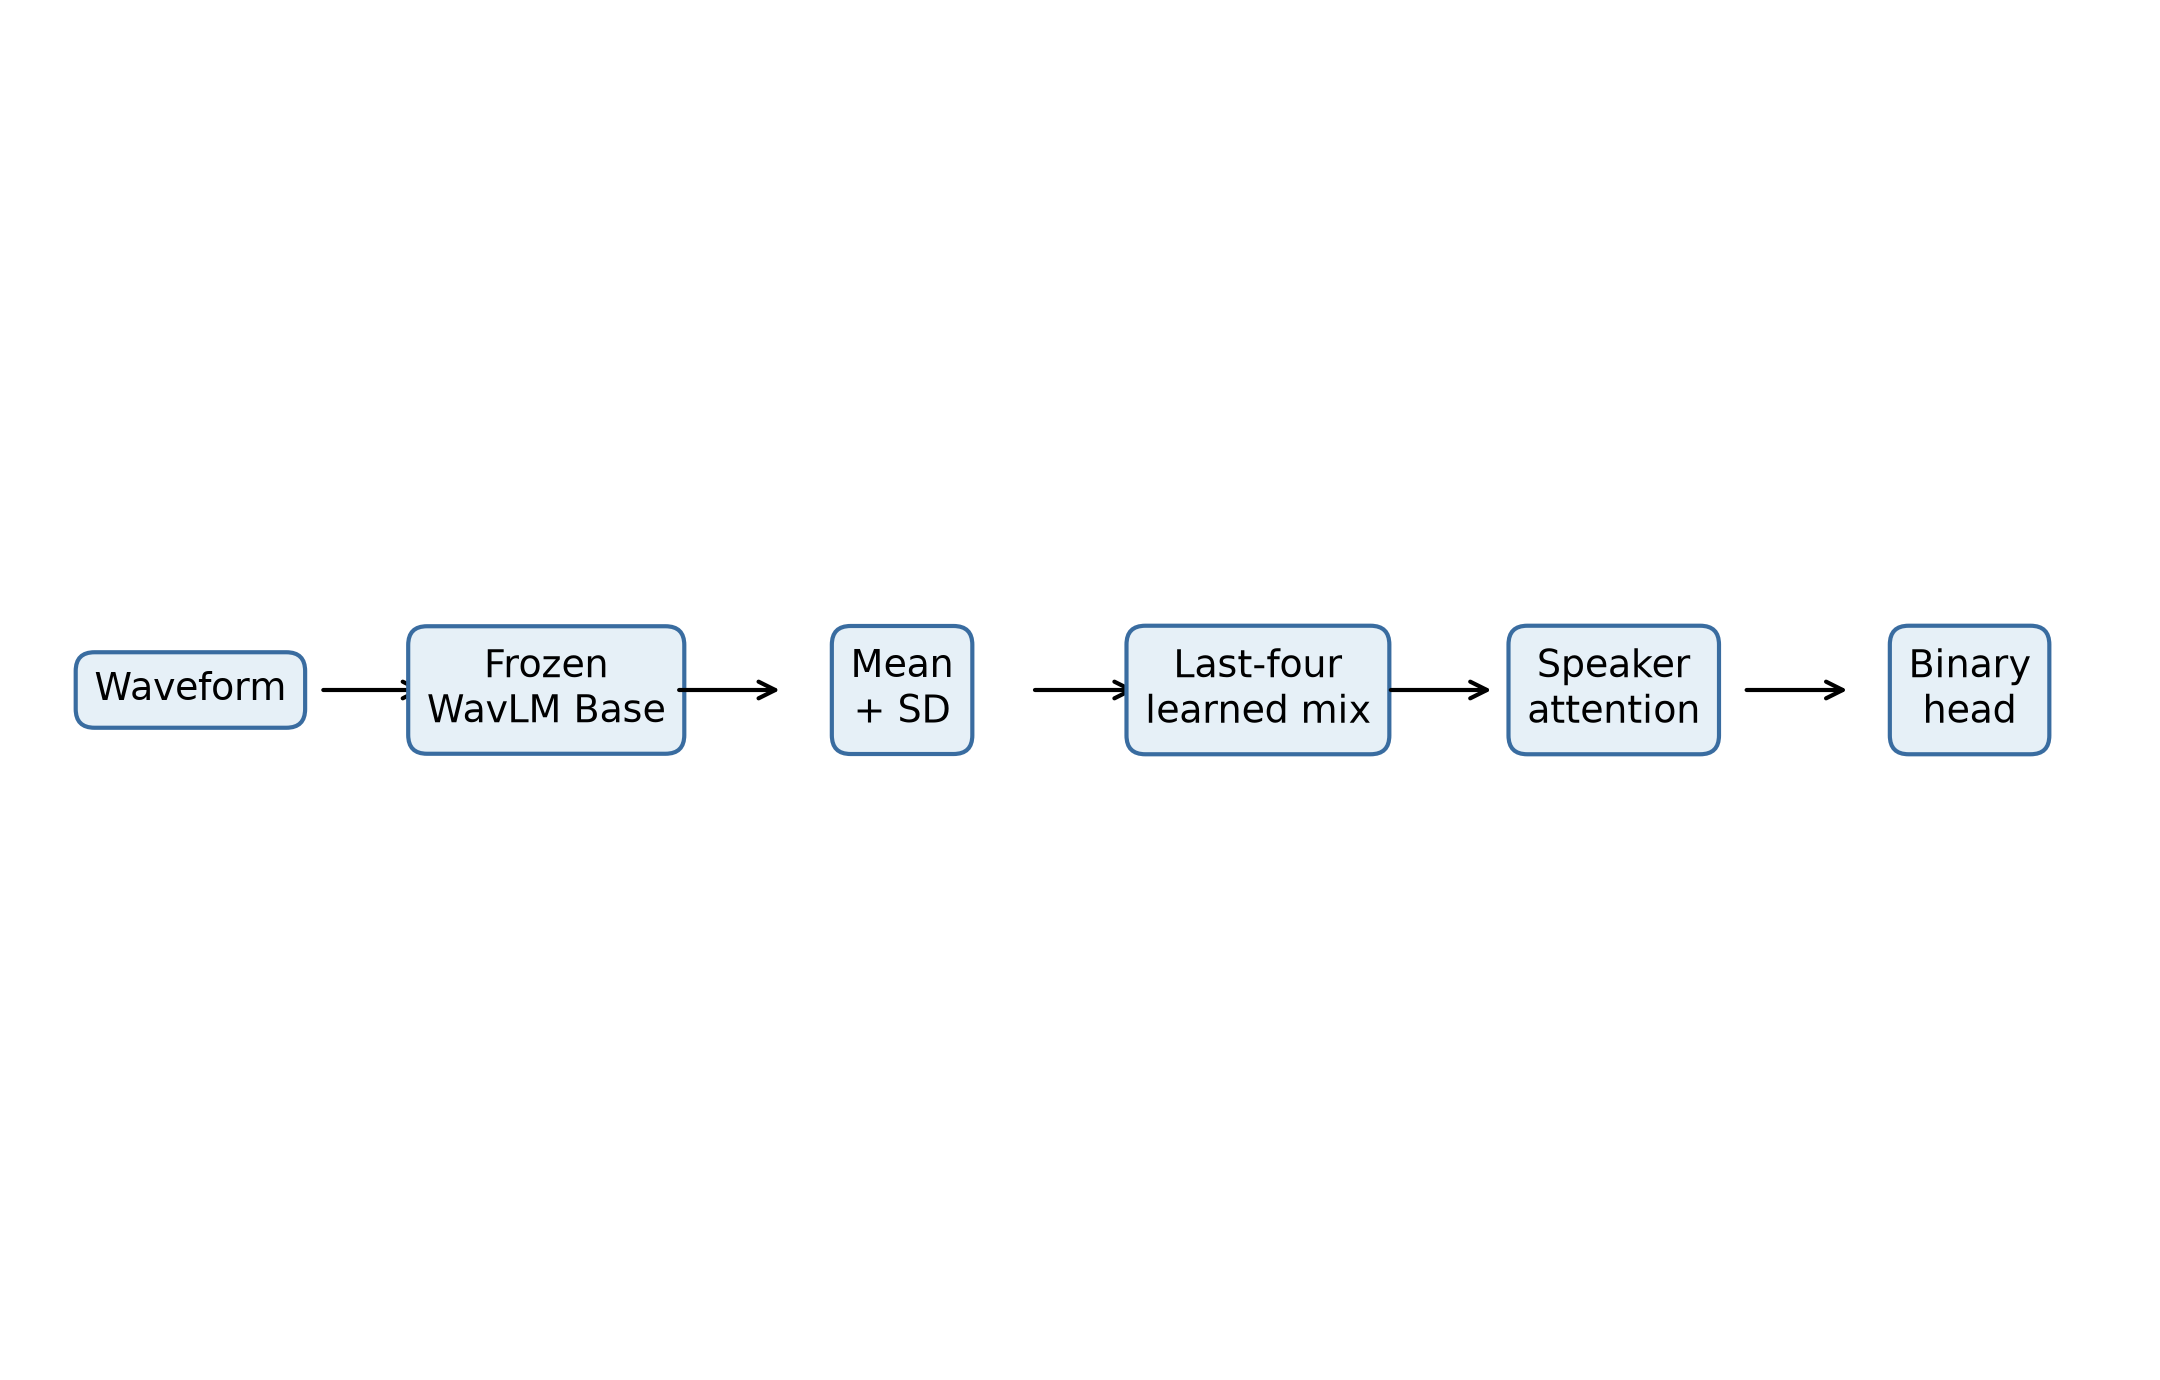

### Fig02 Torgo Roc Pr

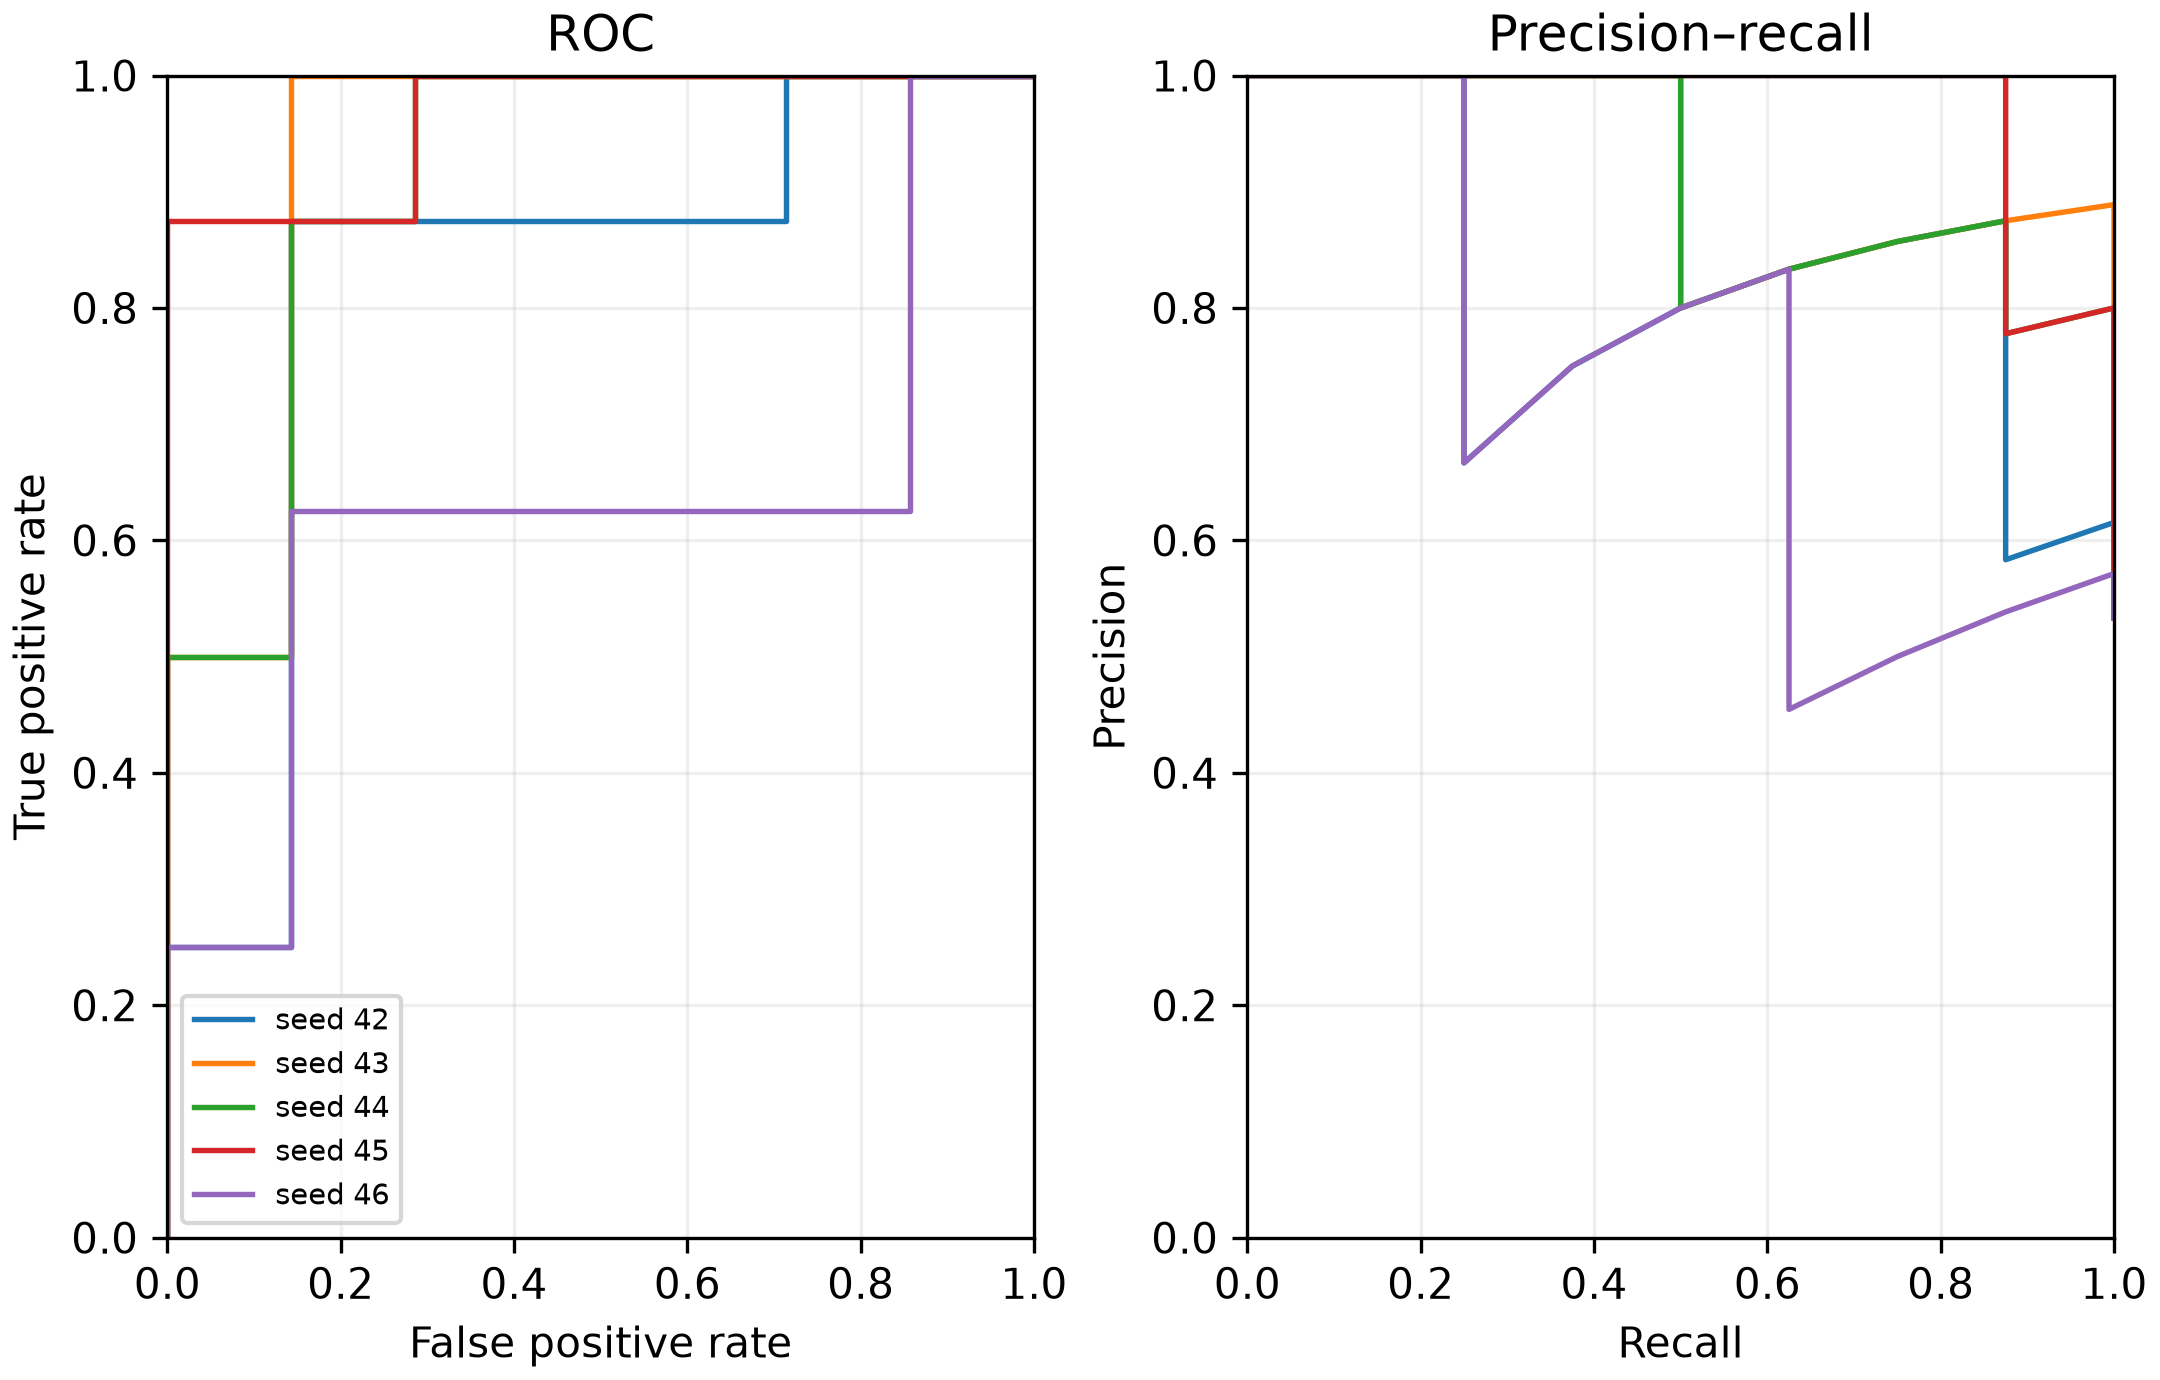

### Fig03 V8 V10

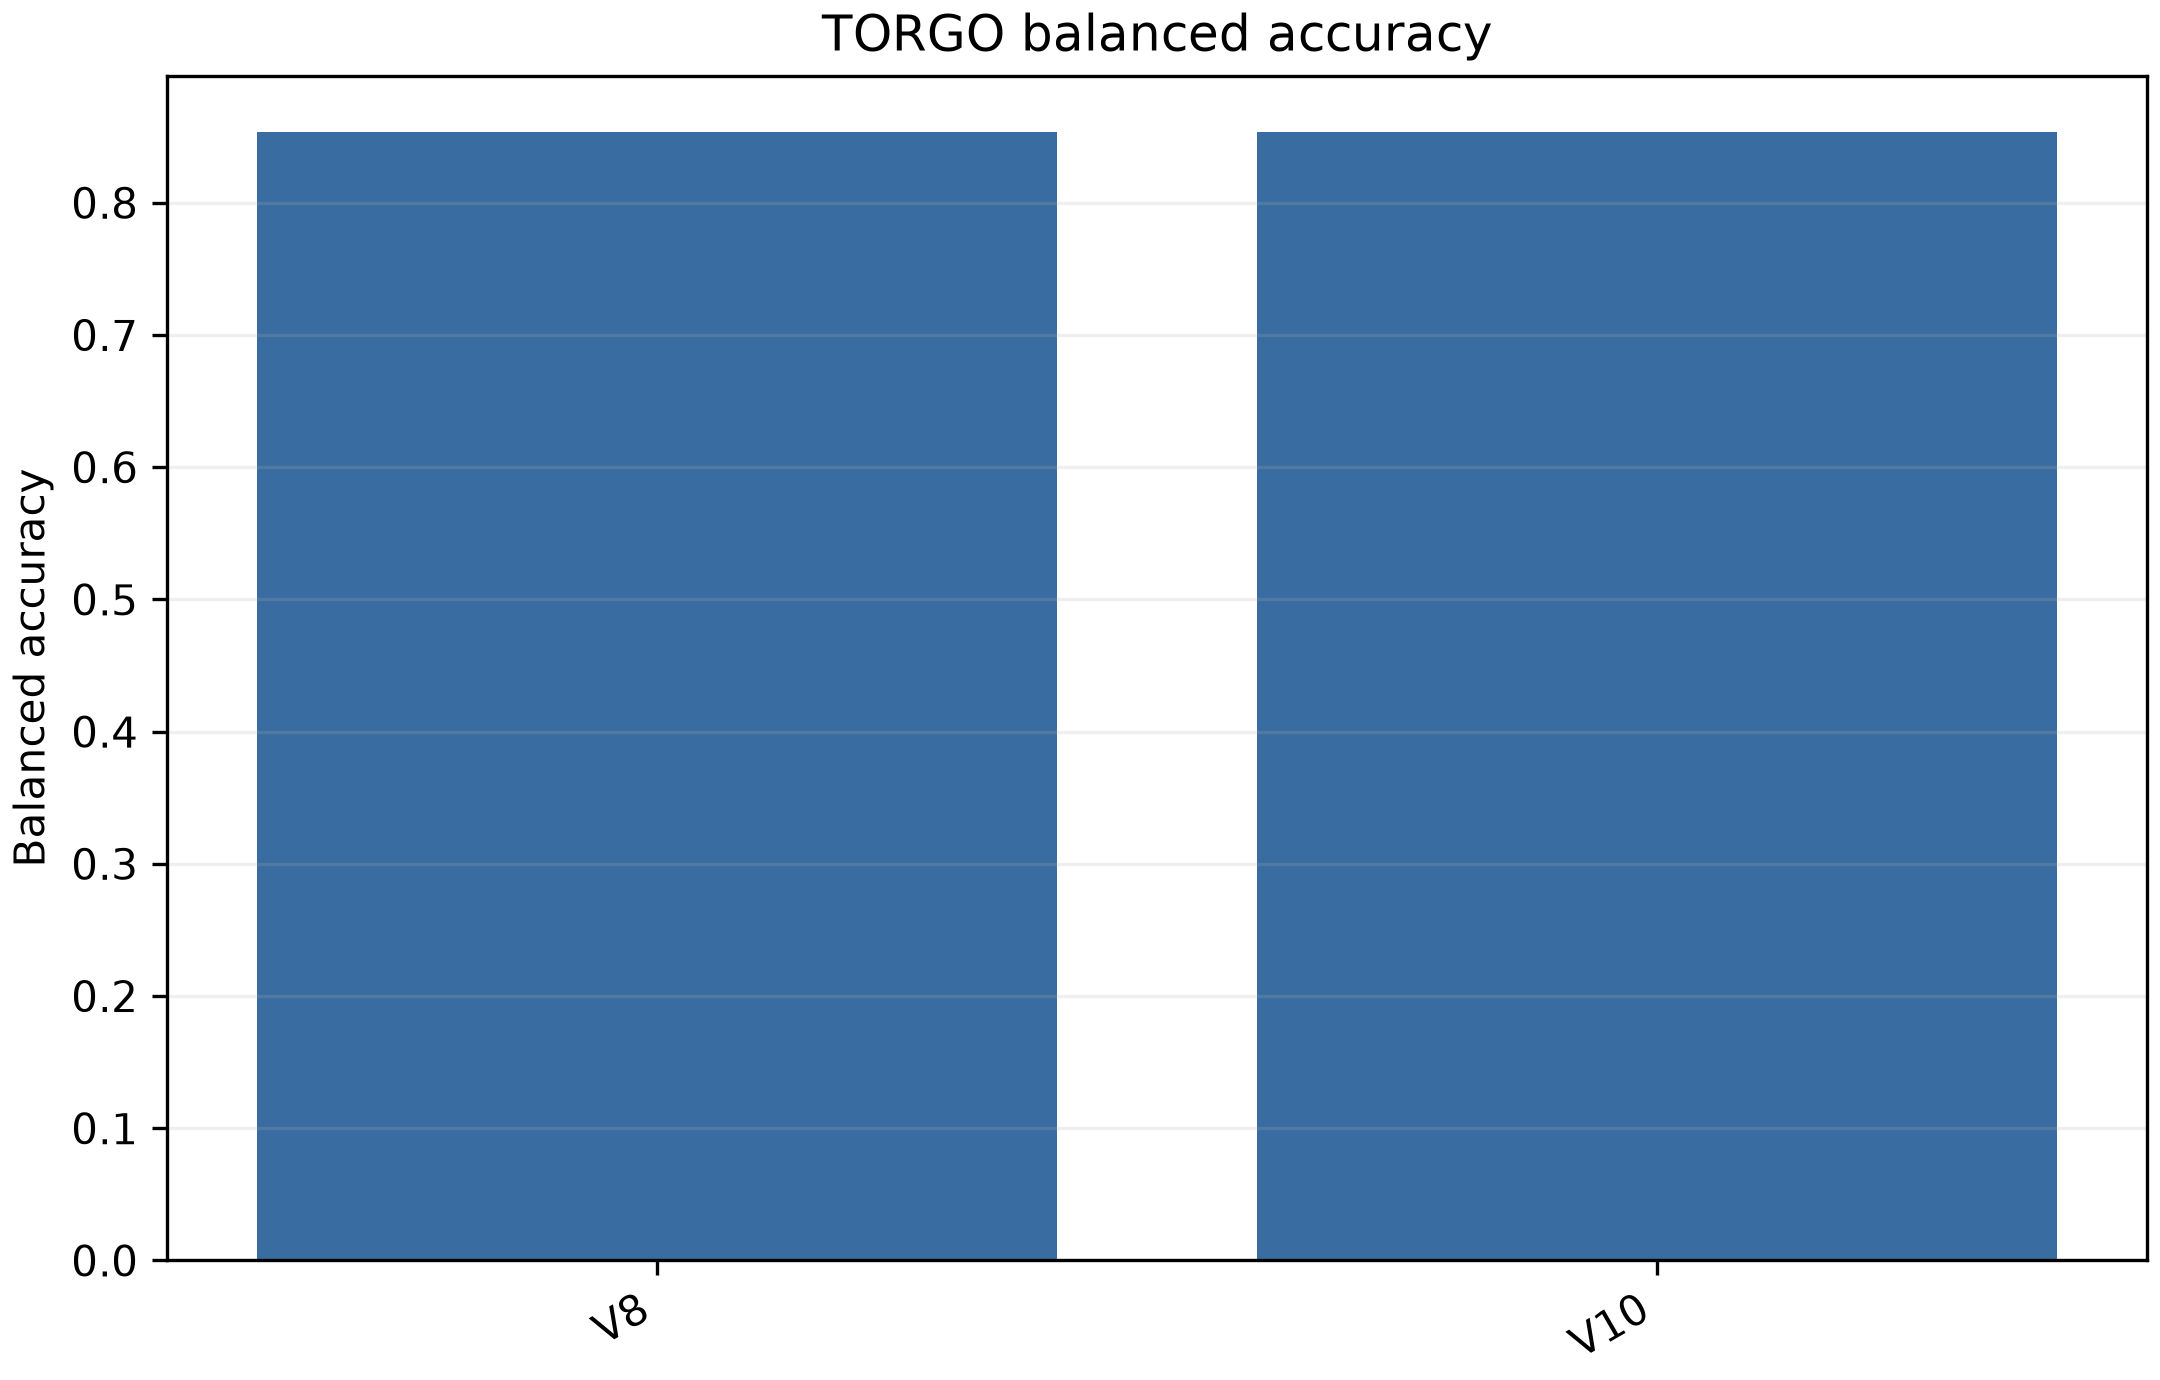

### Fig04 Simple Baselines

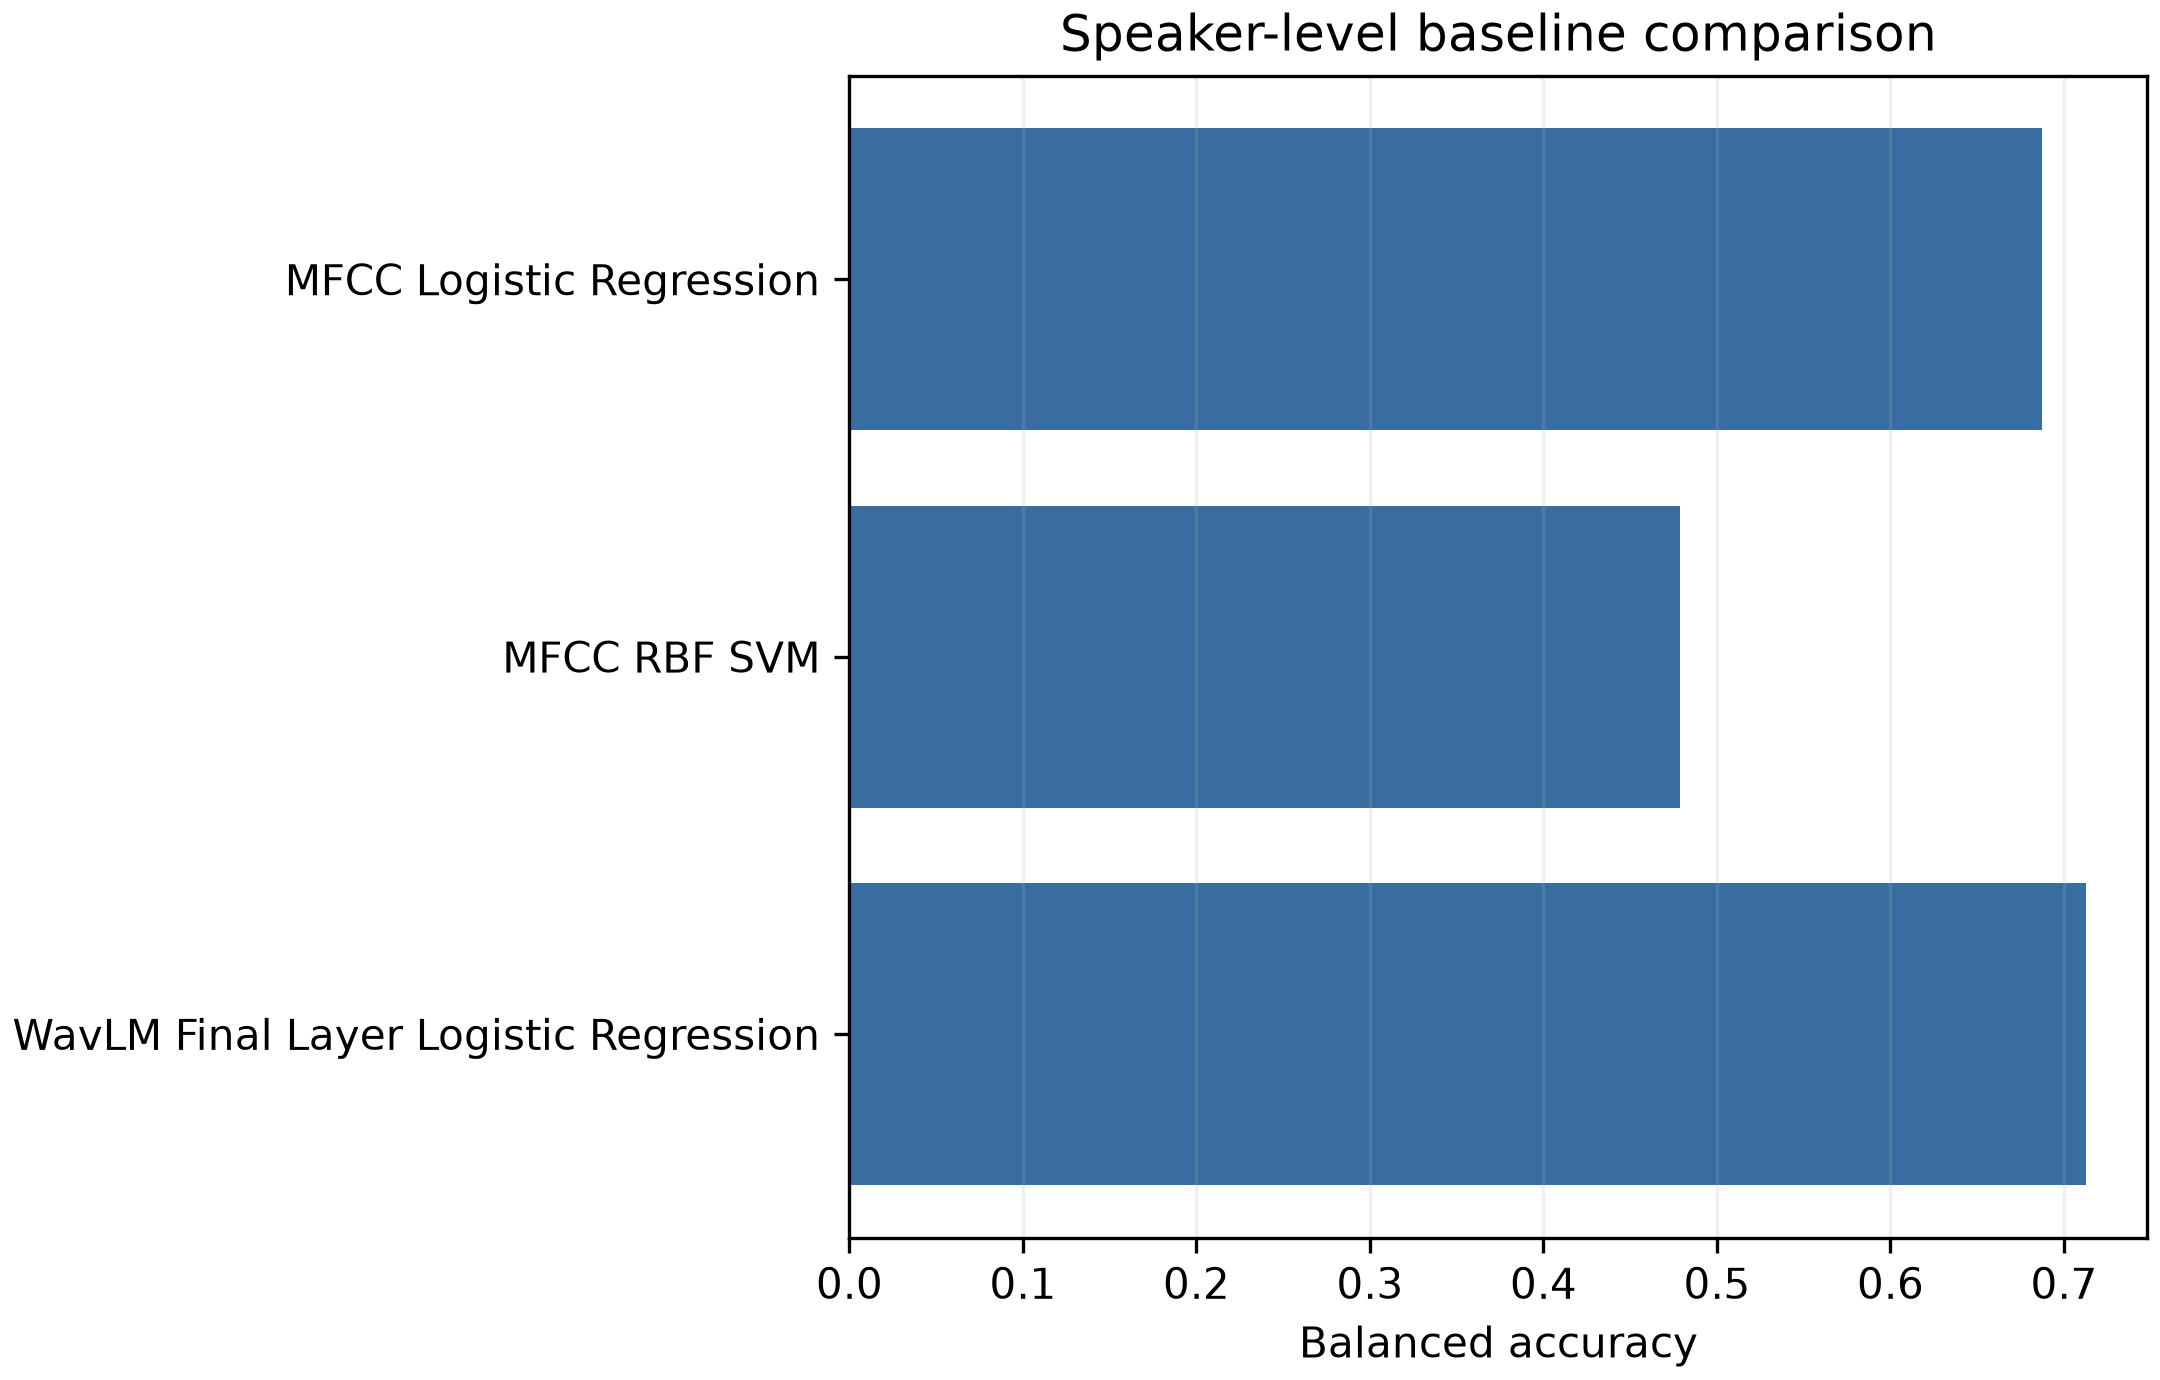

### Fig05 Wavlm Layer Probing

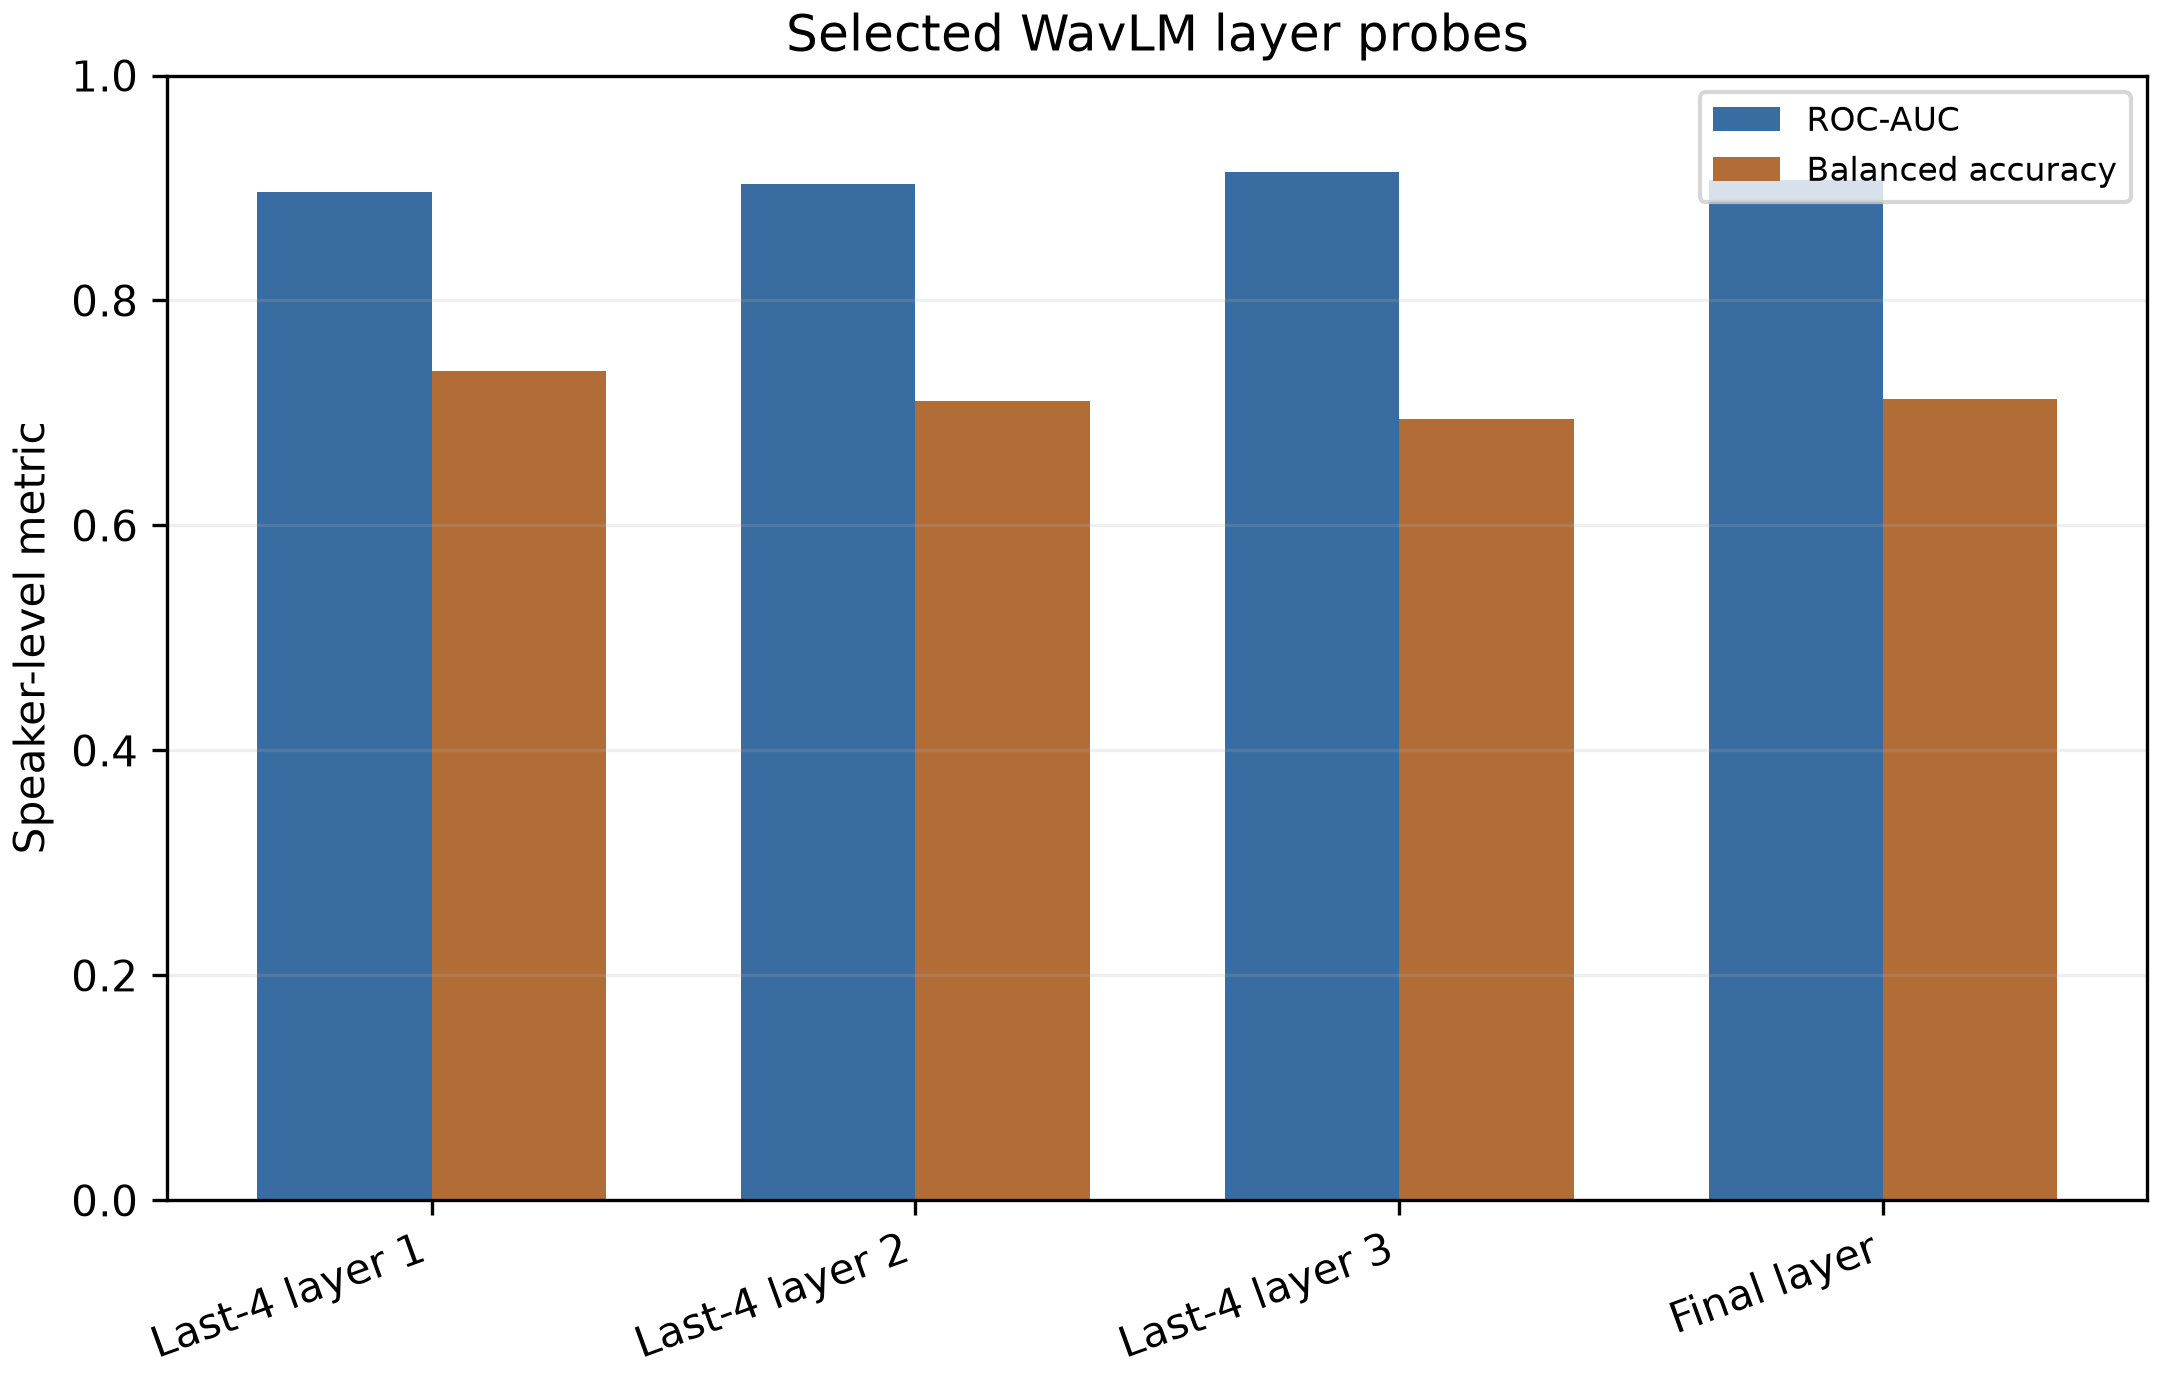

### Fig06 Layer Mixture Weights

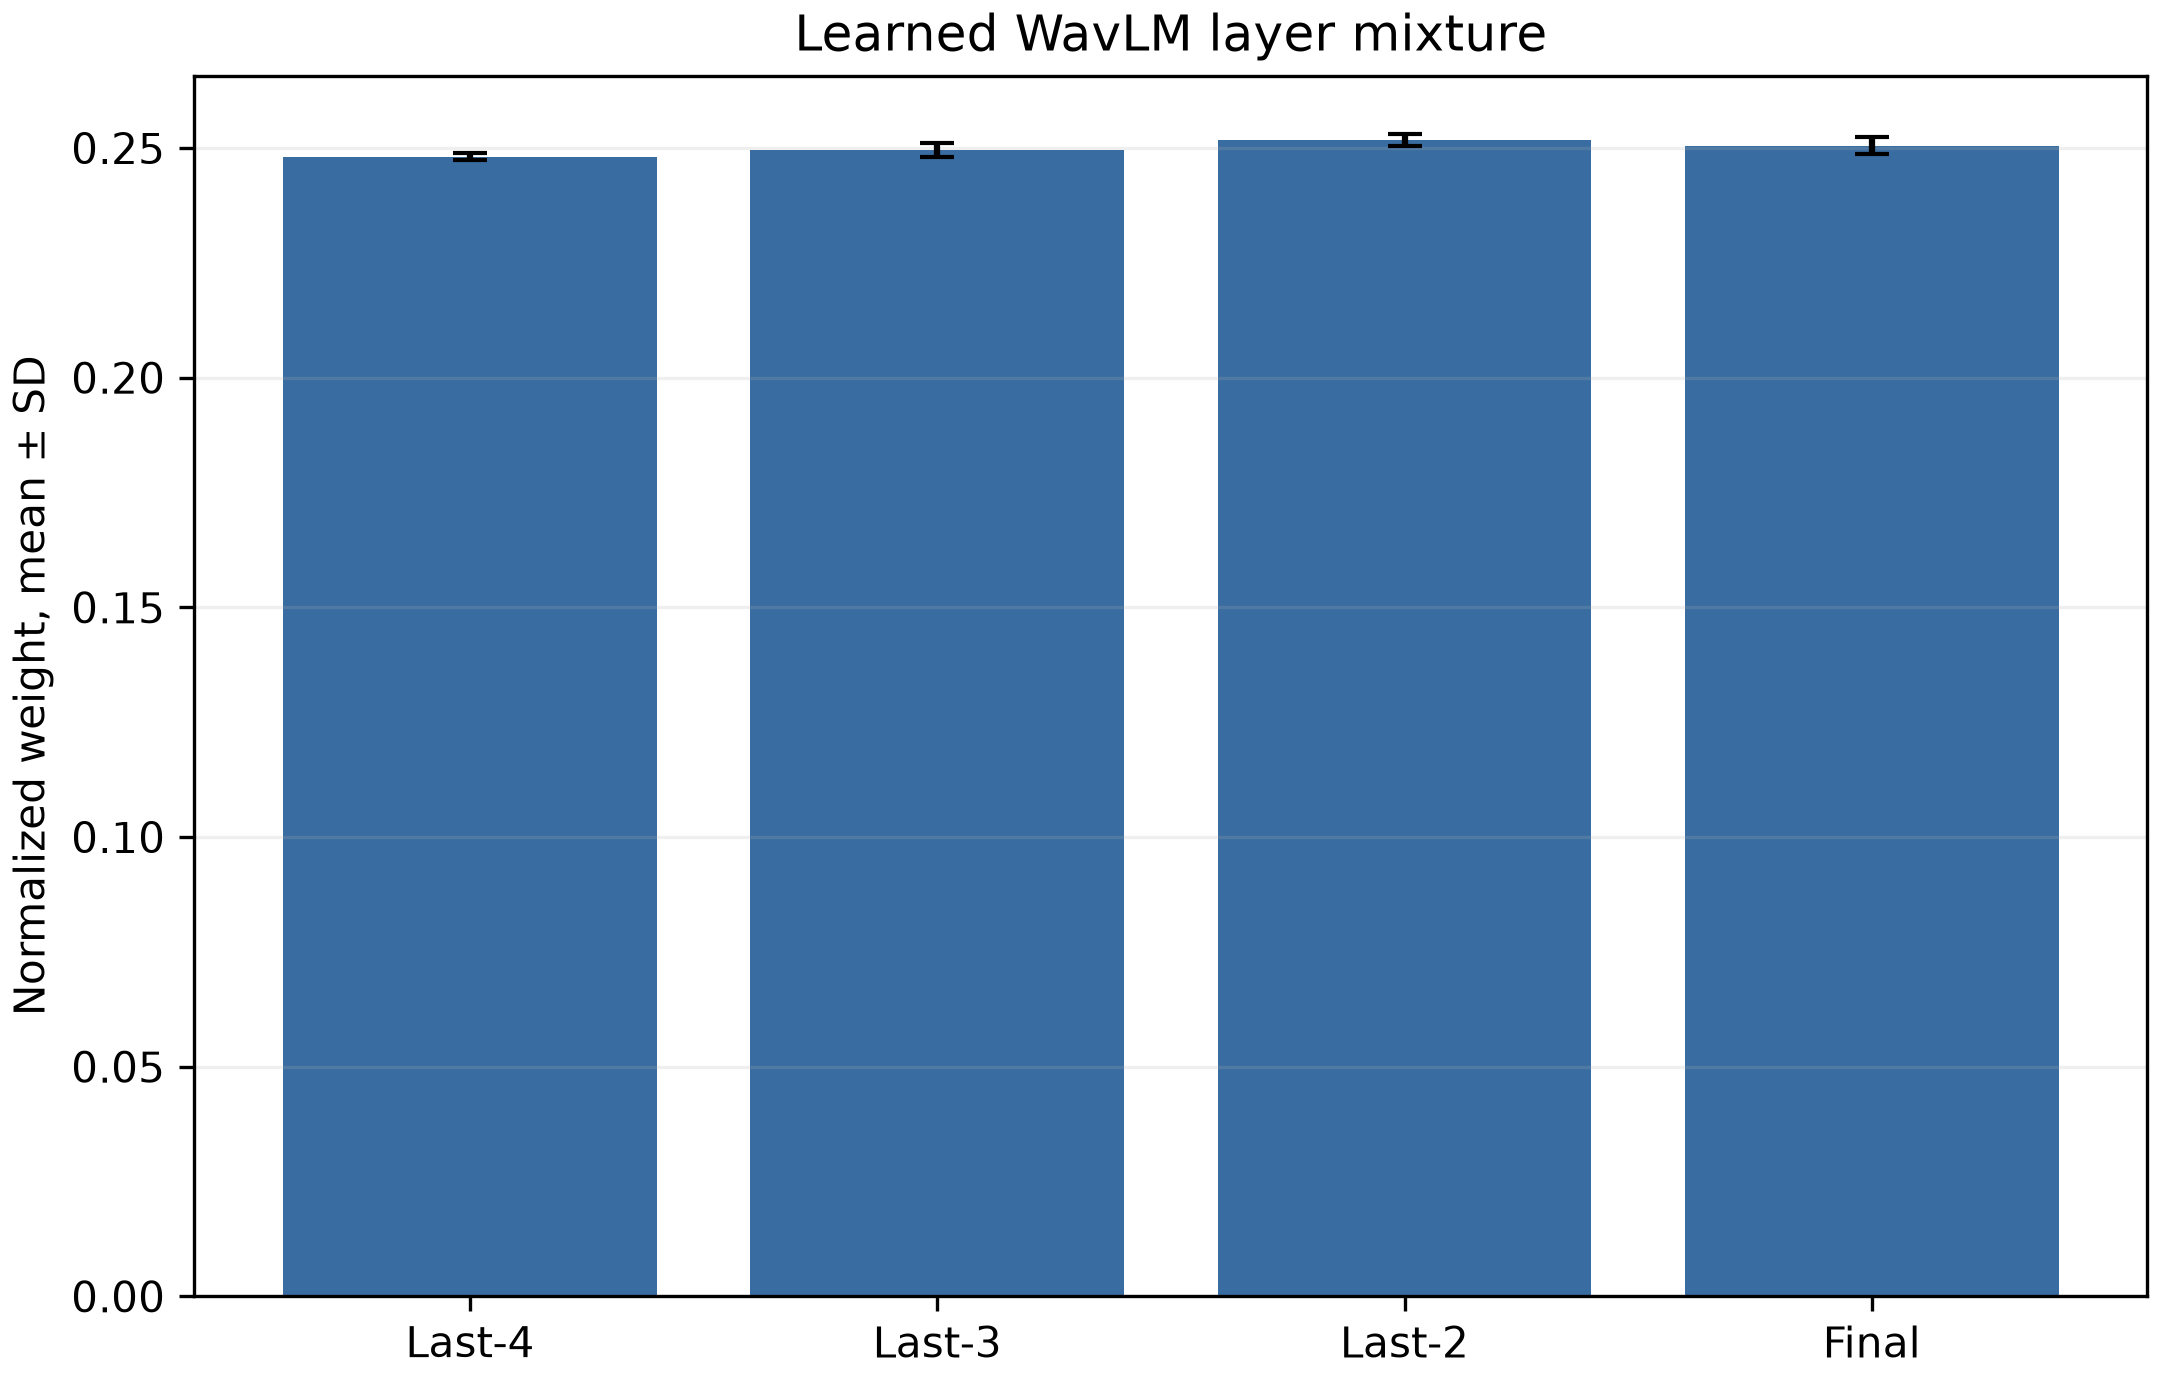

### Fig07 Uaspeech M3 Roc Pr

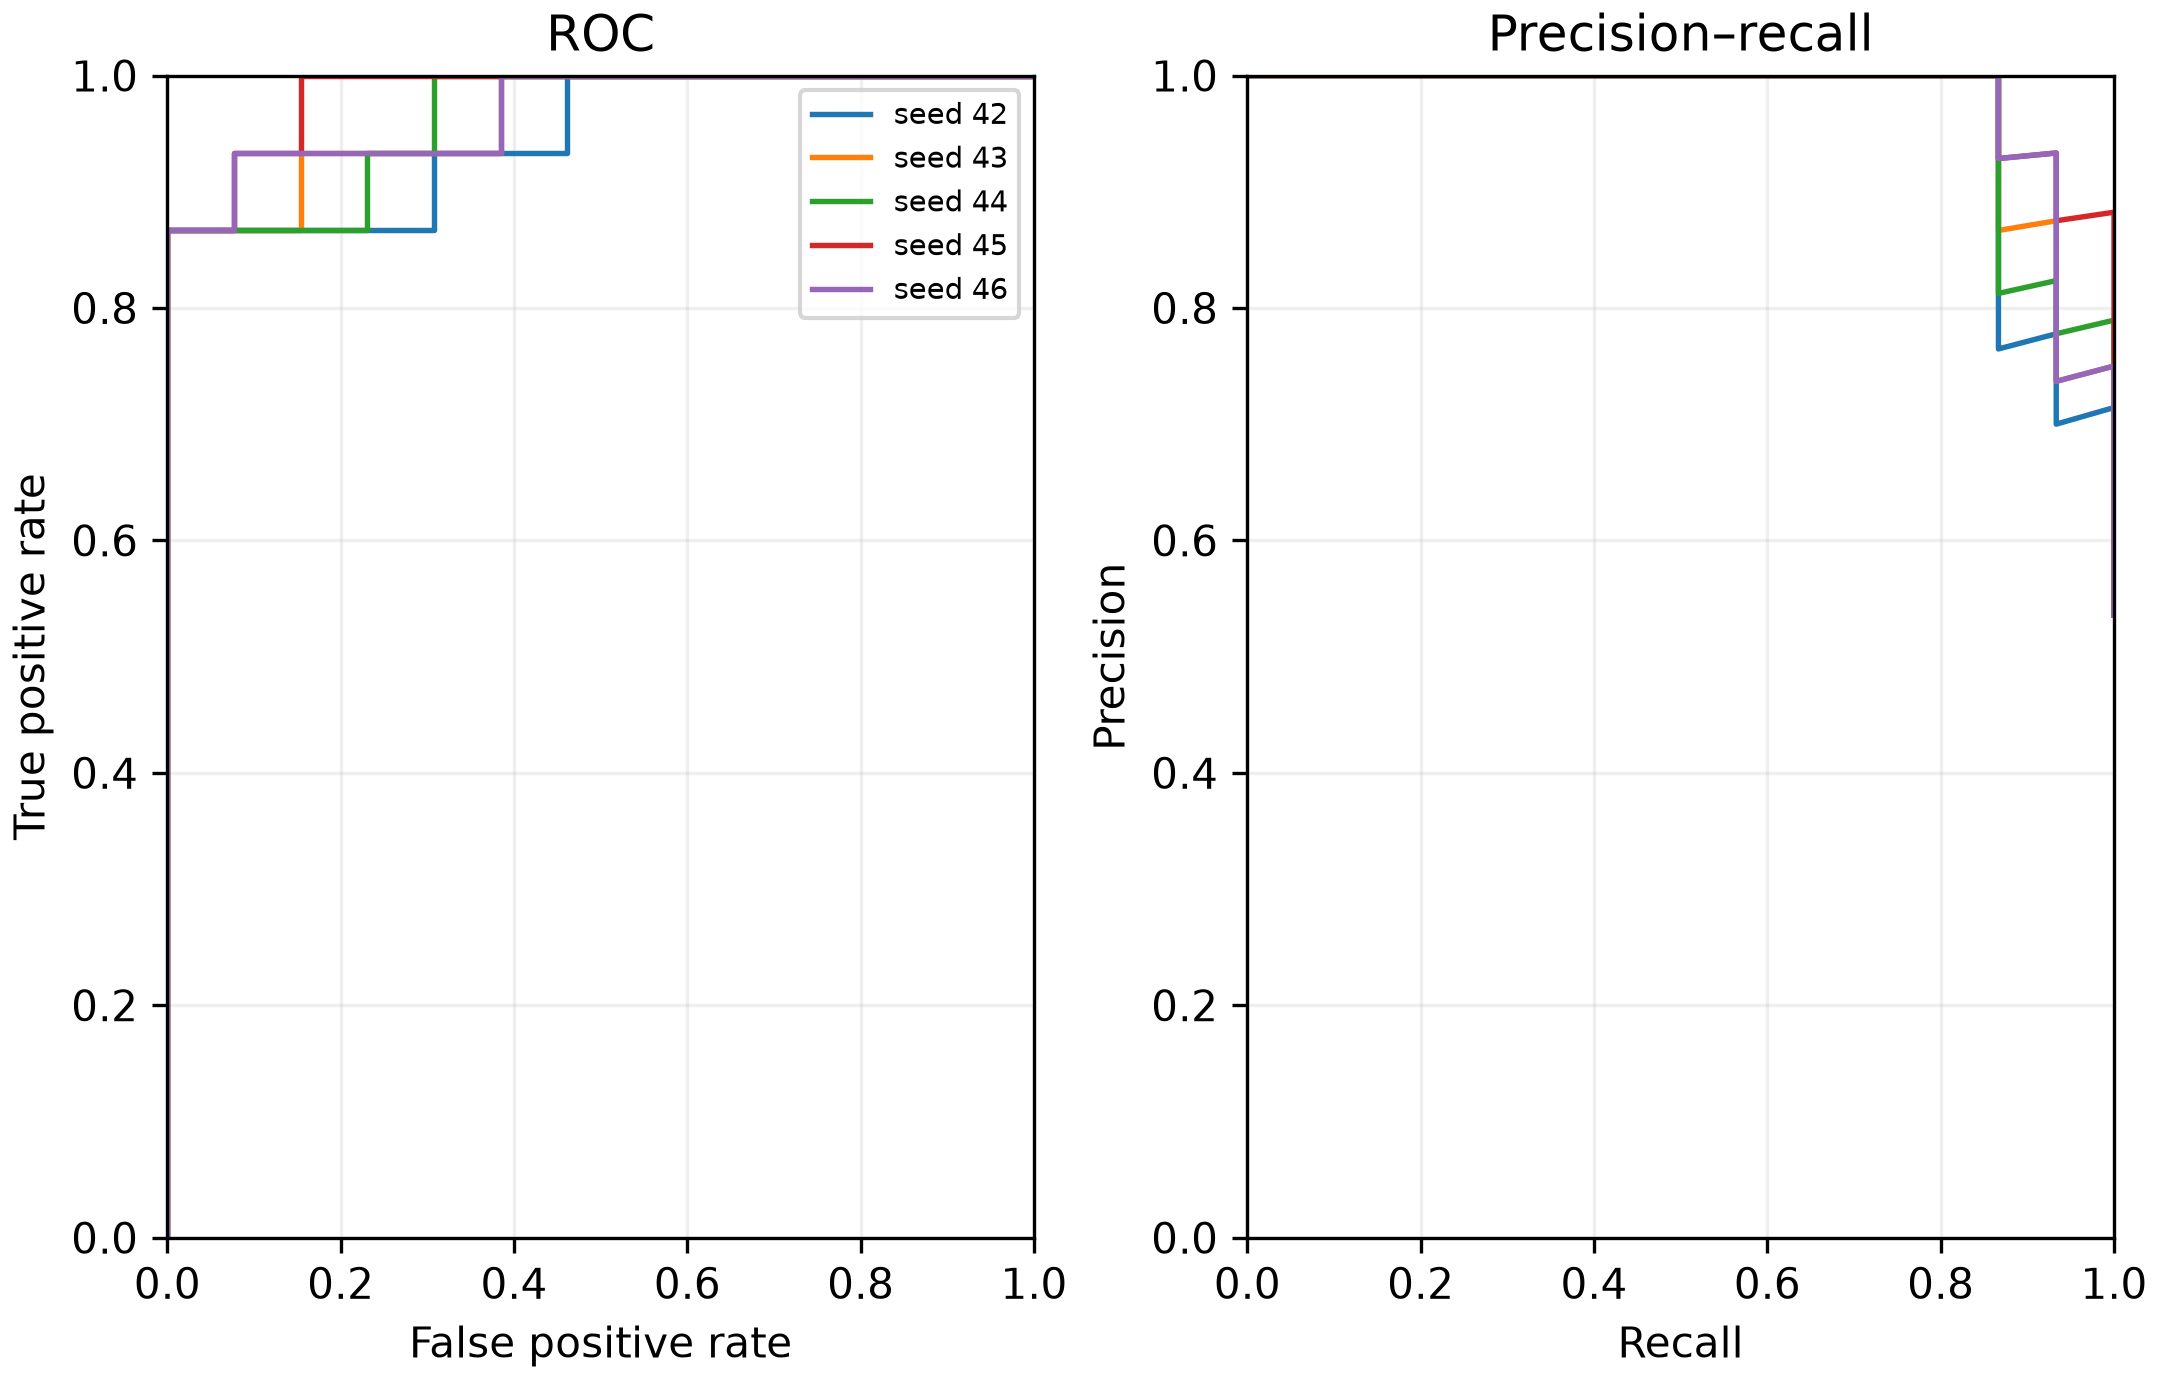

### Fig08 Intelligibility Probability

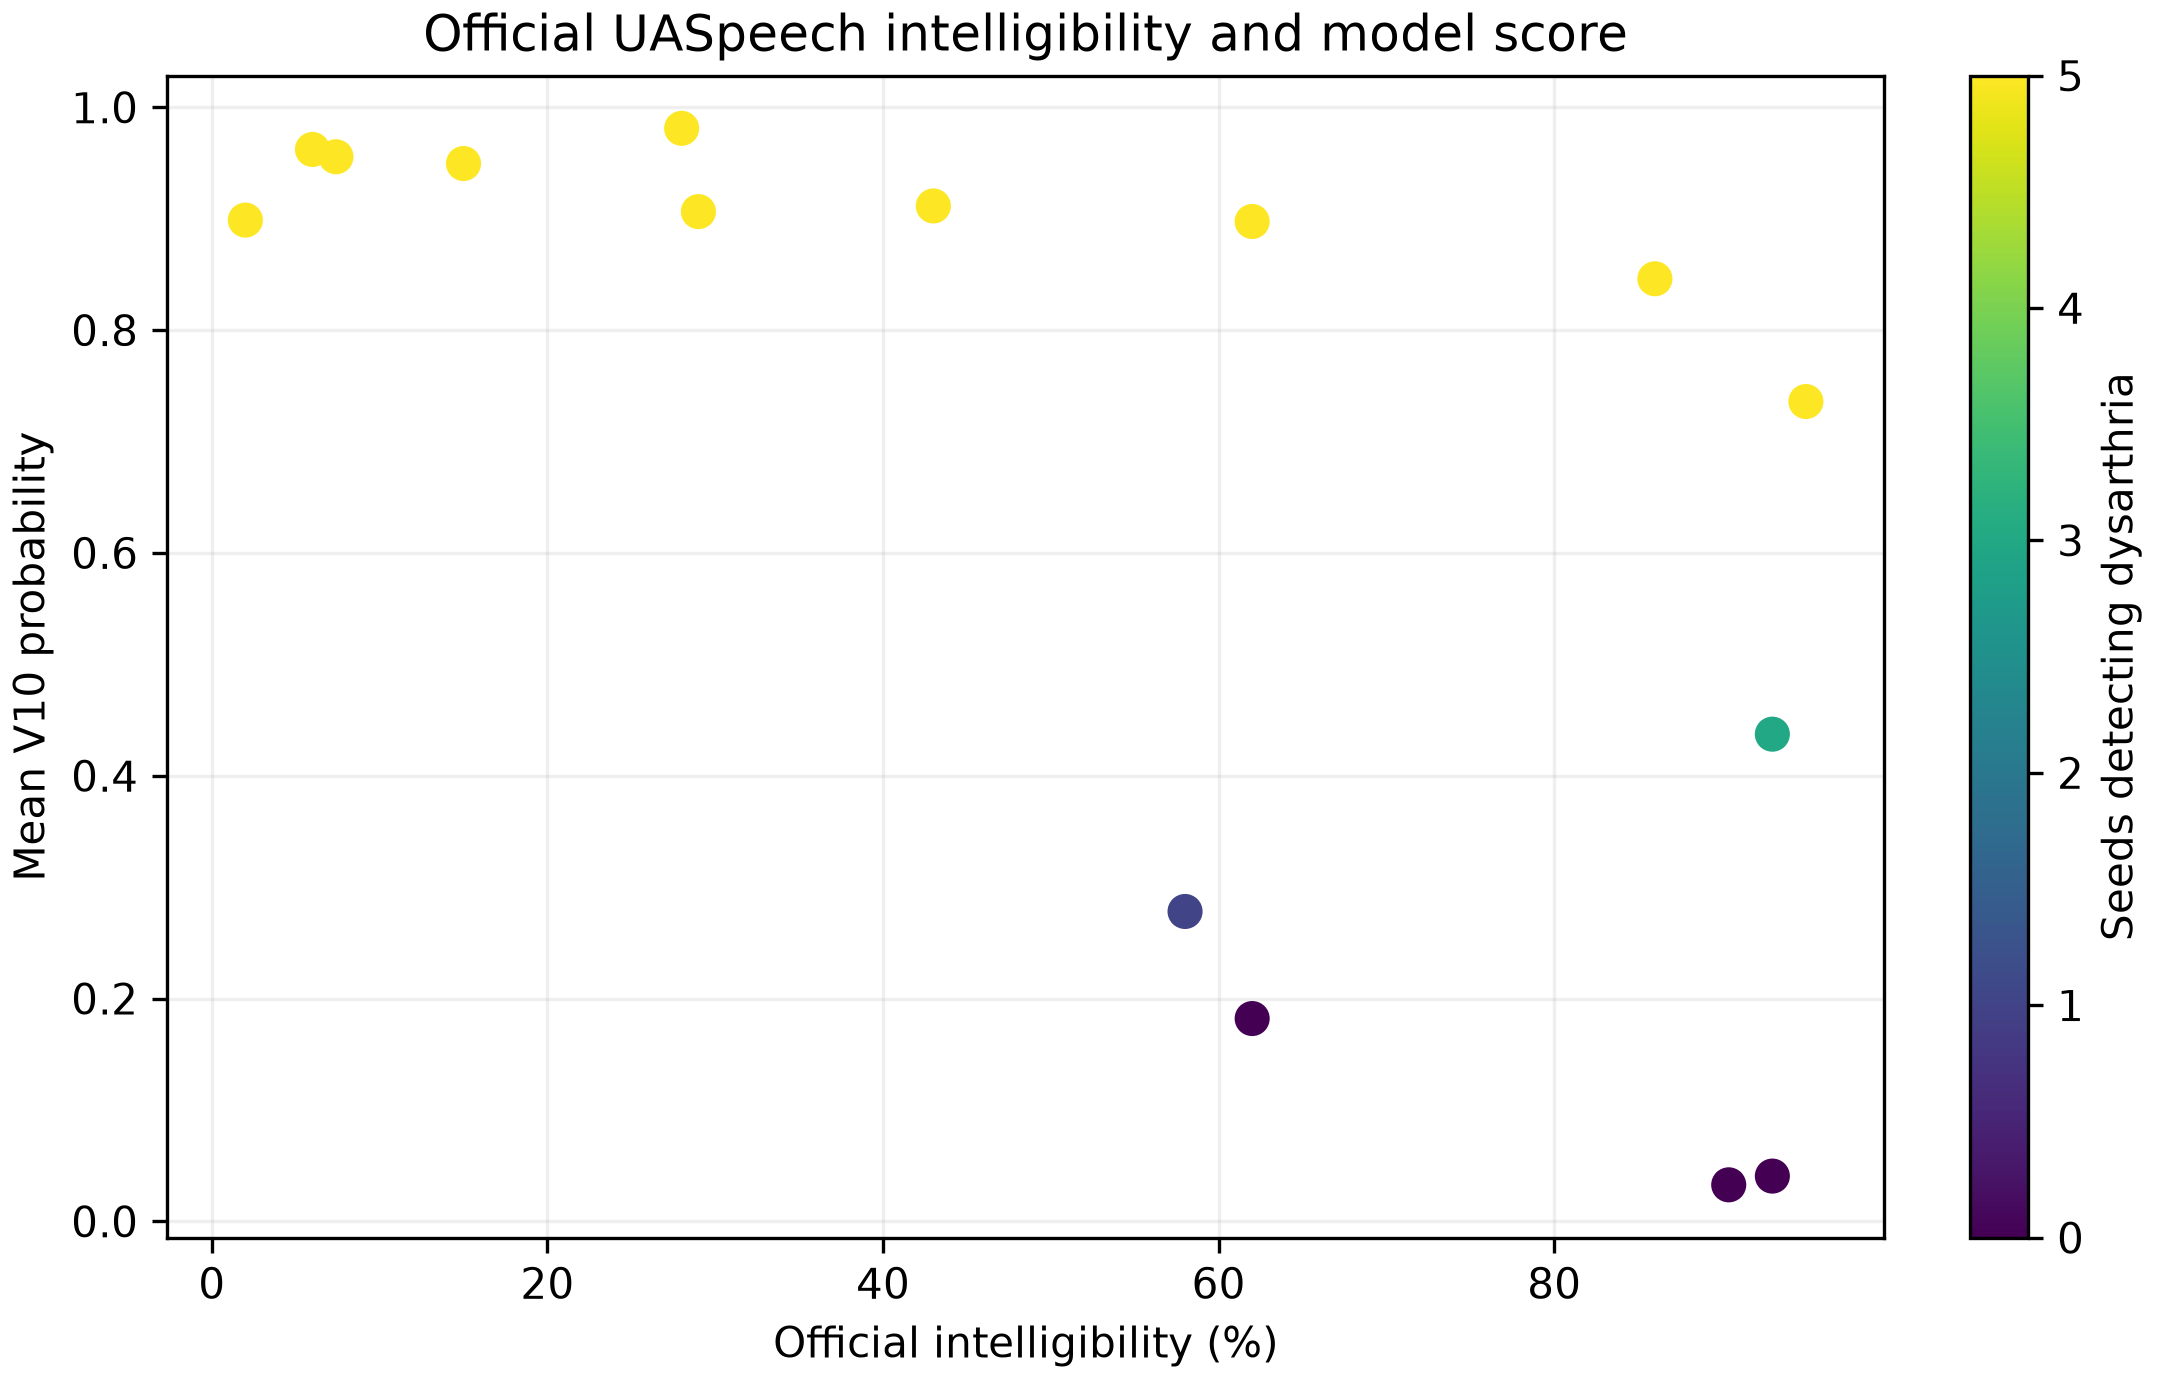

### Fig09 Intelligibility Sensitivity

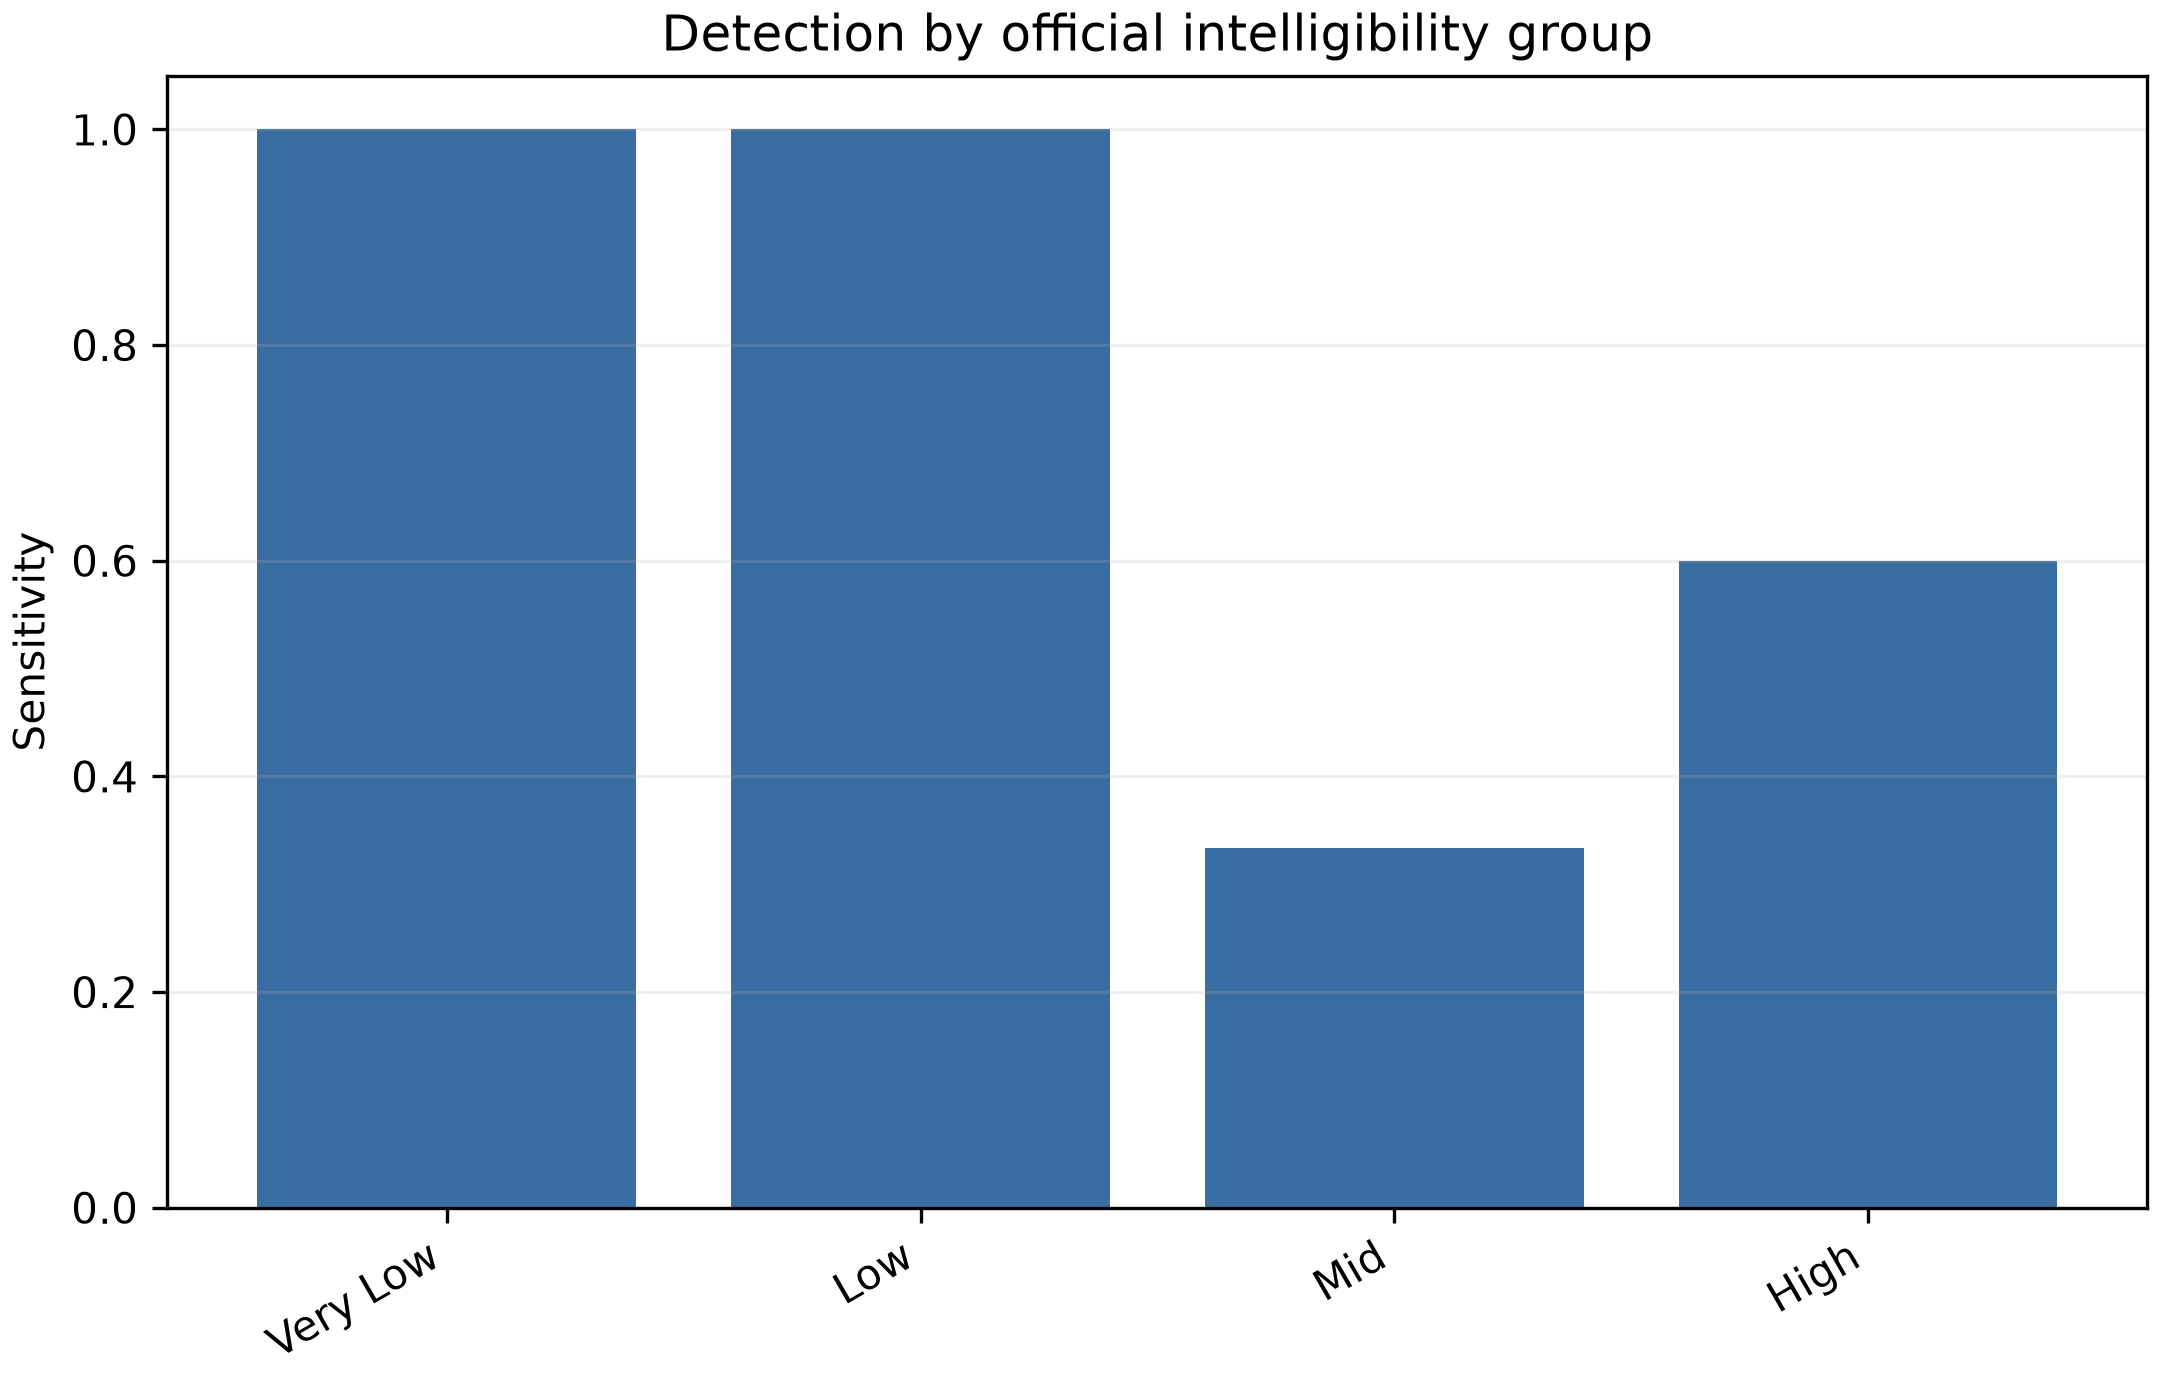

### Fig10 Utterance Budget

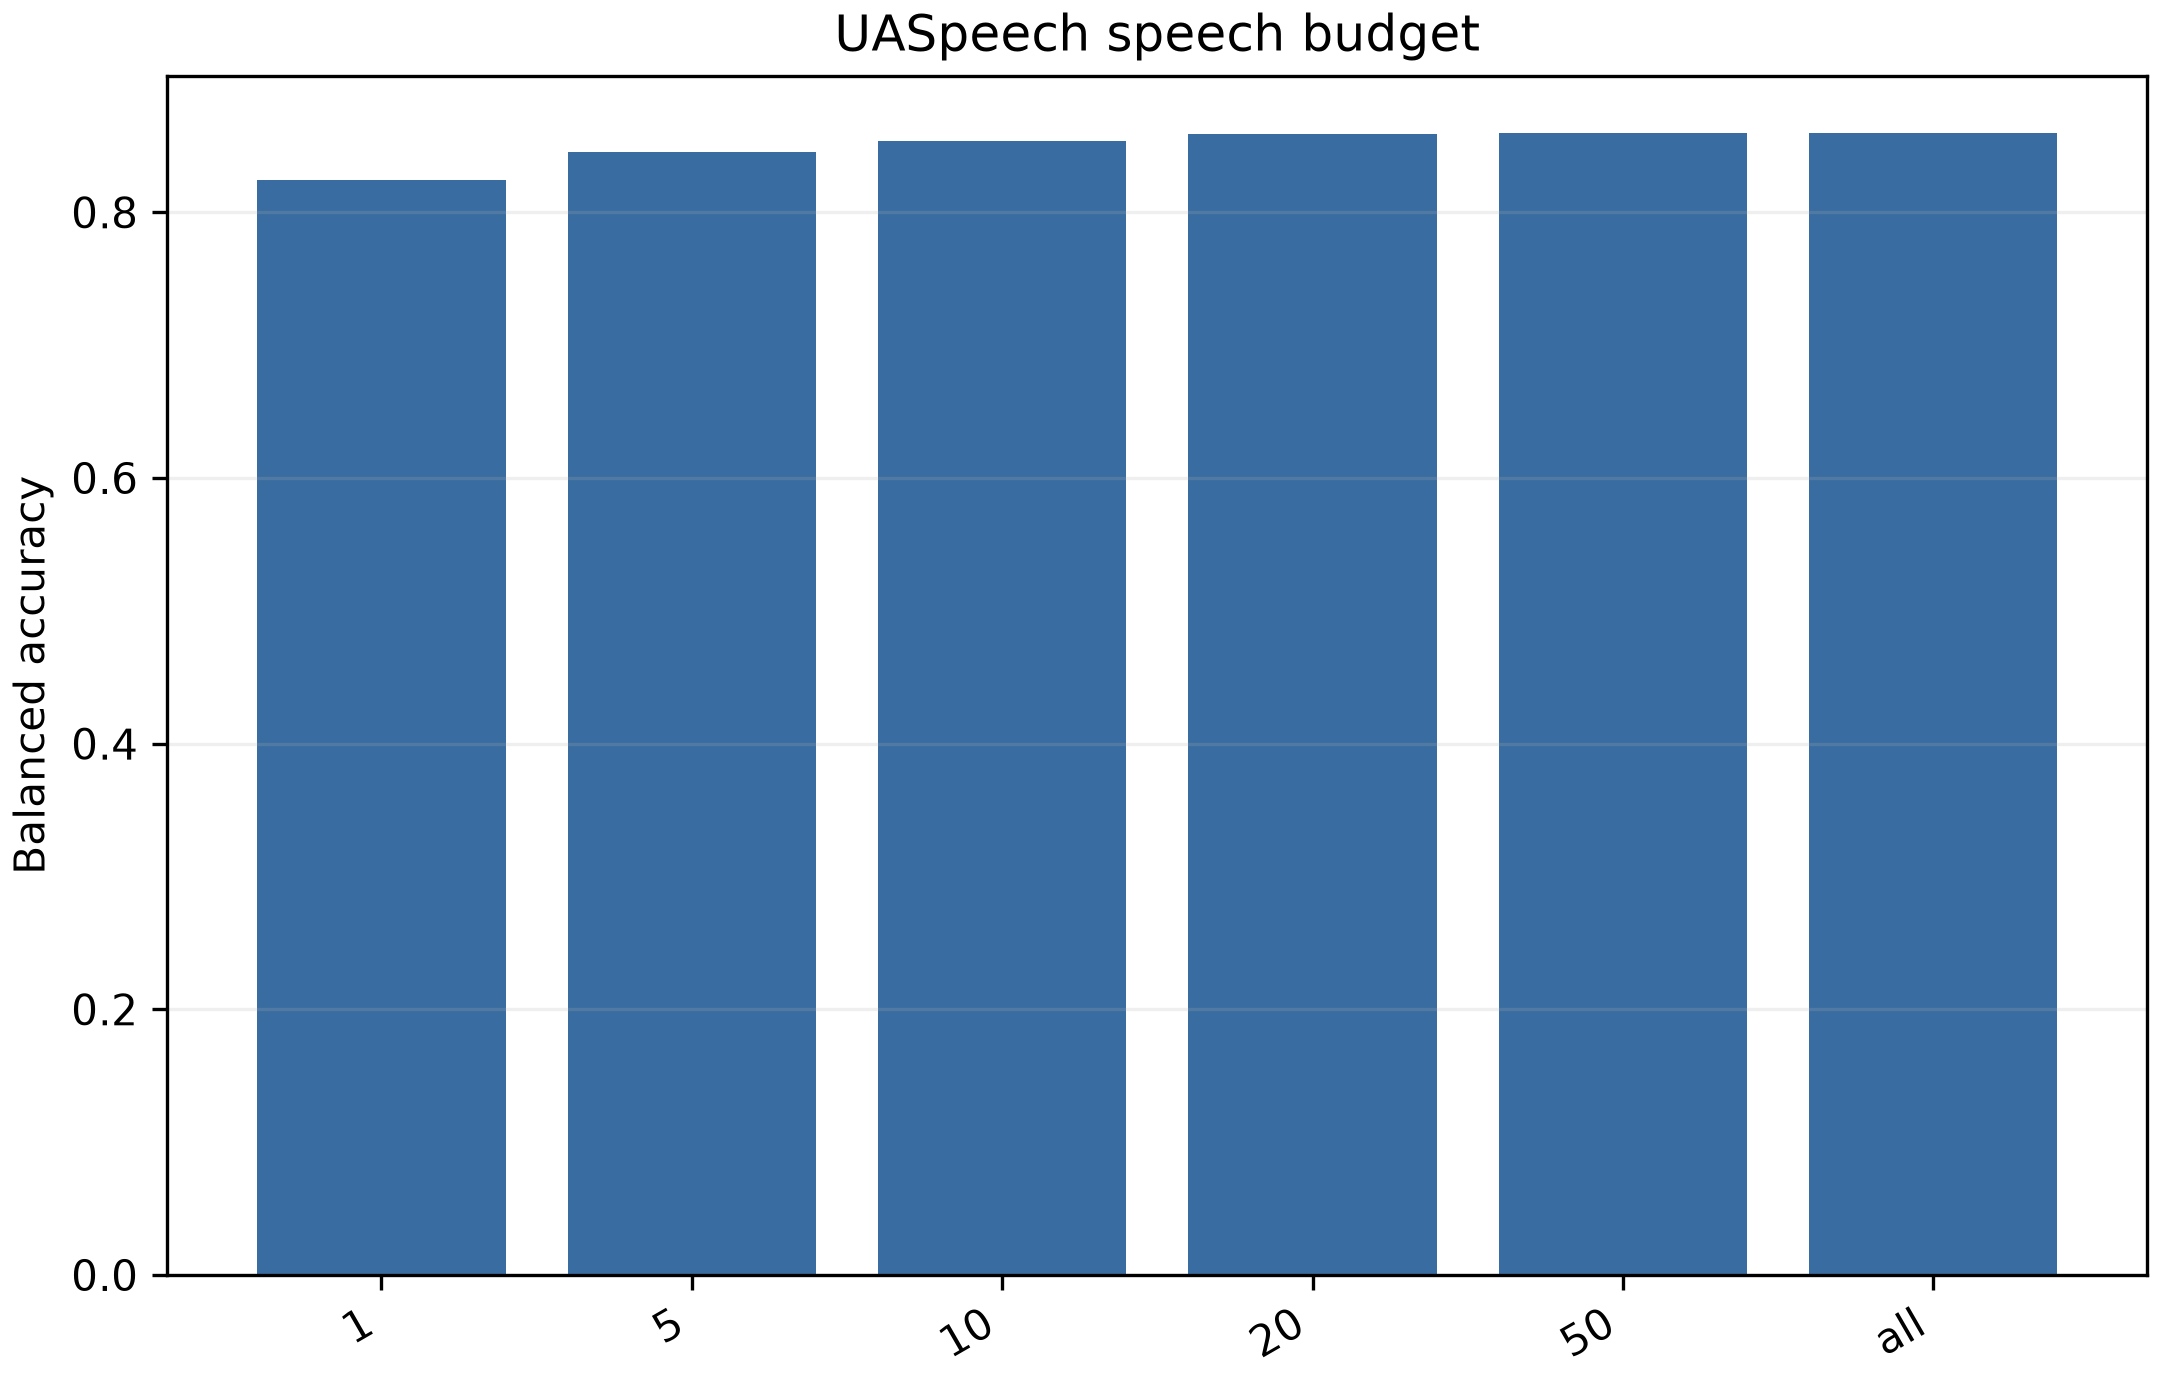

### Fig11 Channel Robustness

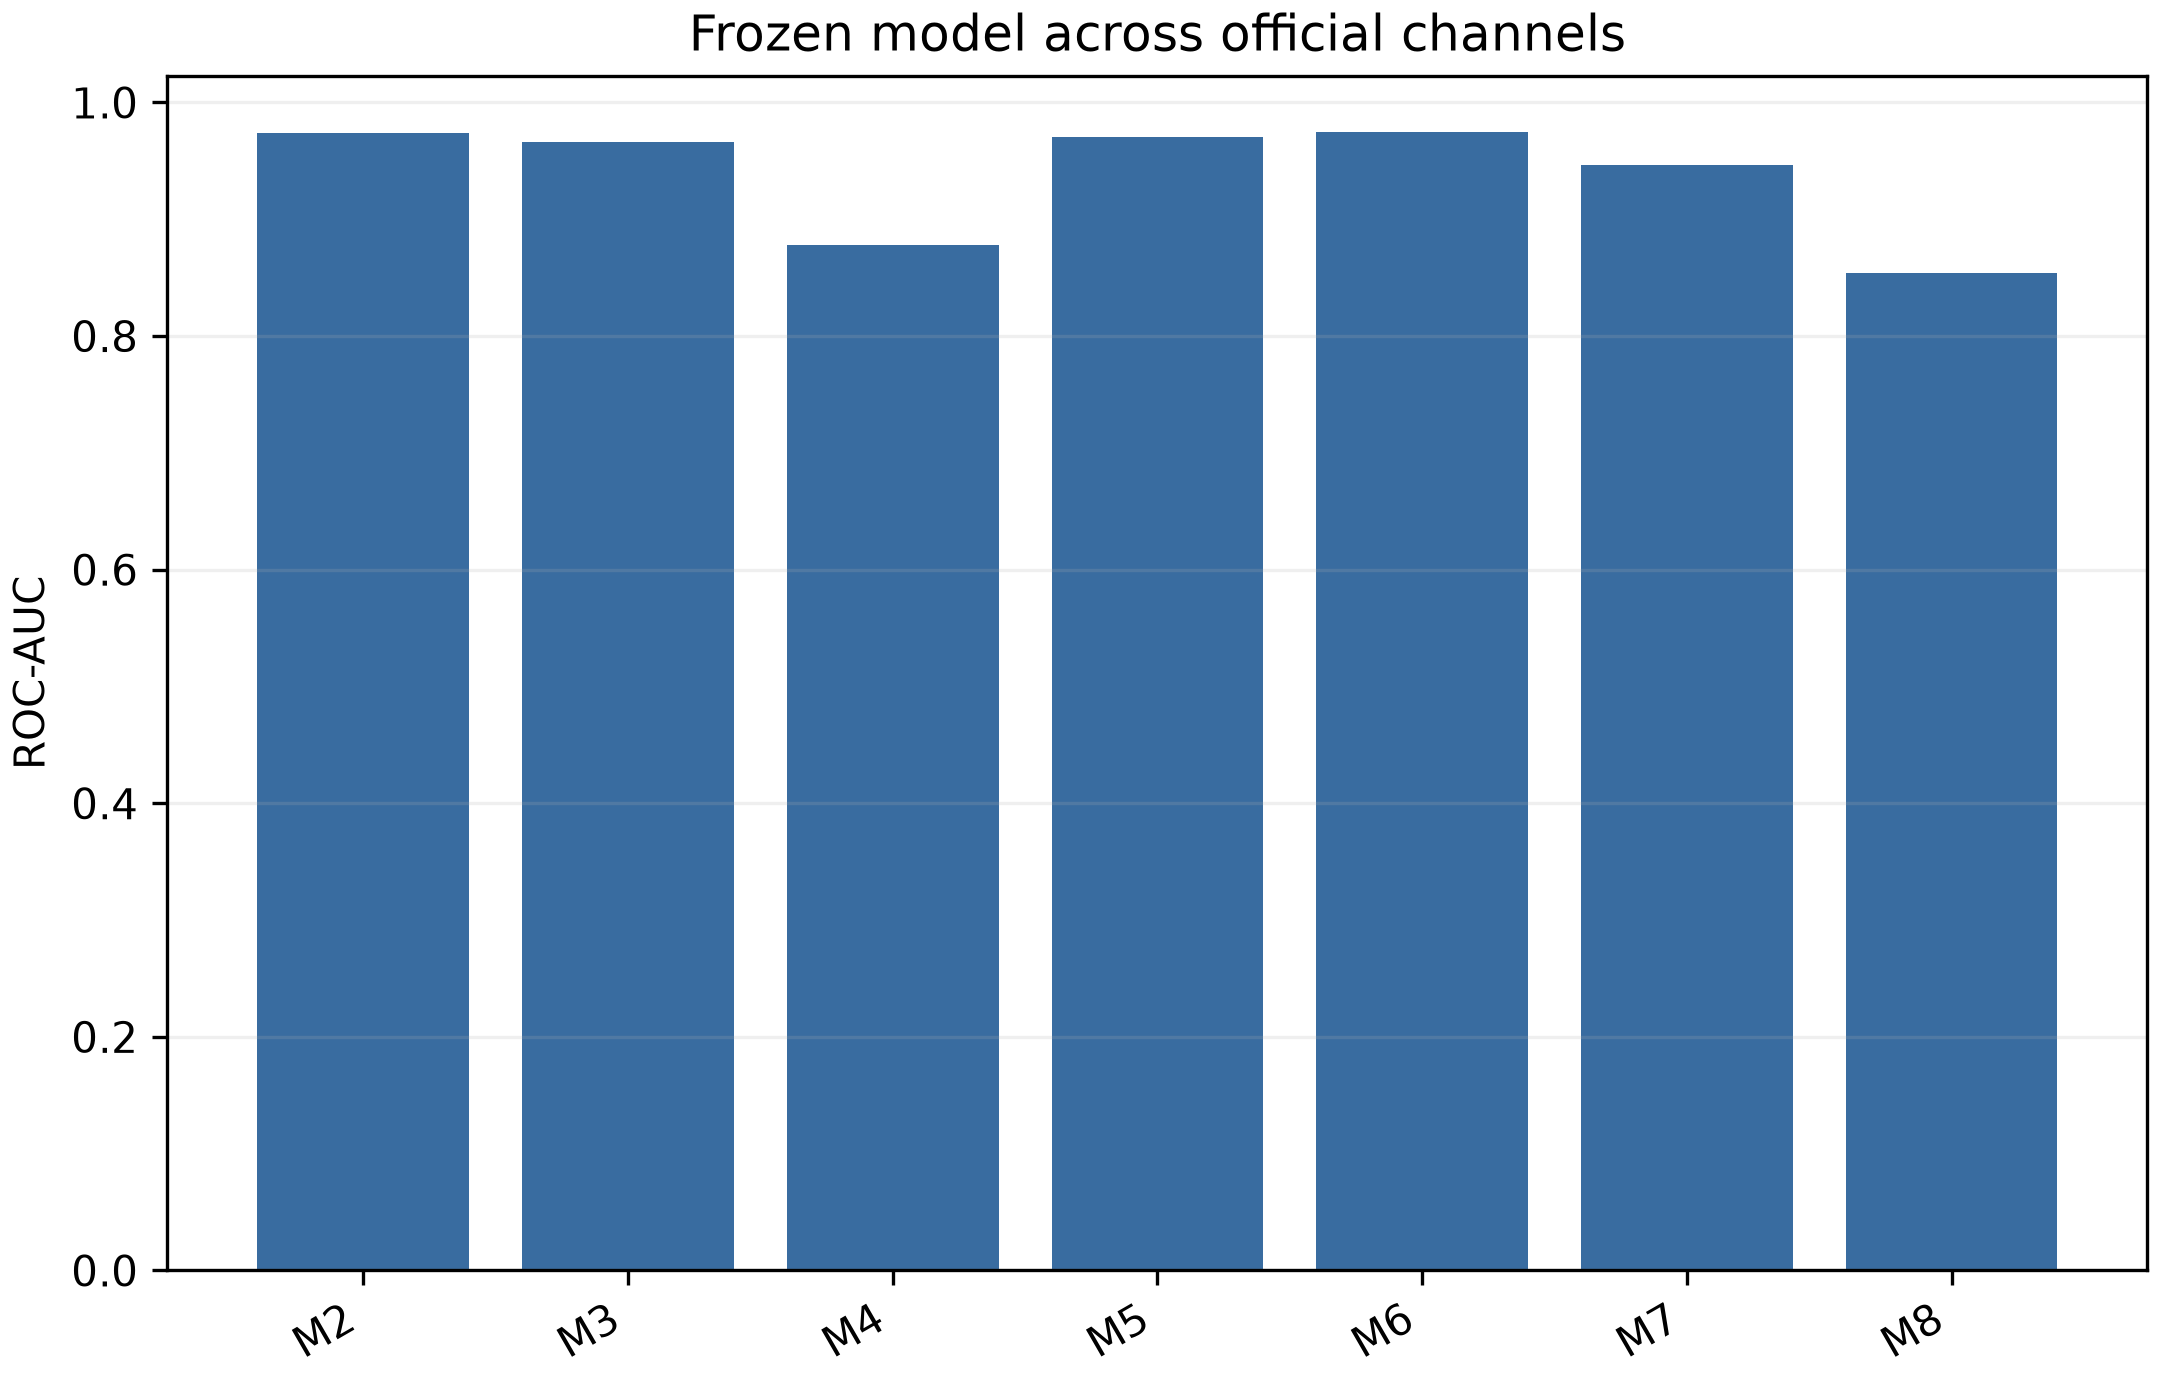

### Fig12 Speaker Error Heatmap

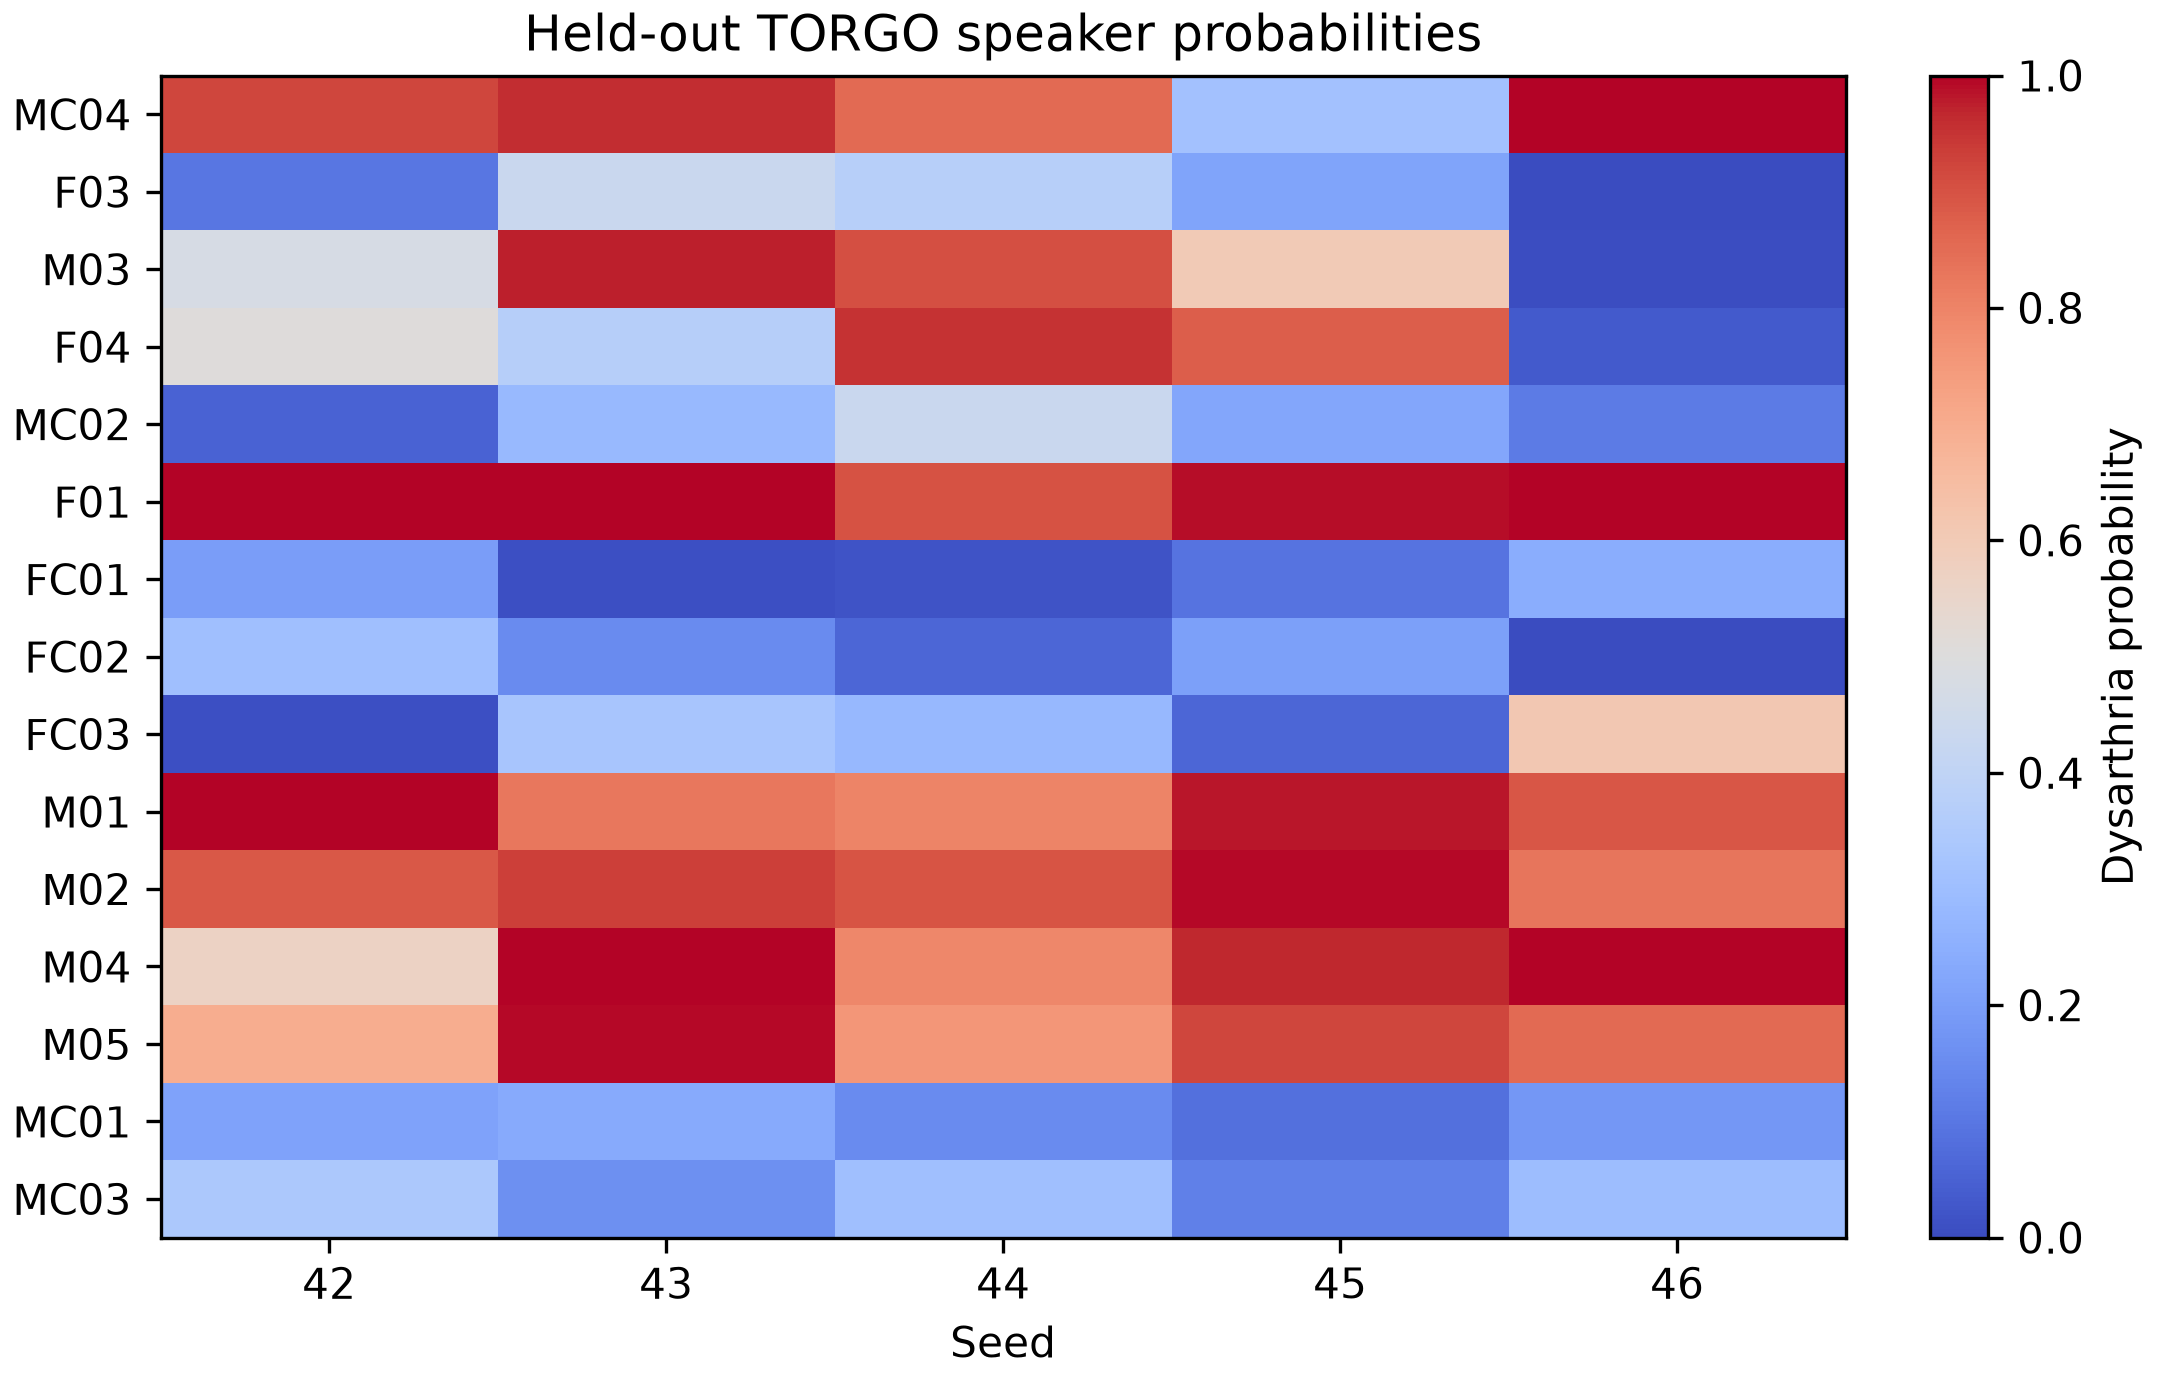

### Fig13 Confound Diagnostics

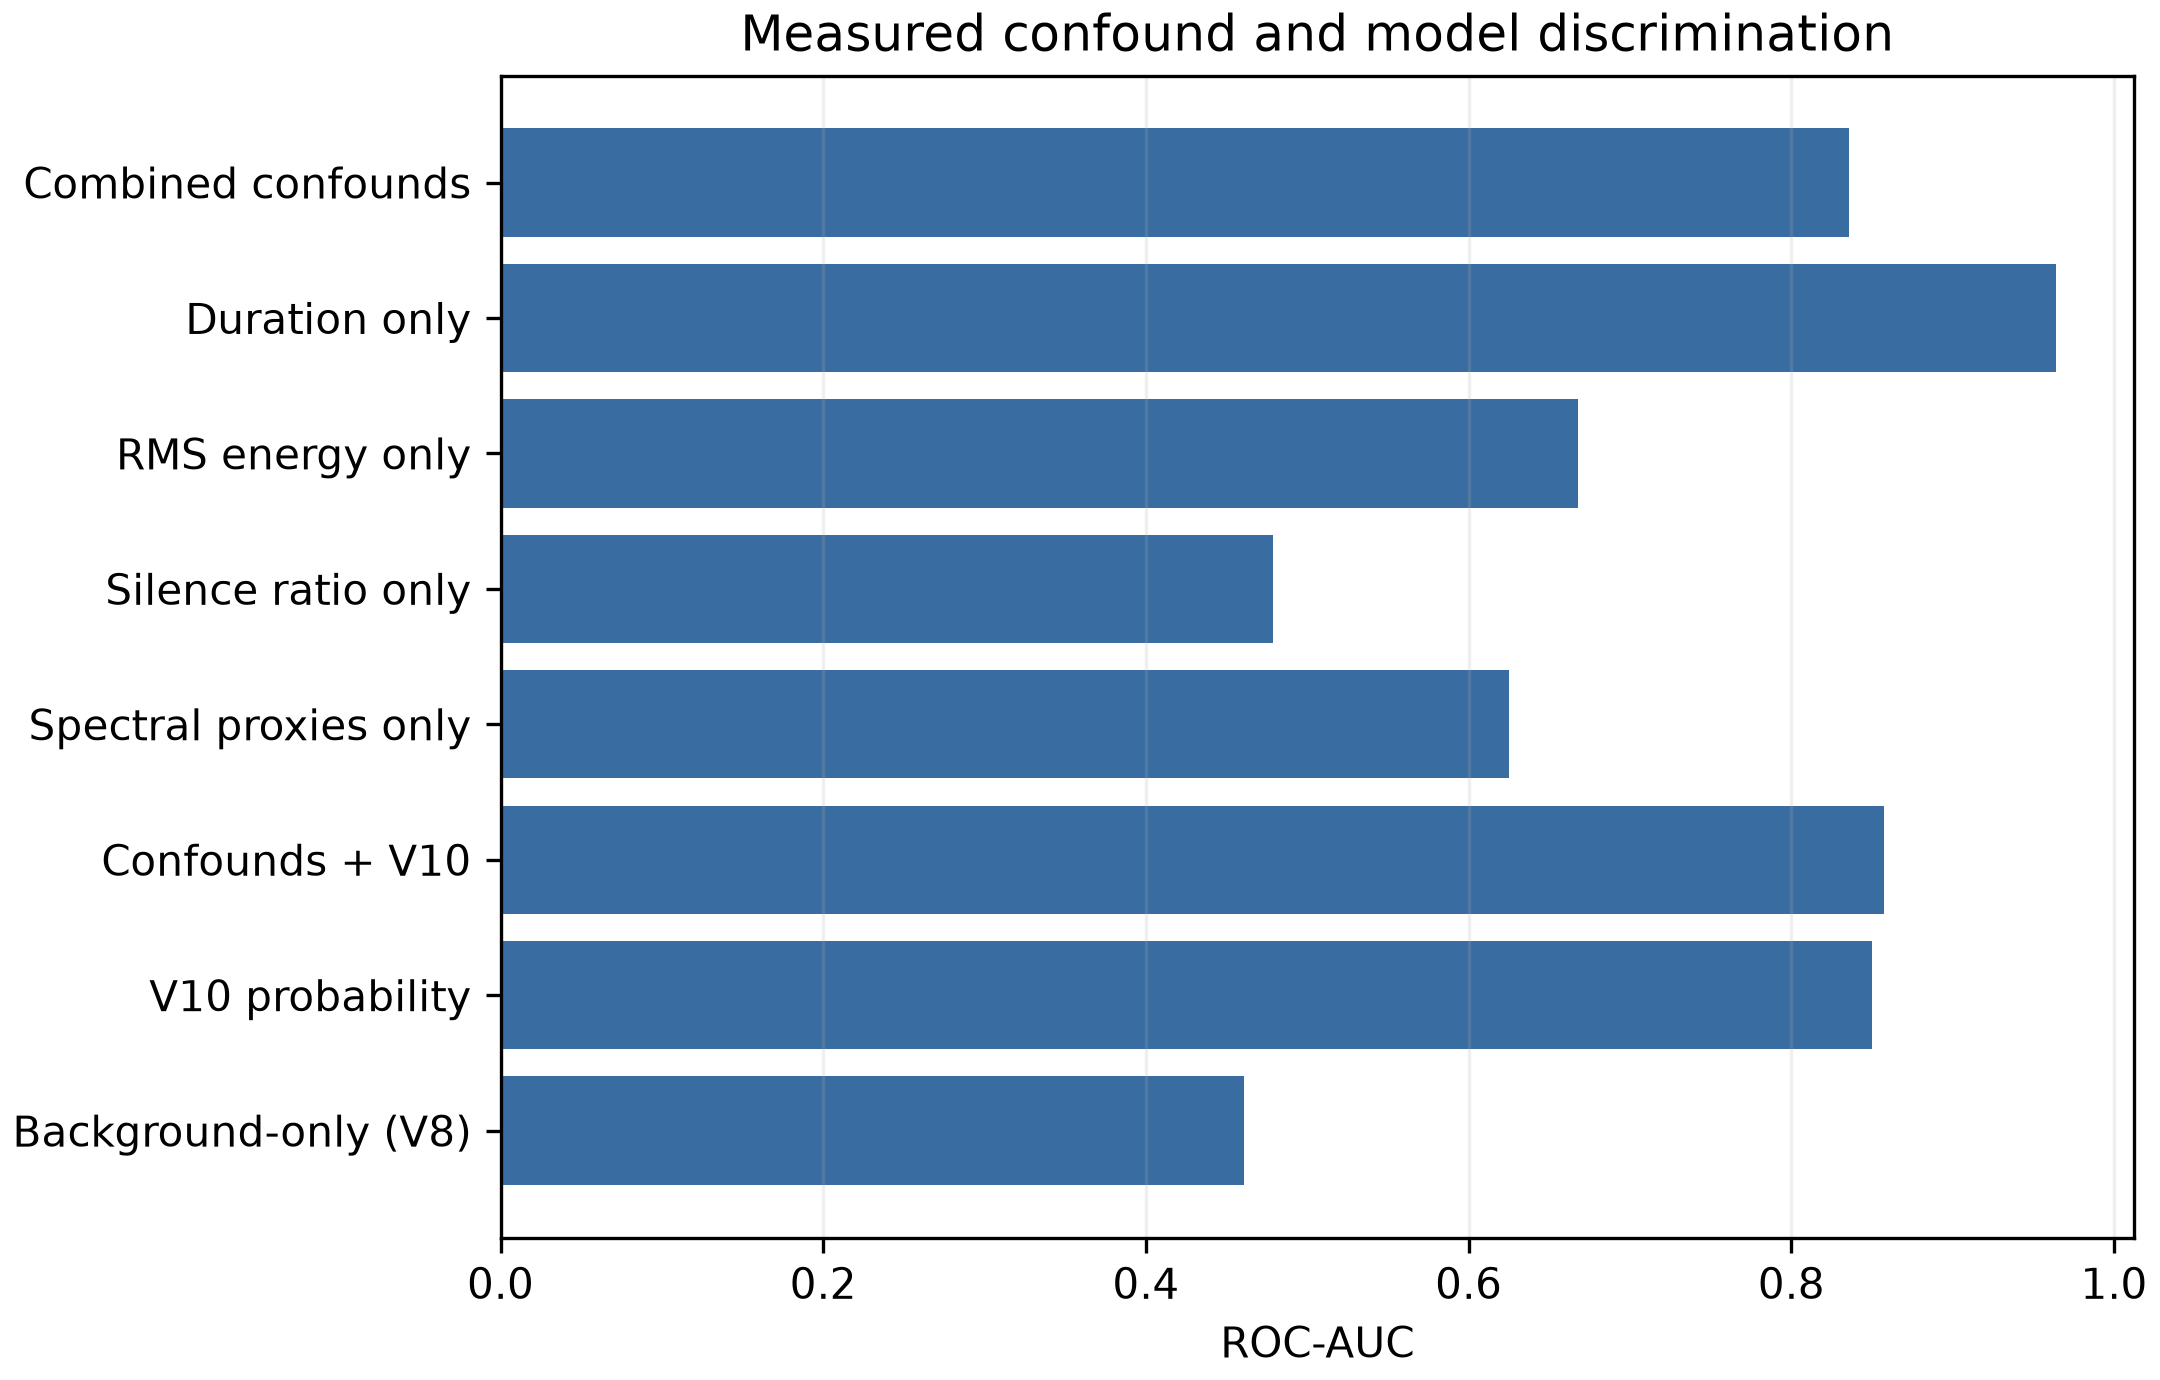

### Fig14 Calibration

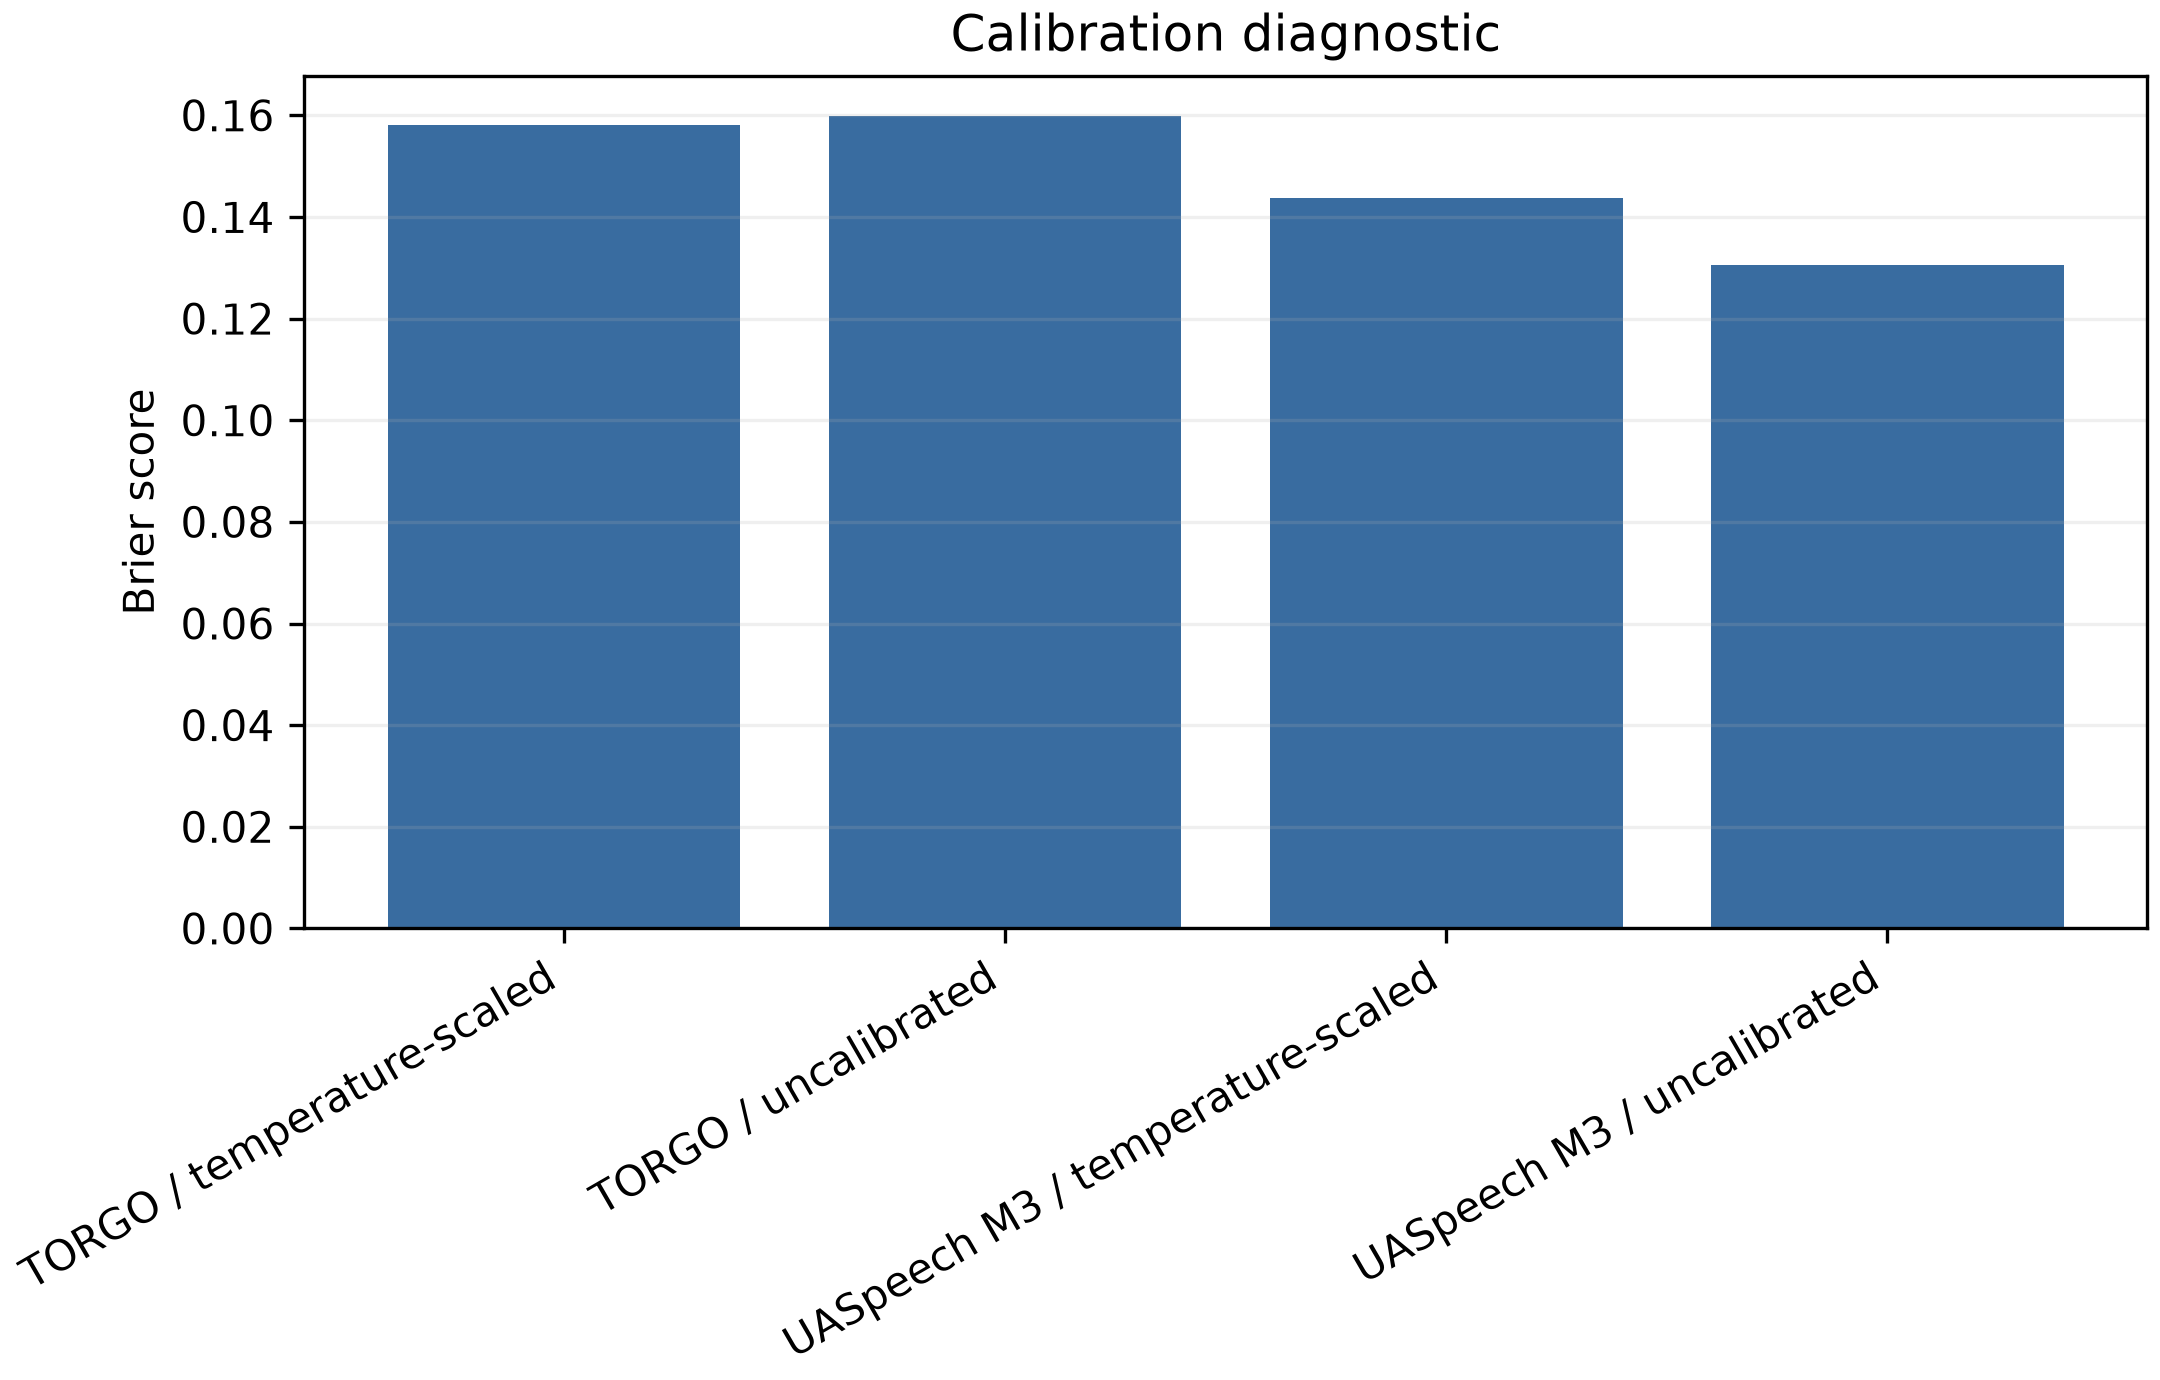

### Fig15 Attention Diagnostics

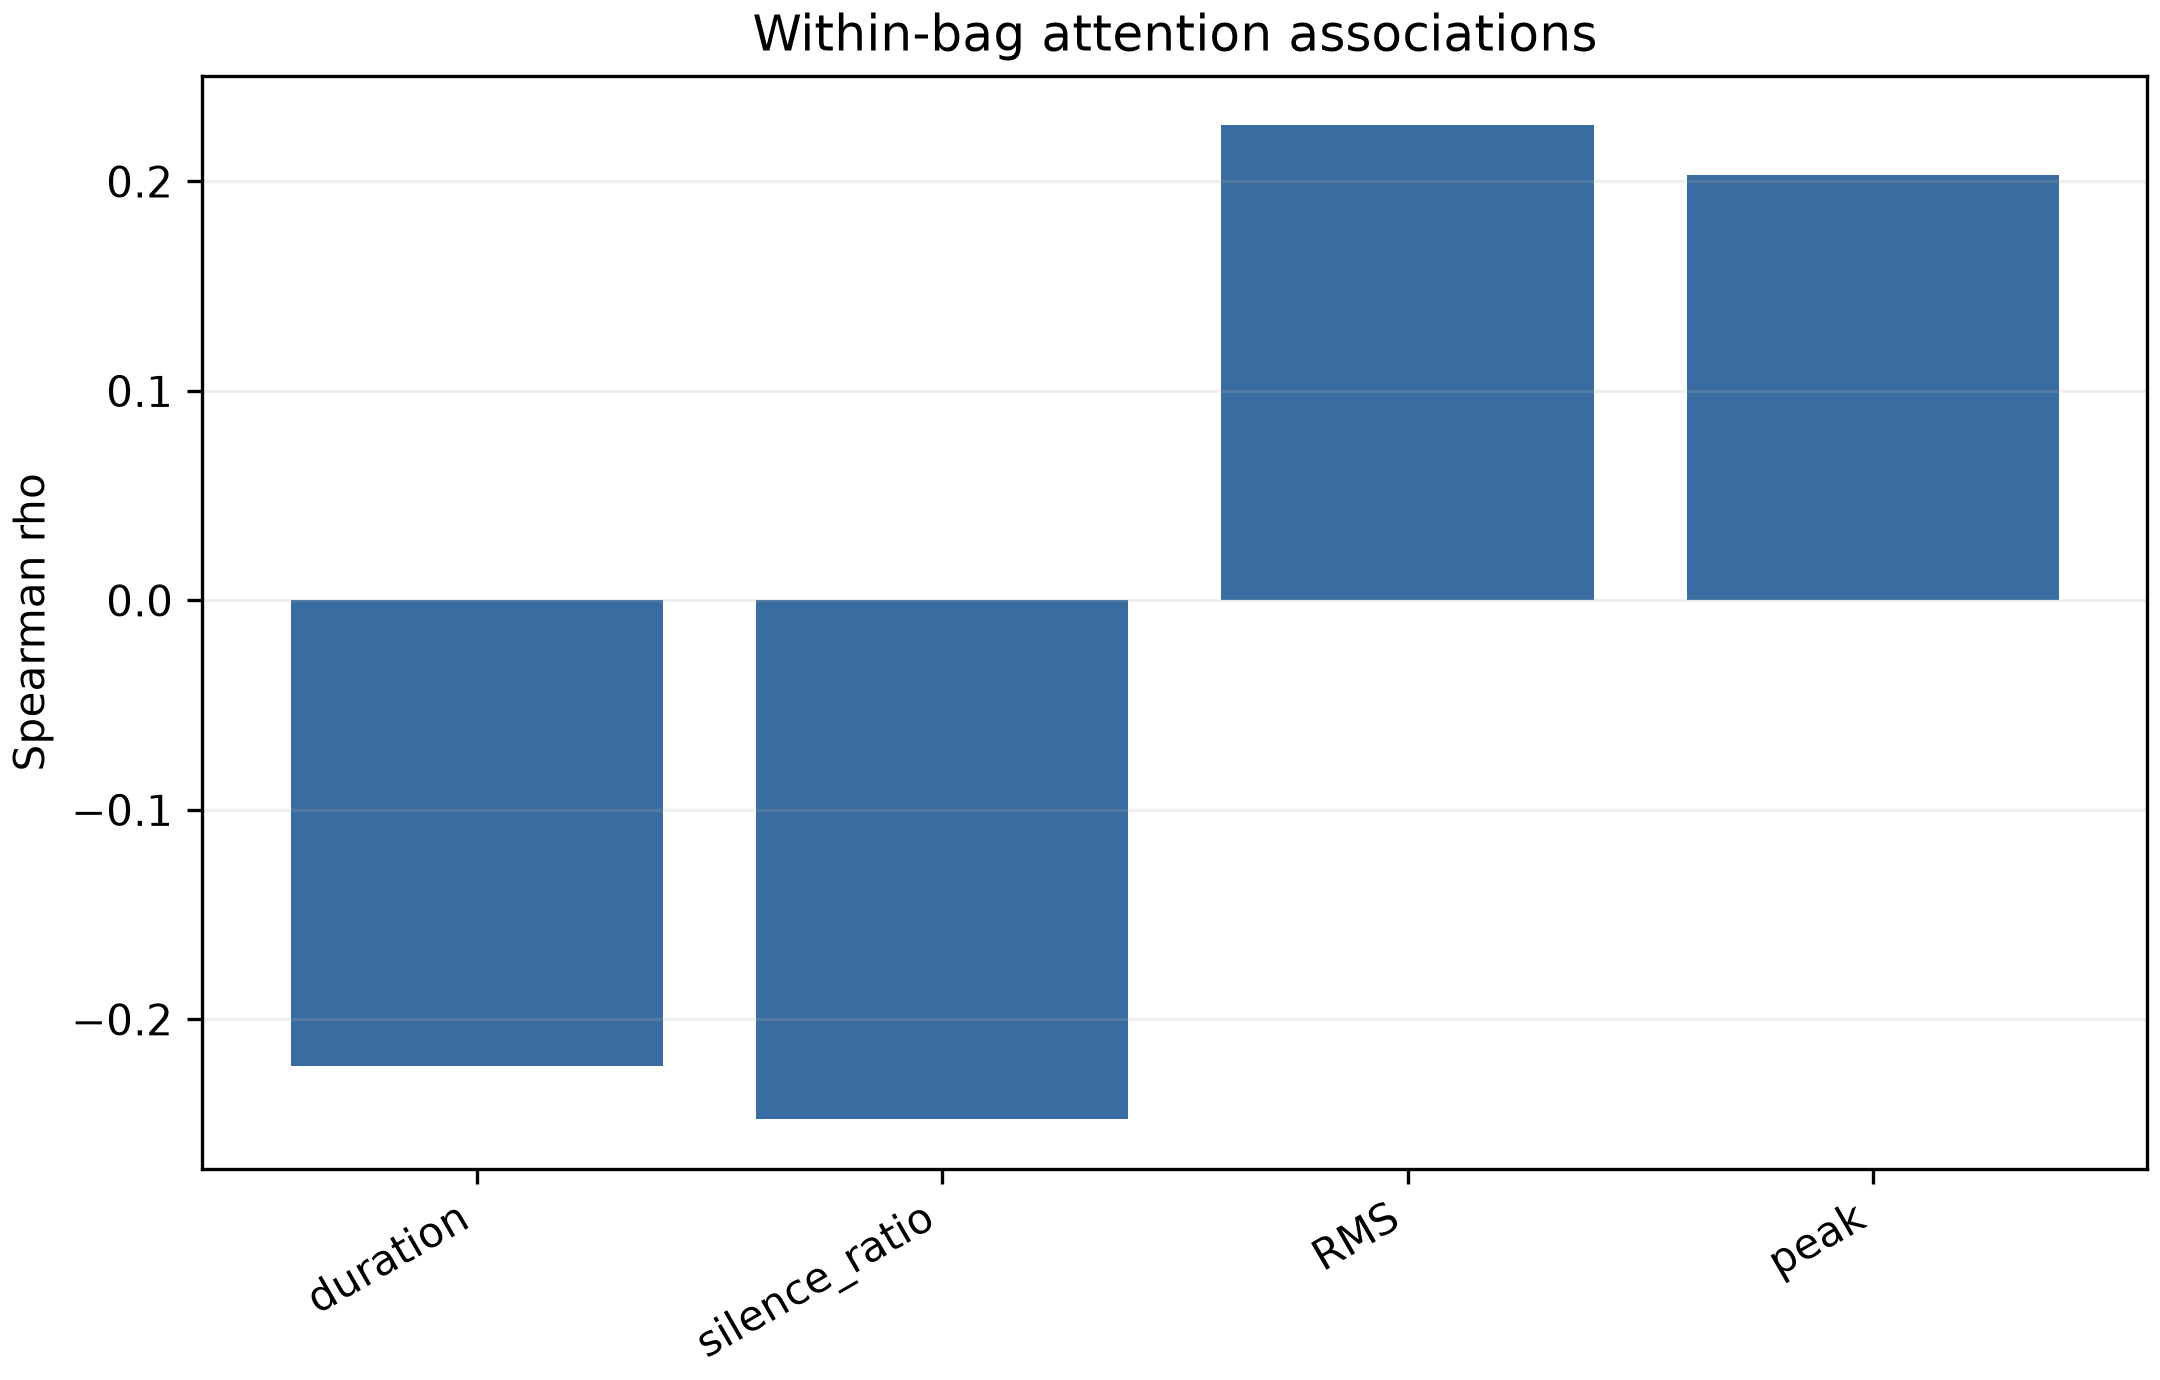

## Saved paper tables

Full-precision CSV and Markdown files remain in `v10/publication/tables/`.

### Master V8 V9 V10 Comparison

| Version | Main methodology | Accuracy | Balanced_Accuracy | Sensitivity | Specificity | F1 | ROC_AUC | PR_AUC | External validation status | External ROC-AUC | Main limitation |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| V8 | Variable-length V8 frozen WavLM speaker attention | 0.8533333333333333 | 0.8535714285714286 | 0.85 | 0.8571428571428571 | 0.8543277310924371 | 0.85 | 0.8835981379731381 | locked official UASpeech M3 complete | 0.9661538461538464 | Measured duration/artifact confounds |
| V9 | Fixed 1 s active-speech segments, K=20 deployment | 0.5866666666666667 | 0.5642857142857143 | 0.9 | 0.2285714285714285 | 0.7005339435545385 | 0.725 | 0.8350924075924077 | official M3 non-estimable under K=20 |  | Reduced TORGO performance and excluded external cohort |
| V10 | Fresh V8-reference retraining plus diagnostics and locked validation | 0.8533333333333333 | 0.8535714285714286 | 0.85 | 0.8571428571428571 | 0.8543277310924371 | 0.85 | 0.8835981379731381 | locked official UASpeech M3 complete | 0.9661538461538464 | Small speaker cohorts; confounding remains |


### Table01 Torgo Primary V10

| model | metric | mean | sd_across_repeated_seeds | speaker_bootstrap_lower_95 | speaker_bootstrap_upper_95 | n_speakers | n_seeds |
| --- | --- | --- | --- | --- | --- | --- | --- |
| V10-Reference | Accuracy | 0.8533333333333333 | 0.08692269873603534 | 0.7333333333333332 | 0.9600000000000002 | 15 | 5 |
| V10-Reference | Balanced_Accuracy | 0.8535714285714286 | 0.08149003006503311 | 0.7214285714285714 | 0.9607589285714285 | 15 | 5 |
| V10-Reference | Sensitivity | 0.85 | 0.16298006013006622 | 0.7 | 0.975 | 15 | 5 |
| V10-Reference | Specificity | 0.8571428571428571 | 0.0 | 0.6285714285714284 | 1.0 | 15 | 5 |
| V10-Reference | Precision | 0.8686507936507937 | 0.023660246326609246 | 0.7200000000000001 | 1.0 | 15 | 5 |
| V10-Reference | NPV | 0.8547619047619047 | 0.14878571238064758 | 0.760590909090909 | 0.975 | 15 | 5 |
| V10-Reference | F1 | 0.8543277310924371 | 0.09756538659118714 | 0.7183405572755419 | 0.9616666666666667 | 15 | 5 |
| V10-Reference | Macro_F1 | 0.8524935358758888 | 0.08675698386616279 | 0.7130807835954895 | 0.9598809523809525 | 15 | 5 |
| V10-Reference | ROC_AUC | 0.85 | 0.13634720834872197 | 0.6928571428571428 | 0.975 | 15 | 5 |
| V10-Reference | PR_AUC | 0.8835981379731381 | 0.08932031674450133 | 0.7777062937062936 | 0.9883333333333333 | 15 | 5 |
| V10-Reference | Brier | 0.15984264028358922 | 0.09049756185573703 | 0.06401405483999412 | 0.2764861186788681 | 15 | 5 |
| V10-Reference | ECE | 0.2300014902094673 | 0.11591354395277789 | 0.1619592434415243 | 0.35647771328141376 | 15 | 5 |


### Table02 V8 Vs V10

| Version | Main methodology | Accuracy | Balanced_Accuracy | Sensitivity | Specificity | F1 | ROC_AUC | PR_AUC | External validation status | External ROC-AUC | Main limitation |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| V8 | Variable-length V8 frozen WavLM speaker attention | 0.8533333333333333 | 0.8535714285714286 | 0.85 | 0.8571428571428571 | 0.8543277310924371 | 0.85 | 0.8835981379731381 | locked official UASpeech M3 complete | 0.9661538461538464 | Measured duration/artifact confounds |
| V10 | Fresh V8-reference retraining plus diagnostics and locked validation | 0.8533333333333333 | 0.8535714285714286 | 0.85 | 0.8571428571428571 | 0.8543277310924371 | 0.85 | 0.8835981379731381 | locked official UASpeech M3 complete | 0.9661538461538464 | Small speaker cohorts; confounding remains |


### Table03 Simple Baselines

| model | metric | mean | sd_across_repeated_seeds | speaker_bootstrap_lower_95 | speaker_bootstrap_upper_95 | n_speakers | n_seeds |
| --- | --- | --- | --- | --- | --- | --- | --- |
| MFCC Logistic Regression | Accuracy | 0.6933333333333332 | 0.059628479399994376 | 0.5066666666666666 | 0.8666666666666666 | 15 | 5 |
| MFCC Logistic Regression | Balanced_Accuracy | 0.6875000000000001 | 0.060556517706475625 | 0.4963392857142857 | 0.8571875000000001 | 15 | 5 |
| MFCC Logistic Regression | Sensitivity | 0.775 | 0.13693063937629152 | 0.55 | 0.975 | 15 | 5 |
| MFCC Logistic Regression | Specificity | 0.6 | 0.15649215928719035 | 0.28500000000000003 | 0.8571428571428571 | 15 | 5 |
| MFCC Logistic Regression | Precision | 0.6961904761904762 | 0.06372328927771921 | 0.5213359418359418 | 0.9008547008547009 | 15 | 5 |
| MFCC Logistic Regression | NPV | 0.7307142857142858 | 0.15915112827954772 | 0.5065 | 0.9714285714285713 | 15 | 5 |
| MFCC Logistic Regression | F1 | 0.7266666666666667 | 0.058452259722500635 | 0.539572192513369 | 0.8816553209002899 | 15 | 5 |
| MFCC Logistic Regression | Macro_F1 | 0.6828571428571428 | 0.06188529913826961 | 0.4762918660287081 | 0.8562191051982073 | 15 | 5 |
| MFCC Logistic Regression | ROC_AUC | 0.8571428571428571 | 0.0455269599427927 | 0.6678571428571428 | 0.9857142857142858 | 15 | 5 |
| MFCC Logistic Regression | PR_AUC | 0.8963528138528138 | 0.026302338706077212 | 0.7763663628038627 | 0.990407986111111 | 15 | 5 |
| MFCC Logistic Regression | Brier | 0.17753131501521152 | 0.03654893473436876 | 0.06454579620894307 | 0.2916440997262467 | 15 | 5 |
| MFCC Logistic Regression | ECE | 0.2069044431657412 | 0.05227564295320652 | 0.11641478880635961 | 0.3708449607947354 | 15 | 5 |
| MFCC RBF SVM | Accuracy | 0.5066666666666666 | 0.036514837167011066 | 0.44000000000000006 | 0.5599999999999999 | 15 | 5 |
| MFCC RBF SVM | Balanced_Accuracy | 0.47857142857142854 | 0.033763697144980426 | 0.41607142857142854 | 0.5321428571428571 | 15 | 5 |
| MFCC RBF SVM | Sensitivity | 0.9 | 0.10458250331675945 | 0.8 | 0.975 | 15 | 5 |
| MFCC RBF SVM | Specificity | 0.05714285714285714 | 0.07824607964359516 | 0.0 | 0.14285714285714285 | 15 | 5 |
| MFCC RBF SVM | Precision | 0.521025641025641 | 0.01930753907386327 | 0.47836829836829836 | 0.5556497668997669 | 15 | 5 |
| MFCC RBF SVM | NPV | 0.16666666666666666 | 0.23570226039551587 | 0.0 | 0.4 | 15 | 5 |
| MFCC RBF SVM | F1 | 0.658866930171278 | 0.0410452734905703 | 0.5945790427154843 | 0.7046706192358366 | 15 | 5 |
| MFCC RBF SVM | Macro_F1 | 0.3716556873078612 | 0.050241311718038695 | 0.3156542542126066 | 0.4273941907634699 | 15 | 5 |
| MFCC RBF SVM | ROC_AUC | 0.5321428571428573 | 0.22353548318980132 | 0.3820982142857143 | 0.6786160714285714 | 15 | 5 |
| MFCC RBF SVM | PR_AUC | 0.6583982683982683 | 0.14665582549706419 | 0.5804130019286269 | 0.7899123636779888 | 15 | 5 |
| MFCC RBF SVM | Brier | 0.27893231518368317 | 0.09643029391454135 | 0.2409596687931646 | 0.323020045675245 | 15 | 5 |
| MFCC RBF SVM | ECE | 0.23806321270637767 | 0.15574286043481894 | 0.2313846997818097 | 0.38765356722806504 | 15 | 5 |
| WavLM Final Layer Logistic Regression | Accuracy | 0.72 | 0.0730296743340222 | 0.5333333333333333 | 0.8933333333333333 | 15 | 5 |
| WavLM Final Layer Logistic Regression | Balanced_Accuracy | 0.7125 | 0.0750743678913497 | 0.5195535714285715 | 0.8875000000000002 | 15 | 5 |
| WavLM Final Layer Logistic Regression | Sensitivity | 0.825 | 0.06846531968814576 | 0.575 | 0.975 | 15 | 5 |
| WavLM Final Layer Logistic Regression | Specificity | 0.6 | 0.11952286093343939 | 0.2571428571428571 | 0.8857142857142858 | 15 | 5 |
| WavLM Final Layer Logistic Regression | Precision | 0.705050505050505 | 0.06753339252705771 | 0.5501136363636364 | 0.9055555555555556 | 15 | 5 |
| WavLM Final Layer Logistic Regression | NPV | 0.75 | 0.08333333333333337 | 0.46575649350649345 | 0.9667857142857142 | 15 | 5 |
| WavLM Final Layer Logistic Regression | F1 | 0.7591331269349846 | 0.060128908415158916 | 0.5926353936311367 | 0.9038624871001031 | 15 | 5 |
| WavLM Final Layer Logistic Regression | Macro_F1 | 0.7110350949360239 | 0.07831401827553351 | 0.49729930887825624 | 0.8894281028568954 | 15 | 5 |
| WavLM Final Layer Logistic Regression | ROC_AUC | 0.9071428571428571 | 0.05841224012070046 | 0.7571428571428571 | 1.0 | 15 | 5 |
| WavLM Final Layer Logistic Regression | PR_AUC | 0.9273457792207793 | 0.04370629098401037 | 0.8334023268398268 | 1.0 | 15 | 5 |
| WavLM Final Layer Logistic Regression | Brier | 0.1703940847769855 | 0.07278126750949641 | 0.041682445990827766 | 0.318411366224404 | 15 | 5 |
| WavLM Final Layer Logistic Regression | ECE | 0.18650489203076906 | 0.0716893254035697 | 0.07136471009150437 | 0.348225339653086 | 15 | 5 |


### Table04 Controlled Ablations

| model | metric | mean | sd | lower_95 | upper_95 |
| --- | --- | --- | --- | --- | --- |
| WavLM Last Layer + Mean Pooling | Accuracy | 0.8266666666666668 | 0.1011050059206873 | 0.6796666666666666 | 0.9466666666666668 |
| WavLM Last Layer + Mean Pooling | Balanced_Accuracy | 0.8285714285714285 | 0.1006990869990834 | 0.6839285714285716 | 0.9446428571428572 |
| WavLM Last Layer + Mean Pooling | Sensitivity | 0.8 | 0.1118033988749894 | 0.55 | 1.0 |
| WavLM Last Layer + Mean Pooling | Specificity | 0.8571428571428571 | 0.101015254455221 | 0.7142857142857142 | 1.0 |
| WavLM Last Layer + Mean Pooling | F1_dysarthric | 0.8300000000000001 | 0.1028415717931658 | 0.6428571428571429 | 0.9482352941176472 |
| WavLM Last Layer + Mean Pooling | ROC_AUC | 0.85 | 0.1090602248900176 | 0.6641964285714286 | 1.0 |
| WavLM Last Layer + Mean Pooling | PR_AUC | 0.9144711538461536 | 0.0553364929505443 | 0.8084333409645911 | 1.0 |
| WavLM Last Layer + Mean Pooling | Brier | 0.1577356778382823 | 0.0931612610907551 | 0.0492135795876642 | 0.2911834409486485 |
| WavLM Last Layer + Mean Pooling | ECE | 0.2165347897899695 | 0.0738315247741701 | 0.1038192867293435 | 0.3710754110296177 |
| WavLM Last Layer + Attention | Accuracy | 0.8266666666666668 | 0.0596284793999944 | 0.6533333333333334 | 0.96 |
| WavLM Last Layer + Attention | Balanced_Accuracy | 0.825 | 0.0556157553657051 | 0.6517857142857143 | 0.9571428571428572 |
| WavLM Last Layer + Attention | Sensitivity | 0.85 | 0.1369306393762915 | 0.65 | 1.0 |
| WavLM Last Layer + Attention | Specificity | 0.8 | 0.0782460796435951 | 0.5142857142857142 | 1.0 |
| WavLM Last Layer + Attention | F1_dysarthric | 0.8353408029878618 | 0.0721230628548701 | 0.6670886591478697 | 0.9556582633053216 |
| WavLM Last Layer + Attention | ROC_AUC | 0.8214285714285715 | 0.1191220005725565 | 0.6107142857142857 | 0.9785714285714286 |
| WavLM Last Layer + Attention | PR_AUC | 0.855113775113775 | 0.0807635708117845 | 0.7078009334415584 | 0.9892857142857142 |
| WavLM Last Layer + Attention | Brier | 0.181296122786071 | 0.0745080425265261 | 0.066900899681285 | 0.3290902014847786 |
| WavLM Last Layer + Attention | ECE | 0.2818666163727646 | 0.0680583416207596 | 0.1833832308322802 | 0.432448524831459 |
| WavLM Last-4 Mix + Mean Pooling | Accuracy | 0.8266666666666668 | 0.1011050059206873 | 0.6533333333333333 | 0.96 |
| WavLM Last-4 Mix + Mean Pooling | Balanced_Accuracy | 0.8267857142857142 | 0.1013304354222221 | 0.6589285714285714 | 0.9589285714285716 |
| WavLM Last-4 Mix + Mean Pooling | Sensitivity | 0.825 | 0.1118033988749894 | 0.575 | 1.0 |
| WavLM Last-4 Mix + Mean Pooling | Specificity | 0.8285714285714286 | 0.1195228609334393 | 0.5999999999999999 | 1.0 |
| WavLM Last-4 Mix + Mean Pooling | F1_dysarthric | 0.8347058823529412 | 0.1016571411953775 | 0.6521318681318681 | 0.96 |
| WavLM Last-4 Mix + Mean Pooling | ROC_AUC | 0.8892857142857142 | 0.0293422798663481 | 0.6927678571428572 | 1.0 |
| WavLM Last-4 Mix + Mean Pooling | PR_AUC | 0.9366891441891442 | 0.0280558956924575 | 0.8350108225108225 | 1.0 |
| WavLM Last-4 Mix + Mean Pooling | Brier | 0.1401020159856355 | 0.0881176421419551 | 0.0434882249756568 | 0.2713538676943522 |
| WavLM Last-4 Mix + Mean Pooling | ECE | 0.1971470856260199 | 0.0859509778409809 | 0.0961267478737131 | 0.348279990031207 |
| WavLM Last-4 Mix + Attention (V8 Reference) | Accuracy | 0.8533333333333333 | 0.0869226987360353 | 0.7066666666666668 | 0.9600000000000002 |
| WavLM Last-4 Mix + Attention (V8 Reference) | Balanced_Accuracy | 0.8535714285714286 | 0.0814900300650331 | 0.7142410714285713 | 0.9625 |
| WavLM Last-4 Mix + Attention (V8 Reference) | Sensitivity | 0.85 | 0.1629800601300662 | 0.699375 | 1.0 |
| WavLM Last-4 Mix + Attention (V8 Reference) | Specificity | 0.8571428571428571 | 0.0 | 0.6285714285714284 | 1.0 |
| WavLM Last-4 Mix + Attention (V8 Reference) | F1_dysarthric | 0.8543277310924371 | 0.0975653865911871 | 0.7071738539238539 | 0.9596638655462184 |
| WavLM Last-4 Mix + Attention (V8 Reference) | ROC_AUC | 0.85 | 0.1363472083487219 | 0.6785714285714286 | 0.975 |
| WavLM Last-4 Mix + Attention (V8 Reference) | PR_AUC | 0.8835981379731379 | 0.0893203167445013 | 0.7670923520923522 | 0.9883333333333332 |
| WavLM Last-4 Mix + Attention (V8 Reference) | Brier | 0.1598426402835892 | 0.090497561855737 | 0.0633621779786447 | 0.2846073522837334 |
| WavLM Last-4 Mix + Attention (V8 Reference) | ECE | 0.2300014902094673 | 0.1159135439527779 | 0.15877378295849 | 0.3783267716919026 |
| V10 mean only | Accuracy | 0.8266666666666668 | 0.07601169500660922 | 0.7066666666666667 | 0.9466666666666667 |
| V10 mean only | Balanced_Accuracy | 0.8267857142857142 | 0.0743273406723836 | 0.7035714285714285 | 0.9428571428571428 |
| V10 mean only | Sensitivity | 0.825 | 0.14252192813739223 | 0.6 | 0.975 |
| V10 mean only | Specificity | 0.8285714285714285 | 0.11952286093343935 | 0.6571428571428571 | 0.9428571428571428 |
| V10 mean only | Precision | 0.8536507936507937 | 0.0872900425267019 | 0.753292735042735 | 0.9555555555555555 |
| V10 mean only | NPV | 0.825 | 0.1263812574008592 | 0.6876190476190476 | 0.975 |
| V10 mean only | F1 | 0.8320074696545285 | 0.08434630070541695 | 0.6719240481740482 | 0.9428571428571428 |
| V10 mean only | Macro_F1 | 0.8245934784170078 | 0.07600303506655581 | 0.6888065681738282 | 0.9444444444444444 |
| V10 mean only | ROC_AUC | 0.8821428571428571 | 0.15546999185484942 | 0.7677678571428572 | 0.9785714285714286 |
| V10 mean only | PR_AUC | 0.9210187728937729 | 0.10482651821969426 | 0.8526885822510822 | 0.9883333333333333 |
| V10 mean only | Brier | 0.14257240329914894 | 0.0951753530175131 | 0.05337410386652918 | 0.23832465828394833 |
| V10 mean only | ECE | 0.22668410332963793 | 0.10780130908080308 | 0.15737804832821928 | 0.33992322758819377 |


### Table05 Uaspeech M3

| model | metric | mean | sd_across_repeated_seeds | speaker_bootstrap_lower_95 | speaker_bootstrap_upper_95 | n_speakers | n_seeds |
| --- | --- | --- | --- | --- | --- | --- | --- |
| V10 frozen M3 | Accuracy | 0.85 | 0.02988071523335987 | 0.7285714285714286 | 0.95 | 28 | 5 |
| V10 frozen M3 | Balanced_Accuracy | 0.8600000000000001 | 0.0278886675511359 | 0.7466666666666667 | 0.9533333333333334 | 28 | 5 |
| V10 frozen M3 | Sensitivity | 0.72 | 0.05577733510227173 | 0.49333333333333335 | 0.9066666666666666 | 28 | 5 |
| V10 frozen M3 | Specificity | 1.0 | 0.0 | 1.0 | 1.0 | 28 | 5 |
| V10 frozen M3 | Precision | 1.0 | 0.0 | 1.0 | 1.0 | 28 | 5 |
| V10 frozen M3 | NPV | 0.7572712418300653 | 0.03747542874786038 | 0.6332057416267942 | 0.9038095238095238 | 28 | 5 |
| V10 frozen M3 | F1 | 0.8362393162393161 | 0.03740036560657253 | 0.6590344438170523 | 0.9507389162561577 | 28 | 5 |
| V10 frozen M3 | Macro_F1 | 0.8488500993506556 | 0.03073616691535041 | 0.7166778074866309 | 0.9499726327312535 | 28 | 5 |
| V10 frozen M3 | ROC_AUC | 0.9661538461538463 | 0.012871692715908893 | 0.8984615384615384 | 1.0 | 28 | 5 |
| V10 frozen M3 | PR_AUC | 0.9763878159450915 | 0.007846675635658126 | 0.9352028044596778 | 1.0 | 28 | 5 |
| V10 frozen M3 | Brier | 0.13048092857058174 | 0.01957547107265941 | 0.04736922348434017 | 0.22776041443396083 | 28 | 5 |
| V10 frozen M3 | ECE | 0.16300726594988174 | 0.023597991037232157 | 0.09523624459281145 | 0.26395193019702407 | 28 | 5 |


### Table06 Severity Speakers

| speaker_id | official_intelligibility_score | official_intelligibility_group | official_rating_verbatim | mean_probability | number_of_seeds_detected | locked_prediction | probability_seed42 | probability_seed43 | probability_seed44 | probability_seed45 | probability_seed46 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| M01 | 15.0 | Very Low | Very low (15%) | 0.9495025158262648 | 5 | 1 | 0.998377327694783 | 0.8901188817759729 | 0.9970402508809136 | 0.9339168326641276 | 0.9280592861155278 |
| M04 | 2.0 | Very Low | Very low (2%) | 0.8987297613490371 | 5 | 1 | 0.9976487818819632 | 0.8360697637794067 | 0.9964714156947166 | 0.7973116023313576 | 0.8661472430577418 |
| M05 | 58.0 | Mid | Mid (58%) | 0.2781270323325892 | 1 | 0 | 0.1617004106730601 | 0.4820014700003082 | 0.1735360395428651 | 0.1687868104109218 | 0.4046104310357906 |
| M07 | 28.0 | Low | Low (28%) | 0.9811097698083866 | 5 | 1 | 0.9991023560701248 | 0.9590624763397192 | 0.9988711422928022 | 0.9775454100989904 | 0.9709674642402966 |
| M08 | 93.0 | High | high (93%) | 0.0405981560993253 | 0 | 0 | 0.0009376757940742 | 0.1057876329818014 | 0.00209766309669 | 0.0398682098829692 | 0.0542995987410917 |
| M09 | 86.0 | High | High (86%) | 0.8460712954793005 | 5 | 1 | 0.9854623908274748 | 0.7612049389658996 | 0.9922898444348336 | 0.7147968255071727 | 0.7766024776611218 |
| M10 | 93.0 | High | high (93%) | 0.437284432048722 | 3 | 1 | 0.1532804450135491 | 0.5830934498928069 | 0.6145382532318323 | 0.3693711802200451 | 0.4661388318853768 |
| F02 | 29.0 | Low | Low (29%) | 0.906345936768766 | 5 | 1 | 0.9953119076544956 | 0.853173637959468 | 0.9935609210400153 | 0.8113750885025361 | 0.878308128687315 |
| F03 | 6.0 | Very Low | Very low (6%) | 0.9621390508142562 | 5 | 1 | 0.9986280084122712 | 0.9178057440472548 | 0.9982487324761796 | 0.9458148016220496 | 0.950197967513526 |
| F04 | 62.0 | Mid | mid (62%) | 0.1820174550717243 | 0 | 0 | 0.0932395079778587 | 0.2804380559212746 | 0.1543415806840211 | 0.1279245061599025 | 0.254143624615565 |
| F05 | 95.0 | High | high (95%) | 0.7358605917154414 | 5 | 1 | 0.9211487176067514 | 0.6651734577870309 | 0.926309754787696 | 0.5314839328145925 | 0.6351870955811362 |
| M11 | 62.0 | Mid | mid (62%) | 0.8974827246725724 | 5 | 1 | 0.9969417139304207 | 0.8146164862238258 | 0.9962636840921366 | 0.7904064781242987 | 0.8891852609921801 |
| M12 | 7.4 | Very Low | very low (7.4%) | 0.9555905596162808 | 5 | 1 | 0.9986606270392874 | 0.9157722169385568 | 0.9972375230814862 | 0.938100294061549 | 0.9281821369605242 |
| M14 | 90.4 | High | High (90.4%) | 0.032757081989555 | 0 | 0 | 0.0007676793653327 | 0.0896399759964297 | 0.0015514700884437 | 0.0351898112508718 | 0.0366364732466972 |
| M16 | 43.0 | Low | low (43%) | 0.911444274620676 | 5 | 1 | 0.9984920869888502 | 0.8478634489061531 | 0.9974357648089068 | 0.8118067425926059 | 0.9016233298068635 |


### Table07 Severity Groups

| official_intelligibility_group | n_speakers | mean_probability | median_probability | sensitivity | mean_seeds_detected | intelligibility_min | intelligibility_max | detection_rate_across_seed_speaker_pairs | number_missed |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Very Low | 4 | 0.9414904719014596 | 0.9525465377212728 | 1.0 | 5.0 | 2.0 | 15.0 | 1.0 | 0 |
| Low | 3 | 0.932966660399276 | 0.911444274620676 | 1.0 | 5.0 | 28.0 | 43.0 | 1.0 | 0 |
| Mid | 3 | 0.4525424040256287 | 0.2781270323325892 | 0.3333333333333333 | 2.0 | 58.0 | 62.0 | 0.4 | 2 |
| High | 5 | 0.4185143114664688 | 0.437284432048722 | 0.6 | 2.6 | 86.0 | 95.0 | 0.52 | 2 |


### Table08 Channels

| model | metric | mean | sd_across_repeated_seeds | speaker_bootstrap_lower_95 | speaker_bootstrap_upper_95 | n_speakers | n_seeds |
| --- | --- | --- | --- | --- | --- | --- | --- |
| M2 | Accuracy | 0.8260869565217392 | 0.05324977701702562 | 0.7130434782608696 | 0.9219565217391302 | 23 | 5 |
| M2 | Balanced_Accuracy | 0.8 | 0.061237243569579464 | 0.6699999999999999 | 0.9102499999999997 | 23 | 5 |
| M2 | Sensitivity | 0.6 | 0.12247448713915887 | 0.34 | 0.8204999999999996 | 23 | 5 |
| M2 | Specificity | 1.0 | 0.0 | 1.0 | 1.0 | 23 | 5 |
| M2 | Precision | 1.0 | 0.0 | 1.0 | 1.0 | 23 | 5 |
| M2 | NPV | 0.7677244582043343 | 0.05244639812707957 | 0.6643358395989976 | 0.8959760338345862 | 23 | 5 |
| M2 | F1 | 0.7436974789915964 | 0.10308042374241257 | 0.4798534798534798 | 0.8992432060543515 | 23 | 5 |
| M2 | Macro_F1 | 0.8057424176567178 | 0.06865760563700542 | 0.6365479681608713 | 0.9177102126522146 | 23 | 5 |
| M2 | ROC_AUC | 0.9738461538461538 | 0.0042132504423474165 | 0.9061538461538461 | 1.0 | 23 | 5 |
| M2 | PR_AUC | 0.9688888888888888 | 0.0060858061945018235 | 0.9025331293706292 | 1.0 | 23 | 5 |
| M2 | Brier | 0.15125080360847581 | 0.024261574127935427 | 0.07154944567421398 | 0.24628495446597173 | 23 | 5 |
| M2 | ECE | 0.20118474036616538 | 0.022894416299000495 | 0.13112710344947387 | 0.29270472439067174 | 23 | 5 |
| M3 | Accuracy | 0.85 | 0.02988071523335987 | 0.7285714285714286 | 0.95 | 28 | 5 |
| M3 | Balanced_Accuracy | 0.8600000000000001 | 0.0278886675511359 | 0.7466666666666667 | 0.9533333333333334 | 28 | 5 |
| M3 | Sensitivity | 0.72 | 0.05577733510227173 | 0.49333333333333335 | 0.9066666666666666 | 28 | 5 |
| M3 | Specificity | 1.0 | 0.0 | 1.0 | 1.0 | 28 | 5 |
| M3 | Precision | 1.0 | 0.0 | 1.0 | 1.0 | 28 | 5 |
| M3 | NPV | 0.7572712418300653 | 0.03747542874786038 | 0.6332057416267942 | 0.9038095238095238 | 28 | 5 |
| M3 | F1 | 0.8362393162393161 | 0.03740036560657253 | 0.6590344438170523 | 0.9507389162561577 | 28 | 5 |
| M3 | Macro_F1 | 0.8488500993506556 | 0.03073616691535041 | 0.7166778074866309 | 0.9499726327312535 | 28 | 5 |
| M3 | ROC_AUC | 0.9661538461538463 | 0.012871692715908893 | 0.8984615384615384 | 1.0 | 28 | 5 |
| M3 | PR_AUC | 0.9763878159450915 | 0.007846675635658126 | 0.9352028044596778 | 1.0 | 28 | 5 |
| M3 | Brier | 0.13048092857058174 | 0.01957547107265941 | 0.04736922348434017 | 0.22776041443396083 | 28 | 5 |
| M3 | ECE | 0.16300726594988174 | 0.023597991037232157 | 0.09523624459281145 | 0.26395193019702407 | 28 | 5 |
| M4 | Accuracy | 0.7923076923076924 | 0.021066252211737146 | 0.6692307692307692 | 0.9076923076923077 | 26 | 5 |
| M4 | Balanced_Accuracy | 0.7923076923076924 | 0.021066252211737205 | 0.6692307692307692 | 0.9076923076923077 | 26 | 5 |
| M4 | Sensitivity | 0.5846153846153845 | 0.04213250442347435 | 0.3384615384615385 | 0.8153846153846154 | 26 | 5 |
| M4 | Specificity | 1.0 | 0.0 | 1.0 | 1.0 | 26 | 5 |
| M4 | Precision | 1.0 | 0.0 | 1.0 | 1.0 | 26 | 5 |
| M4 | NPV | 0.7070175438596491 | 0.020819863296979983 | 0.6021645021645021 | 0.845 | 26 | 5 |
| M4 | F1 | 0.7371428571428572 | 0.033906634512224566 | 0.5027863777089784 | 0.8978260869565217 | 26 | 5 |
| M4 | Macro_F1 | 0.7826843317972351 | 0.02413113302986954 | 0.6273239247852251 | 0.9067948168772757 | 26 | 5 |
| M4 | ROC_AUC | 0.8781065088757396 | 0.012963847514915198 | 0.7005325443786983 | 1.0 | 26 | 5 |
| M4 | PR_AUC | 0.9307093196658414 | 0.004052450826893321 | 0.8245856630688151 | 1.0 | 26 | 5 |
| M4 | Brier | 0.1727948796697256 | 0.02090053307586079 | 0.07806437942573917 | 0.27719882838321 | 26 | 5 |
| M4 | ECE | 0.21049093420295373 | 0.020170238179853316 | 0.11641268883744622 | 0.3149220317015825 | 26 | 5 |
| M5 | Accuracy | 0.9285714285714286 | 0.0 | 0.8214285714285714 | 1.0 | 28 | 5 |
| M5 | Balanced_Accuracy | 0.9333333333333333 | 0.0 | 0.8333333333333333 | 1.0 | 28 | 5 |
| M5 | Sensitivity | 0.8666666666666668 | 1.2412670766236366e-16 | 0.6666666666666666 | 1.0 | 28 | 5 |
| M5 | Specificity | 1.0 | 0.0 | 1.0 | 1.0 | 28 | 5 |
| M5 | Precision | 1.0 | 0.0 | 1.0 | 1.0 | 28 | 5 |
| M5 | NPV | 0.8666666666666668 | 1.2412670766236366e-16 | 0.7222222222222222 | 1.0 | 28 | 5 |
| M5 | F1 | 0.9285714285714286 | 0.0 | 0.8 | 1.0 | 28 | 5 |
| M5 | Macro_F1 | 0.9285714285714286 | 0.0 | 0.8193548387096774 | 1.0 | 28 | 5 |
| M5 | ROC_AUC | 0.9702564102564104 | 0.012243421934680386 | 0.8984358974358974 | 1.0 | 28 | 5 |
| M5 | PR_AUC | 0.9808886346300534 | 0.007030569445481279 | 0.9383952356758422 | 1.0 | 28 | 5 |
| M5 | Brier | 0.0744395782857584 | 0.0063230156668370625 | 0.00788820602783487 | 0.17015974257096925 | 28 | 5 |
| M5 | ECE | 0.09013762434618386 | 0.021008383140666168 | 0.051353028334478266 | 0.18360624585801733 | 28 | 5 |
| M6 | Accuracy | 0.8642857142857142 | 0.01597191412499854 | 0.7428571428571429 | 0.9642857142857142 | 28 | 5 |
| M6 | Balanced_Accuracy | 0.8702564102564103 | 0.01677479716286781 | 0.7538461538461538 | 0.9666666666666666 | 28 | 5 |
| M6 | Sensitivity | 0.7866666666666667 | 0.02981423969999724 | 0.5866666666666667 | 0.9339999999999994 | 28 | 5 |
| M6 | Specificity | 0.9538461538461538 | 0.04213250442347429 | 0.8615384615384617 | 1.0 | 28 | 5 |
| M6 | Precision | 0.9538461538461538 | 0.04213250442347429 | 0.8714285714285716 | 1.0 | 28 | 5 |
| M6 | NPV | 0.7954411764705883 | 0.01801395556660753 | 0.6606516290726817 | 0.9294196428571421 | 28 | 5 |
| M6 | F1 | 0.8612942612942612 | 0.016143095366093672 | 0.715323088455772 | 0.9655172413793103 | 28 | 5 |
| M6 | Macro_F1 | 0.8641118268704474 | 0.01599577219320232 | 0.7407804128725411 | 0.9642401021711366 | 28 | 5 |
| M6 | ROC_AUC | 0.9743589743589745 | 0.0062807429302133 | 0.918948717948718 | 1.0 | 28 | 5 |
| M6 | PR_AUC | 0.9792551098712089 | 0.004192893443024251 | 0.9409732951854434 | 1.0 | 28 | 5 |
| M6 | Brier | 0.11172840979569292 | 0.014064250909745932 | 0.03285427997418665 | 0.20958078961065213 | 28 | 5 |
| M6 | ECE | 0.14376009551150876 | 0.018771635750177335 | 0.06556169366835933 | 0.24847060016453557 | 28 | 5 |
| M7 | Accuracy | 0.8571428571428571 | 0.025253813613805295 | 0.7428571428571429 | 0.9571428571428571 | 28 | 5 |
| M7 | Balanced_Accuracy | 0.8666666666666668 | 0.02357022603955162 | 0.76 | 0.96 | 28 | 5 |
| M7 | Sensitivity | 0.7333333333333333 | 0.0471404520791032 | 0.52 | 0.9199999999999999 | 28 | 5 |
| M7 | Specificity | 1.0 | 0.0 | 1.0 | 1.0 | 28 | 5 |
| M7 | Precision | 1.0 | 0.0 | 1.0 | 1.0 | 28 | 5 |
| M7 | NPV | 0.7657679738562091 | 0.03195113013633778 | 0.645023923444976 | 0.9161904761904761 | 28 | 5 |
| M7 | F1 | 0.8454700854700855 | 0.03144091183869965 | 0.683794466403162 | 0.958128078817734 | 28 | 5 |
| M7 | Macro_F1 | 0.8562611828907712 | 0.025939413085528967 | 0.7335193365883902 | 0.957106367451195 | 28 | 5 |
| M7 | ROC_AUC | 0.9466666666666667 | 0.007777308147745153 | 0.8502564102564103 | 1.0 | 28 | 5 |
| M7 | PR_AUC | 0.9656232355411248 | 0.003574330146951788 | 0.909376873595288 | 1.0 | 28 | 5 |
| M7 | Brier | 0.12658677161645063 | 0.014244345672183936 | 0.042324028236413444 | 0.22163995621414748 | 28 | 5 |
| M7 | ECE | 0.15230332984408534 | 0.021869238126867804 | 0.08077982013906418 | 0.25209123953035506 | 28 | 5 |
| M8 | Accuracy | 0.8148148148148149 | 0.037037037037037035 | 0.6888888888888889 | 0.9333333333333333 | 27 | 5 |
| M8 | Balanced_Accuracy | 0.8192307692307693 | 0.03848115669207284 | 0.6967032967032967 | 0.9346153846153846 | 27 | 5 |
| M8 | Sensitivity | 0.7 | 0.03194382824999698 | 0.48571428571428577 | 0.9285714285714286 | 27 | 5 |
| M8 | Specificity | 0.9384615384615385 | 0.08426500884694865 | 0.8461538461538461 | 1.0 | 27 | 5 |
| M8 | Precision | 0.9333333333333333 | 0.09128709291752767 | 0.8666666666666666 | 1.0 | 27 | 5 |
| M8 | NPV | 0.7436601307189543 | 0.019740293392453125 | 0.6191036414565827 | 0.9140714285714284 | 27 | 5 |
| M8 | F1 | 0.7975473801560758 | 0.03312134543201422 | 0.62 | 0.9326137566137567 | 27 | 5 |
| M8 | Macro_F1 | 0.8131208482961639 | 0.03628983671257546 | 0.677379679144385 | 0.9331700279286486 | 27 | 5 |
| M8 | ROC_AUC | 0.8538461538461538 | 0.015829516803173543 | 0.6857142857142857 | 0.9857417582417582 | 27 | 5 |
| M8 | PR_AUC | 0.9072365734951546 | 0.009508067646890744 | 0.8062404375946689 | 0.9888208450046685 | 27 | 5 |
| M8 | Brier | 0.15731627868725753 | 0.014217643977372981 | 0.05977074747462822 | 0.26415904920126804 | 27 | 5 |
| M8 | ECE | 0.1769205636013126 | 0.025259226933323053 | 0.09958477063282734 | 0.2946537623271267 | 27 | 5 |


### Table09 Utterance Budget

| budget | Accuracy_mean | Accuracy_std | Balanced_Accuracy_mean | Balanced_Accuracy_std | Sensitivity_mean | Sensitivity_std | Specificity_mean | Specificity_std | ROC_AUC_mean | ROC_AUC_std | PR_AUC_mean | PR_AUC_std | Brier_mean | Brier_std | ECE_mean | ECE_std |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.8184285714285714 | 0.06518818142881416 | 0.824225641025641 | 0.06378180351119357 | 0.7430666666666667 | 0.10459673278153908 | 0.9053846153846155 | 0.08079877163906252 | 0.8805538461538461 | 0.056595110790589015 | 0.9189508285629374 | 0.04041371260954991 | 0.15435512615726493 | 0.05341701443250538 | 0.1738358558162238 | 0.05326675901200123 |
| 5 | 0.8352142857142857 | 0.05102378112444799 | 0.8454717948717948 | 0.04802399285597716 | 0.7018666666666666 | 0.09326498117421593 | 0.9890769230769231 | 0.026876901096446568 | 0.9360820512820512 | 0.03341355680510597 | 0.9598791456413512 | 0.019617076902482062 | 0.14119221110306748 | 0.03650784504242629 | 0.16907567473923282 | 0.0407975636348392 |
| 10 | 0.8432857142857142 | 0.04668710638299487 | 0.8535076923076923 | 0.043677355528397396 | 0.7104 | 0.08705232521743828 | 0.9966153846153847 | 0.015792346396068243 | 0.9473333333333334 | 0.02828331162626032 | 0.9671670558577905 | 0.015668441050923455 | 0.13616008581793687 | 0.03217938966454712 | 0.1657904379354461 | 0.03610595808717249 |
| 20 | 0.8487142857142856 | 0.04163467887238171 | 0.8587282051282051 | 0.03891082530040213 | 0.7185333333333334 | 0.07750036093608717 | 0.9989230769230769 | 0.009046776315139723 | 0.9543179487179487 | 0.022832426947402416 | 0.9707802575737927 | 0.012341940276347411 | 0.131917152767974 | 0.02662356850648432 | 0.1632311556239188 | 0.030995377257092074 |
| 50 | 0.8493571428571429 | 0.036919196558935 | 0.8593999999999999 | 0.03445791678833936 | 0.7188 | 0.0689158335766787 | 1.0 | 0.0 | 0.9603897435897436 | 0.017228324608015037 | 0.9736797256753307 | 0.009376815477970878 | 0.13042412395885597 | 0.022220142761356573 | 0.1629947116810238 | 0.026370472197832413 |
| all | 0.85 | 0.02988071523335987 | 0.86 | 0.027888667551135893 | 0.72 | 0.05577733510227172 | 1.0 | 0.0 | 0.9661538461538461 | 0.01287169271590892 | 0.9763878159450915 | 0.007846675635658149 | 0.1304809285705817 | 0.019575471072659414 | 0.1630072659498817 | 0.023597991037232167 |


### Table10 Confound Diagnostics

| model | metric | mean | sd_across_repeated_seeds | speaker_bootstrap_lower_95 | speaker_bootstrap_upper_95 | n_speakers | n_seeds |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Combined measured confounds | Accuracy | 0.6133333333333334 | 0.0869226987360353 |  |  | 15 | 5 |
| Combined measured confounds | Balanced_Accuracy | 0.5910714285714285 | 0.0871165065546462 |  |  | 15 | 5 |
| Combined measured confounds | Sensitivity | 0.925 | 0.11180339887498948 |  |  | 15 | 5 |
| Combined measured confounds | Specificity | 0.2571428571428571 | 0.11952286093343935 |  |  | 15 | 5 |
| Combined measured confounds | Precision | 0.5877122877122878 | 0.054445096186286915 |  |  | 15 | 5 |
| Combined measured confounds | NPV | 0.8166666666666667 | 0.29107081994288303 |  |  | 15 | 5 |
| Combined measured confounds | F1 | 0.7175848712690818 | 0.06748963434916097 |  |  | 15 | 5 |
| Combined measured confounds | Macro_F1 | 0.5472267790688844 | 0.1002373884303916 |  |  | 15 | 5 |
| Combined measured confounds | ROC_AUC | 0.8357142857142857 | 0.05976143046671967 |  |  | 15 | 5 |
| Combined measured confounds | PR_AUC | 0.8886214479964479 | 0.039926858080076094 |  |  | 15 | 5 |
| Combined measured confounds | Brier | 0.18190654624882038 | 0.0374486790176807 |  |  | 15 | 5 |
| Combined measured confounds | ECE | 0.24710790387528977 | 0.03298771337220813 |  |  | 15 | 5 |
| Duration only | Accuracy | 0.7066666666666667 | 0.07601169500660922 |  |  | 15 | 5 |
| Duration only | Balanced_Accuracy | 0.6892857142857143 | 0.08119601817421183 |  |  | 15 | 5 |
| Duration only | Sensitivity | 0.95 | 0.06846531968814577 |  |  | 15 | 5 |
| Duration only | Specificity | 0.42857142857142855 | 0.17496355305594127 |  |  | 15 | 5 |
| Duration only | Precision | 0.6603463203463203 | 0.06035942394394164 |  |  | 15 | 5 |
| Duration only | NPV | 0.9099999999999999 | 0.12449899597988731 |  |  | 15 | 5 |
| Duration only | F1 | 0.7767995746943115 | 0.0470466724120909 |  |  | 15 | 5 |
| Duration only | Macro_F1 | 0.6673391812865498 | 0.11232821780482803 |  |  | 15 | 5 |
| Duration only | ROC_AUC | 0.9642857142857142 | 0.028234621965789106 |  |  | 15 | 5 |
| Duration only | PR_AUC | 0.9726388888888888 | 0.020956522361196037 |  |  | 15 | 5 |
| Duration only | Brier | 0.10885593367184376 | 0.009893940140462434 |  |  | 15 | 5 |
| Duration only | ECE | 0.20134509327637584 | 0.05143856172241179 |  |  | 15 | 5 |
| RMS energy only | Accuracy | 0.5333333333333333 | 0.0 |  |  | 15 | 5 |
| RMS energy only | Balanced_Accuracy | 0.5 | 0.0 |  |  | 15 | 5 |
| RMS energy only | Sensitivity | 1.0 | 0.0 |  |  | 15 | 5 |
| RMS energy only | Specificity | 0.0 | 0.0 |  |  | 15 | 5 |
| RMS energy only | Precision | 0.5333333333333333 | 0.0 |  |  | 15 | 5 |
| RMS energy only | NPV | 0.0 | 0.0 |  |  | 15 | 5 |
| RMS energy only | F1 | 0.6956521739130435 | 0.0 |  |  | 15 | 5 |
| RMS energy only | Macro_F1 | 0.34782608695652173 | 0.0 |  |  | 15 | 5 |
| RMS energy only | ROC_AUC | 0.6678571428571429 | 0.027081698014469795 |  |  | 15 | 5 |
| RMS energy only | PR_AUC | 0.7978175990675991 | 0.025043849099397452 |  |  | 15 | 5 |
| RMS energy only | Brier | 0.22636242912490867 | 0.005105379614525866 |  |  | 15 | 5 |
| RMS energy only | ECE | 0.2722606363257965 | 0.035717959977683386 |  |  | 15 | 5 |
| Silence ratio only | Accuracy | 0.5199999999999999 | 0.02981423969999719 |  |  | 15 | 5 |
| Silence ratio only | Balanced_Accuracy | 0.4875 | 0.027950849718747367 |  |  | 15 | 5 |
| Silence ratio only | Sensitivity | 0.975 | 0.055901699437494734 |  |  | 15 | 5 |
| Silence ratio only | Specificity | 0.0 | 0.0 |  |  | 15 | 5 |
| Silence ratio only | Precision | 0.5266666666666666 | 0.014907119849998596 |  |  | 15 | 5 |
| Silence ratio only | NPV | 0.0 | 0.0 |  |  | 15 | 5 |
| Silence ratio only | F1 | 0.683794466403162 | 0.026514640049404615 |  |  | 15 | 5 |
| Silence ratio only | Macro_F1 | 0.341897233201581 | 0.013257320024702307 |  |  | 15 | 5 |
| Silence ratio only | ROC_AUC | 0.47857142857142865 | 0.07187361356249328 |  |  | 15 | 5 |
| Silence ratio only | PR_AUC | 0.5842948717948717 | 0.0584047972201674 |  |  | 15 | 5 |
| Silence ratio only | Brier | 0.2623528034227487 | 0.017389320926929398 |  |  | 15 | 5 |
| Silence ratio only | ECE | 0.19127366367425805 | 0.09001601214030275 |  |  | 15 | 5 |
| Spectral proxies only | Accuracy | 0.4800000000000001 | 0.029814239699997188 |  |  | 15 | 5 |
| Spectral proxies only | Balanced_Accuracy | 0.45357142857142857 | 0.0311861592795946 |  |  | 15 | 5 |
| Spectral proxies only | Sensitivity | 0.85 | 0.05590169943749474 |  |  | 15 | 5 |
| Spectral proxies only | Specificity | 0.05714285714285714 | 0.07824607964359516 |  |  | 15 | 5 |
| Spectral proxies only | Precision | 0.5076923076923077 | 0.017200522903844526 |  |  | 15 | 5 |
| Spectral proxies only | NPV | 0.16666666666666666 | 0.23570226039551587 |  |  | 15 | 5 |
| Spectral proxies only | F1 | 0.6351515151515151 | 0.023628592351052028 |  |  | 15 | 5 |
| Spectral proxies only | Macro_F1 | 0.35979797979797984 | 0.05911205699444124 |  |  | 15 | 5 |
| Spectral proxies only | ROC_AUC | 0.625 | 0.09192526911595535 |  |  | 15 | 5 |
| Spectral proxies only | PR_AUC | 0.7154247835497836 | 0.09233818541786153 |  |  | 15 | 5 |
| Spectral proxies only | Brier | 0.2628018033665472 | 0.05097583371266279 |  |  | 15 | 5 |
| Spectral proxies only | ECE | 0.27725284985690224 | 0.0613096016998182 |  |  | 15 | 5 |
| Combined measured confounds | Accuracy | 0.6133333333333334 | 0.0869226987360353 |  |  | 15 | 5 |
| Combined measured confounds | Balanced_Accuracy | 0.5910714285714285 | 0.0871165065546462 |  |  | 15 | 5 |
| Combined measured confounds | Sensitivity | 0.925 | 0.11180339887498948 |  |  | 15 | 5 |
| Combined measured confounds | Specificity | 0.2571428571428571 | 0.11952286093343935 |  |  | 15 | 5 |
| Combined measured confounds | Precision | 0.5877122877122878 | 0.054445096186286915 |  |  | 15 | 5 |
| Combined measured confounds | NPV | 0.8166666666666667 | 0.29107081994288303 |  |  | 15 | 5 |
| Combined measured confounds | F1 | 0.7175848712690818 | 0.06748963434916097 |  |  | 15 | 5 |
| Combined measured confounds | Macro_F1 | 0.5472267790688844 | 0.1002373884303916 |  |  | 15 | 5 |
| Combined measured confounds | ROC_AUC | 0.8357142857142857 | 0.05976143046671967 |  |  | 15 | 5 |
| Combined measured confounds | PR_AUC | 0.8886214479964479 | 0.039926858080076094 |  |  | 15 | 5 |
| Combined measured confounds | Brier | 0.18190654624882038 | 0.0374486790176807 |  |  | 15 | 5 |
| Combined measured confounds | ECE | 0.24710790387528977 | 0.03298771337220813 |  |  | 15 | 5 |
| Confounds + V10 probability | Accuracy | 0.6533333333333333 | 0.05577733510227169 |  |  | 15 | 5 |
| Confounds + V10 probability | Balanced_Accuracy | 0.6357142857142856 | 0.062308379722742516 |  |  | 15 | 5 |
| Confounds + V10 probability | Sensitivity | 0.9 | 0.10458250331675945 |  |  | 15 | 5 |
| Confounds + V10 probability | Specificity | 0.3714285714285714 | 0.19166296949998196 |  |  | 15 | 5 |
| Confounds + V10 probability | Precision | 0.6273626373626373 | 0.05484447448506324 |  |  | 15 | 5 |
| Confounds + V10 probability | NPV | 0.8266666666666668 | 0.16733200530681513 |  |  | 15 | 5 |
| Confounds + V10 probability | F1 | 0.7345675239792888 | 0.0342250544968824 |  |  | 15 | 5 |
| Confounds + V10 probability | Macro_F1 | 0.6049333346392171 | 0.09138509132074876 |  |  | 15 | 5 |
| Confounds + V10 probability | ROC_AUC | 0.8571428571428571 | 0.06561133239597797 |  |  | 15 | 5 |
| Confounds + V10 probability | PR_AUC | 0.8982314213564214 | 0.04816698956759393 |  |  | 15 | 5 |
| Confounds + V10 probability | Brier | 0.16928593143656584 | 0.043416550060393 |  |  | 15 | 5 |
| Confounds + V10 probability | ECE | 0.23771673419244205 | 0.03838996600602122 |  |  | 15 | 5 |
| V10 probability only | Accuracy | 0.8533333333333333 | 0.08692269873603534 |  |  | 15 | 5 |
| V10 probability only | Balanced_Accuracy | 0.8535714285714286 | 0.08149003006503311 |  |  | 15 | 5 |
| V10 probability only | Sensitivity | 0.85 | 0.16298006013006622 |  |  | 15 | 5 |
| V10 probability only | Specificity | 0.8571428571428571 | 0.0 |  |  | 15 | 5 |
| V10 probability only | Precision | 0.8686507936507937 | 0.023660246326609246 |  |  | 15 | 5 |
| V10 probability only | NPV | 0.8547619047619047 | 0.14878571238064758 |  |  | 15 | 5 |
| V10 probability only | F1 | 0.8543277310924371 | 0.09756538659118714 |  |  | 15 | 5 |
| V10 probability only | Macro_F1 | 0.8524935358758888 | 0.08675698386616279 |  |  | 15 | 5 |
| V10 probability only | ROC_AUC | 0.85 | 0.13634720834872197 |  |  | 15 | 5 |
| V10 probability only | PR_AUC | 0.8835981379731381 | 0.08932031674450133 |  |  | 15 | 5 |
| V10 probability only | Brier | 0.15984264028358922 | 0.09049756185573703 |  |  | 15 | 5 |
| V10 probability only | ECE | 0.2300014902094673 | 0.11591354395277789 |  |  | 15 | 5 |
| Inherited V8 background-only diagnostic | Accuracy | 0.48 | 0.05577733510227169 |  |  | 15 | 5 |
| Inherited V8 background-only diagnostic | Balanced_Accuracy | 0.45178571428571423 | 0.05453011244500882 |  |  | 15 | 5 |
| Inherited V8 background-only diagnostic | Sensitivity | 0.875 | 0.08838834764831845 |  |  | 15 | 5 |
| Inherited V8 background-only diagnostic | Specificity | 0.02857142857142857 | 0.06388765649999399 |  |  | 15 | 5 |
| Inherited V8 background-only diagnostic | Precision | 0.5066666666666666 | 0.03101398382401755 |  |  | 15 | 5 |
| Inherited V8 background-only diagnostic | NPV | 0.1 | 0.223606797749979 |  |  | 15 | 5 |
| Inherited V8 background-only diagnostic | F1 | 0.6412949369471108 | 0.046174609801253465 |  |  | 15 | 5 |
| Inherited V8 background-only diagnostic | Macro_F1 | 0.34286969069577766 | 0.06088456060473213 |  |  | 15 | 5 |
| Inherited V8 background-only diagnostic | ROC_AUC | 0.46071428571428574 | 0.0989421084085362 |  |  | 15 | 5 |
| Inherited V8 background-only diagnostic | PR_AUC | 0.5570643939393939 | 0.05928927137330942 |  |  | 15 | 5 |
| Inherited V8 background-only diagnostic | Brier | 0.3905374206641579 | 0.024092244634065303 |  |  | 15 | 5 |
| Inherited V8 background-only diagnostic | ECE | 0.3972474477237865 | 0.0072590595493867574 |  |  | 15 | 5 |


### Table11 Speaker Errors

| speaker_id | diagnosis | label | wrong_seeds | mean_duration | silence_ratio | RMS | microphone_distribution | artifact_score | V10_probability | probability_seed42 | probability_seed43 | probability_seed44 | probability_seed45 | probability_seed46 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| MC04 | control | 0 | 4 | 2.146455111940299 | 0.4918811722034625 | 0.0909953188666387 | {"array": 1021, "head": 654} | 0.5197788887593283 | 0.80843308163617 | 0.9205264317140064 | 0.9592730208165636 | 0.8516895093490869 | 0.3132225290028678 | 0.9974539172983248 |
| F03 | dysarthric | 1 | 3 | 2.7276445175438595 | 0.392946004522329 | 0.0364418556046123 | {"array": 848, "head": 577} | 0.3285303591008772 | 0.2254562875616072 | 0.0993846856949879 | 0.4332159401398532 | 0.3749741710348757 | 0.2171037233980839 | 0.0026029175402355 |
| M03 | dysarthric | 1 | 2 | 3.528236708482676 | 0.6956759202655677 | 0.0801908495994573 | {"array": 416, "head": 421} | 0.7015821668836806 | 0.5918252707129126 | 0.4740888371784696 | 0.9750135110190996 | 0.905104488243488 | 0.6006081224021991 | 0.0043113947213065 |
| F04 | dysarthric | 1 | 1 | 3.39974606017192 | 0.5655452908024741 | 0.1038214069926 | {"array": 448, "head": 250} | 0.6409755149338512 | 0.5474475901473512 | 0.5048354517912853 | 0.3694696529870823 | 0.9517964271733136 | 0.8787109449292042 | 0.0324254738558703 |
| MC02 | control | 0 | 1 | 3.675715433563417 | 0.5843354448388041 | 0.0626258959860265 | {"array": 695, "head": 464} | 0.6114762629590433 | 0.220520569838533 | 0.0528513405851065 | 0.2850475511858298 | 0.4303727910653142 | 0.2242281798373772 | 0.1101029865190378 |
| F01 | dysarthric | 1 | 0 | 2.798827537593985 | 0.5178203144150614 | 0.056631593240557 | {"array": 134, "head": 132} | 0.3578051803703594 | 0.9770161676415734 | 0.9975770280245724 | 0.9981892946059728 | 0.8986045652769966 | 0.991747762648284 | 0.9989621876520408 |
| FC01 | control | 0 | 0 | 3.768512529832936 | 0.3483568680000884 | 0.0332574485514345 | {"array": 255, "head": 164} | 0.3246364547984412 | 0.1121335383100143 | 0.1962309972555503 | 0.011683713720571 | 0.0156882304667408 | 0.092388903844549 | 0.2446758462626607 |
| FC02 | control | 0 | 0 | 2.9650985459973462 | 0.5578224633545668 | 0.0634953632472764 | {"array": 1261, "head": 1000} | 0.5961567314785701 | 0.1448058340392244 | 0.3068458314095567 | 0.1516738473496251 | 0.0612152436328222 | 0.203453669422032 | 0.0008405783820865 |
| FC03 | control | 0 | 0 | 2.723447206913828 | 0.4447397921563166 | 0.0679827365805508 | {"array": 994, "head": 1002} | 0.5745549326191446 | 0.2589700334189394 | 0.0092059004997294 | 0.3314257269366282 | 0.2799989691329659 | 0.0621634574477747 | 0.612056113077599 |
| M01 | dysarthric | 1 | 0 | 4.043702477331607 | 0.5513102560158948 | 0.1315162746480231 | {"array": 386, "head": 386} | 0.5807214845647466 | 0.8991886887052674 | 0.9977546331552436 | 0.8243256219105483 | 0.8002873877839984 | 0.982334260940826 | 0.8912415397357211 |
| M02 | dysarthric | 1 | 0 | 3.777830732385661 | 0.5533969610352336 | 0.1193995255675706 | {"array": 400, "head": 409} | 0.5780477818511472 | 0.908402915904038 | 0.8898804826269955 | 0.9319363070980312 | 0.8958509268119618 | 0.9952783904298276 | 0.829068472553373 |
| M04 | dysarthric | 1 | 0 | 4.494575818245126 | 0.3820304120406625 | 0.1139830418607089 | {"array": 420, "head": 298} | 0.7076620032860376 | 0.863790115539129 | 0.5640630504828424 | 0.99784709494381 | 0.7920725606144113 | 0.9655544664192572 | 0.9994134052353236 |
| M05 | dysarthric | 1 | 0 | 4.556397273425499 | 0.3396758134467144 | 0.1421029983737179 | {"array": 128, "head": 523} | 0.6792142665880616 | 0.8437498771268916 | 0.696947168571858 | 0.993126344952679 | 0.7575182625585389 | 0.9188218674158772 | 0.8523357421355049 |
| MC01 | control | 0 | 0 | 3.130381571525271 | 0.4116751395285329 | 0.0349147716160306 | {"array": 1108, "head": 1108} | 0.3378275929805604 | 0.1735240427001538 | 0.2110502071797537 | 0.2380472557441645 | 0.1497444323971287 | 0.0852361404814588 | 0.1835421776982637 |
| MC03 | control | 0 | 0 | 2.195657986111111 | 0.4101650663358472 | 0.0621054489623318 | {"array": 900, "head": 828} | 0.5077025448834455 | 0.246415122403092 | 0.3437025438459248 | 0.1622561392970513 | 0.3073146805601381 | 0.1214070545353868 | 0.297395193776959 |


### Table12 Epoch Policy

| seed | outer_fold | median_inner_best_epoch | pooled_one_se_epoch |
| --- | --- | --- | --- |
| 42 | 0 | 6 | 4 |
| 42 | 1 | 21 | 6 |
| 42 | 2 | 6 | 3 |
| 42 | 3 | 5 | 1 |
| 42 | 4 | 35 | 6 |
| 43 | 0 | 8 | 5 |
| 43 | 1 | 6 | 2 |
| 43 | 2 | 26 | 12 |
| 43 | 3 | 26 | 12 |
| 43 | 4 | 8 | 1 |
| 44 | 0 | 7 | 3 |
| 44 | 1 | 16 | 16 |
| 44 | 2 | 6 | 2 |
| 44 | 3 | 8 | 4 |
| 44 | 4 | 15 | 3 |
| 45 | 0 | 17 | 13 |
| 45 | 1 | 16 | 4 |
| 45 | 2 | 18 | 5 |
| 45 | 3 | 12 | 6 |
| 45 | 4 | 10 | 1 |
| 46 | 0 | 8 | 1 |
| 46 | 1 | 32 | 13 |
| 46 | 2 | 38 | 19 |
| 46 | 3 | 39 | 20 |
| 46 | 4 | 6 | 2 |


### Table13 Matched Content

| model_arm | seed | n_speakers | Accuracy | Balanced_Accuracy | Sensitivity | Specificity | F1_dysarthric | ROC_AUC | PR_AUC | Brier | ECE |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| speech_only | 42 | 25 | 0.84 | 0.8571428571428572 | 0.7142857142857143 | 1.0 | 0.8333333333333334 | 0.9675324675324676 | 0.9778711484593836 | 0.1394766005399284 | 0.1510808625346676 |
| speech_only | 43 | 25 | 0.92 | 0.9285714285714286 | 0.8571428571428571 | 1.0 | 0.9230769230769232 | 0.9870129870129868 | 0.9910714285714284 | 0.105408184594097 | 0.2067883097683465 |
| speech_only | 44 | 25 | 0.84 | 0.8571428571428572 | 0.7142857142857143 | 1.0 | 0.8333333333333334 | 0.9805194805194806 | 0.9873949579831932 | 0.1217057804961663 | 0.1402026509445723 |
| speech_only | 45 | 25 | 0.8 | 0.8214285714285714 | 0.6428571428571429 | 1.0 | 0.782608695652174 | 0.9805194805194803 | 0.985969387755102 | 0.1555850101939419 | 0.2200023869195144 |
| speech_only | 46 | 25 | 0.88 | 0.8928571428571428 | 0.7857142857142857 | 1.0 | 0.88 | 0.9935064935064934 | 0.9952380952380953 | 0.1131898478732605 | 0.1681117122958977 |


### Table14 Matched Duration

| model_arm | seed | n_speakers | Accuracy | Balanced_Accuracy | Sensitivity | Specificity | F1_dysarthric | ROC_AUC | PR_AUC | Brier | ECE |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| V10 frozen duration-overlap subset | 42 | 15 | 0.8666666666666667 | 0.8660714285714286 | 0.875 | 0.8571428571428571 | 0.875 | 0.8392857142857143 | 0.8726076007326008 | 0.1976491075599925 | 0.3092183572822213 |
| V10 frozen duration-overlap subset | 43 | 15 | 0.8666666666666667 | 0.8660714285714286 | 0.875 | 0.8571428571428571 | 0.875 | 0.9285714285714286 | 0.9317956349206348 | 0.1351142207644279 | 0.2254737658666325 |
| V10 frozen duration-overlap subset | 44 | 15 | 0.8666666666666667 | 0.8660714285714286 | 0.875 | 0.8571428571428571 | 0.875 | 0.9107142857142856 | 0.9206845238095238 | 0.1115025325295286 | 0.0765507335398065 |
| V10 frozen duration-overlap subset | 45 | 15 | 0.8666666666666667 | 0.875 | 0.75 | 1.0 | 0.8571428571428571 | 0.9285714285714286 | 0.9583333333333331 | 0.0778761154650453 | 0.1097974354302017 |
| V10 frozen duration-overlap subset | 46 | 15 | 0.7333333333333333 | 0.7410714285714286 | 0.625 | 0.8571428571428571 | 0.7142857142857143 | 0.625 | 0.7491529304029304 | 0.2824786900590345 | 0.3480072697089685 |


### Table15 Incremental Paired Bootstrap

| comparison | metric | lower_95 | upper_95 | mean_bootstrap_difference | resampling_unit | n_resamples |
| --- | --- | --- | --- | --- | --- | --- |
| V10 minus confounds | Balanced_Accuracy | 0.1607142857142857 | 0.3589285714285714 | 0.2612339285714286 | physical_speaker | 1000 |
| V10 minus confounds | ROC_AUC | -0.1215178571428571 | 0.1643749999999999 | 0.0156714285714285 | physical_speaker | 1000 |
| V10 minus confounds | PR_AUC | -0.1094148733211232 | 0.1069483016983016 | 0.0014044373681873 | physical_speaker | 1000 |
| V10 minus confounds | Brier | -0.1077978081846698 | 0.0571833371850418 | -0.0235046552094795 | physical_speaker | 1000 |
| confounds + V10 minus V10 | Balanced_Accuracy | -0.3125 | -0.1196428571428571 | -0.2162821428571428 | physical_speaker | 1000 |
| confounds + V10 minus V10 | ROC_AUC | -0.1071428571428571 | 0.1108035714285713 | 0.0061571428571428 | physical_speaker | 1000 |
| confounds + V10 minus V10 | PR_AUC | -0.0778423399517149 | 0.1039484543234543 | 0.0096224279886779 | physical_speaker | 1000 |
| confounds + V10 minus V10 | Brier | -0.0502853108119293 | 0.0720882617496844 | 0.0105406816304323 | physical_speaker | 1000 |


### Table16 Attention Associations

| feature | spearman_rho | naive_utterance_pvalue_not_for_inference | n_utterance_seed_rows |
| --- | --- | --- | --- |
| duration | -0.2220475490418599 | 0.0 | 88150 |
| silence_ratio | -0.2477055487206911 | 0.0 | 88150 |
| RMS | 0.2268597643391729 | 0.0 | 88150 |
| peak | 0.202856475220701 | 0.0 | 88150 |


### Table17 Layer Weights

| seed | outer_fold | layer | layer_position | normalized_weight |
| --- | --- | --- | --- | --- |
| 42 | 0 | last-3 | 0 | 0.2483664155006408 |
| 42 | 0 | last-2 | 1 | 0.2492778301239013 |
| 42 | 0 | last-1 | 2 | 0.25150066614151 |
| 42 | 0 | final | 3 | 0.250855028629303 |
| 42 | 1 | last-3 | 0 | 0.249486967921257 |
| 42 | 1 | last-2 | 1 | 0.2526668608188629 |
| 42 | 1 | last-1 | 2 | 0.2497509568929672 |
| 42 | 1 | final | 3 | 0.2480952143669128 |
| 42 | 2 | last-3 | 0 | 0.2495170980691909 |
| 42 | 2 | last-2 | 1 | 0.2507930397987366 |
| 42 | 2 | last-1 | 2 | 0.2507939636707306 |
| 42 | 2 | final | 3 | 0.248895913362503 |
| 42 | 3 | last-3 | 0 | 0.2487601637840271 |
| 42 | 3 | last-2 | 1 | 0.2498632818460464 |
| 42 | 3 | last-1 | 2 | 0.2509350180625915 |
| 42 | 3 | final | 3 | 0.2504415512084961 |
| 42 | 4 | last-3 | 0 | 0.2467070966958999 |
| 42 | 4 | last-2 | 1 | 0.2458761781454086 |
| 42 | 4 | last-1 | 2 | 0.2526383101940155 |
| 42 | 4 | final | 3 | 0.2547784149646759 |
| 43 | 0 | last-3 | 0 | 0.2484925091266632 |
| 43 | 0 | last-2 | 1 | 0.2500130236148834 |
| 43 | 0 | last-1 | 2 | 0.2494617253541946 |
| 43 | 0 | final | 3 | 0.2520327866077423 |
| 43 | 1 | last-3 | 0 | 0.2486843764781952 |
| 43 | 1 | last-2 | 1 | 0.2502445578575134 |
| 43 | 1 | last-1 | 2 | 0.2508705258369446 |
| 43 | 1 | final | 3 | 0.2502004504203796 |
| 43 | 2 | last-3 | 0 | 0.2473151683807373 |
| 43 | 2 | last-2 | 1 | 0.2484017312526703 |
| 43 | 2 | last-1 | 2 | 0.2535821497440338 |
| 43 | 2 | final | 3 | 0.2507008910179138 |
| 43 | 3 | last-3 | 0 | 0.2486278861761093 |
| 43 | 3 | last-2 | 1 | 0.2508932650089264 |
| 43 | 3 | last-1 | 2 | 0.2517297565937042 |
| 43 | 3 | final | 3 | 0.2487491220235824 |
| 43 | 4 | last-3 | 0 | 0.2482094913721084 |
| 43 | 4 | last-2 | 1 | 0.2498463988304138 |
| 43 | 4 | last-1 | 2 | 0.2517832219600677 |
| 43 | 4 | final | 3 | 0.2501609027385711 |
| 44 | 0 | last-3 | 0 | 0.2489321529865265 |
| 44 | 0 | last-2 | 1 | 0.2499563843011856 |
| 44 | 0 | last-1 | 2 | 0.2506828308105469 |
| 44 | 0 | final | 3 | 0.250428557395935 |
| 44 | 1 | last-3 | 0 | 0.2470694482326507 |
| 44 | 1 | last-2 | 1 | 0.2489292621612548 |
| 44 | 1 | last-1 | 2 | 0.2537908256053924 |
| 44 | 1 | final | 3 | 0.2502105236053467 |
| 44 | 2 | last-3 | 0 | 0.2482177019119262 |
| 44 | 2 | last-2 | 1 | 0.2491780072450637 |
| 44 | 2 | last-1 | 2 | 0.2513836026191711 |
| 44 | 2 | final | 3 | 0.2512206733226776 |
| 44 | 3 | last-3 | 0 | 0.2487010061740875 |
| 44 | 3 | last-2 | 1 | 0.24893319606781 |
| 44 | 3 | last-1 | 2 | 0.2514181435108185 |
| 44 | 3 | final | 3 | 0.2509475946426391 |
| 44 | 4 | last-3 | 0 | 0.2476534843444824 |
| 44 | 4 | last-2 | 1 | 0.2502338290214538 |
| 44 | 4 | last-1 | 2 | 0.2529503107070923 |
| 44 | 4 | final | 3 | 0.249162420630455 |
| 45 | 0 | last-3 | 0 | 0.2472274154424667 |
| 45 | 0 | last-2 | 1 | 0.2519393563270569 |
| 45 | 0 | last-1 | 2 | 0.2525500357151031 |
| 45 | 0 | final | 3 | 0.2482831329107284 |
| 45 | 1 | last-3 | 0 | 0.248130053281784 |
| 45 | 1 | last-2 | 1 | 0.2473617047071457 |
| 45 | 1 | last-1 | 2 | 0.2500619888305664 |
| 45 | 1 | final | 3 | 0.2544462382793426 |
| 45 | 2 | last-3 | 0 | 0.2472241669893264 |
| 45 | 2 | last-2 | 1 | 0.2492454797029495 |
| 45 | 2 | last-1 | 2 | 0.253384917974472 |
| 45 | 2 | final | 3 | 0.2501454055309295 |
| 45 | 3 | last-3 | 0 | 0.2484116107225418 |
| 45 | 3 | last-2 | 1 | 0.2510371506214142 |
| 45 | 3 | last-1 | 2 | 0.2516259849071502 |
| 45 | 3 | final | 3 | 0.2489252686500549 |
| 45 | 4 | last-3 | 0 | 0.2479550540447235 |
| 45 | 4 | last-2 | 1 | 0.248744711279869 |
| 45 | 4 | last-1 | 2 | 0.2524587213993072 |
| 45 | 4 | final | 3 | 0.2508414983749389 |
| 46 | 0 | last-3 | 0 | 0.2480236589908599 |
| 46 | 0 | last-2 | 1 | 0.2485998272895813 |
| 46 | 0 | last-1 | 2 | 0.2512126863002777 |
| 46 | 0 | final | 3 | 0.2521637976169586 |
| 46 | 1 | last-3 | 0 | 0.2490278929471969 |
| 46 | 1 | last-2 | 1 | 0.250758945941925 |
| 46 | 1 | last-1 | 2 | 0.2518287301063537 |
| 46 | 1 | final | 3 | 0.248384490609169 |
| 46 | 2 | last-3 | 0 | 0.2476719915866851 |
| 46 | 2 | last-2 | 1 | 0.2488198727369308 |
| 46 | 2 | last-1 | 2 | 0.2552958726882934 |
| 46 | 2 | final | 3 | 0.2482122778892517 |
| 46 | 3 | last-3 | 0 | 0.2462651878595352 |
| 46 | 3 | last-2 | 1 | 0.2476383745670318 |
| 46 | 3 | last-1 | 2 | 0.2520559728145599 |
| 46 | 3 | final | 3 | 0.2540405094623565 |
| 46 | 4 | last-3 | 0 | 0.2479948103427887 |
| 46 | 4 | last-2 | 1 | 0.2498275637626648 |
| 46 | 4 | last-1 | 2 | 0.251043289899826 |
| 46 | 4 | final | 3 | 0.251134306192398 |
